<a href="https://colab.research.google.com/github/tadeugomes/metodos-pesquisa-quantitativa/blob/main/notebooks/people-analytics/people_analytics_atrito.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# People Analytics na prática: quais fatores mais causam atrito no ambiente de trabalho?

**Estudo de caso completo, item a item, em Python/Jupyter**

**Disciplina:** Métodos e Técnicas de Pesquisa Quantitativa — Administração/UFMA
**Docente:** Prof. Dr. Tadeu Gomes Teixeira
**Base:** 23.058 registros de funcionários (IBM HR Analytics, versão ampliada), 30 variáveis
**Técnicas:** regressão logística, árvore de decisão, avaliação fora da amostra

---

## Como usar este notebook

1. **Execute as células de cima para baixo**, sem pular. Cada célula de código depende das anteriores.
2. **Leia o texto antes de cada célula.** O texto diz *o que* vai ser feito, *por que* aquilo é feito e *como ler* o resultado que aparece.
3. **Toda célula de código tem comentários linha a linha.** A regra deste material é: nenhuma função aparece sem que se diga de onde ela vem e o que ela faz.
4. No **Colab**, nada precisa ser instalado: as bibliotecas usadas já vêm no ambiente. Se estiver rodando no seu computador, veja a Parte 2.

> **Tempo estimado de execução:** 3 a 6 minutos no Colab (a base tem 23 mil linhas; os modelos são leves).

---

## Roteiro

| Parte | O que se faz | Competência trabalhada |
|---|---|---|
| **0** | Como o People Analytics está sendo usado nas empresas | Conceito, vantagens, limites |
| **1** | Pergunta de negócio e desenho da análise | Transformar pergunta de gestão em pergunta de dados |
| **2** | Ambiente e bibliotecas (de R para Python) | Ferramental |
| **3** | Carga dos dados e dicionário das 30 variáveis | Conhecer o dado antes de analisar |
| **4** | Inspeção e limpeza (tipos, duplicatas, ausentes, escalas) | Qualidade do dado |
| **5** | Engenharia de atributos | Criar variáveis que respondem à pergunta |
| **6** | Recorte analítico (quem entra e quem sai da base) | Definir a população de análise |
| **7** | Análise exploratória univariada | Descrever o quadro de pessoal |
| **8** | Análise exploratória bivariada: taxa de saída por grupo | Diagnóstico |
| **9** | Regressão logística: o modelo e sua interpretação | Inferência e predição |
| **10** | Árvore de decisão e comparação de modelos | Regras legíveis para o RH |
| **11** | Do modelo à decisão de RH | Prescrição, custo e ética |
| **12** | O que foi corrigido em relação ao script original em R | Leitura crítica de código alheio |
| **13** | Exercícios e referências | Fixação |

---

# Parte 0. Como o People Analytics está sendo usado?

## 0.1 O que é

**People Analytics** é o uso sistemático de dados sobre pessoas — contratação, remuneração, tempo
de casa, desempenho, satisfação, desligamento — para apoiar decisões de gestão de pessoas que
antes eram tomadas por intuição, hábito ou senioridade de quem opina.

A definição operacional que vale para este notebook é esta: **People Analytics é pesquisa
quantitativa aplicada ao quadro de pessoal da organização**. Os mesmos conceitos da disciplina
reaparecem aqui com outro nome:

| Conceito da disciplina | Como aparece em People Analytics |
|---|---|
| Unidade de análise | O funcionário (uma linha = uma pessoa) |
| População | O quadro de pessoal da empresa |
| Variável dependente | `Attrition` — a pessoa saiu ou continua |
| Variáveis independentes | Idade, salário, hora extra, departamento, origem do recrutamento… |
| Hipótese | "Fazer hora extra aumenta a chance de pedir demissão" |
| Teste | Regressão logística, com os coeficientes e seus valores-p |

## 0.2 As vantagens do People Analytics

O conceito de avaliar dados e informações sobre os funcionários em busca de otimizações traz
vantagens diversas, sendo a mais evidente a **retenção de talentos** na empresa. Outro ponto é
que, como a escolha é feita de forma adequada, existem menos chances de que o candidato errado
seja escolhido para uma determinada vaga — o que, de modo desfavorável, implicaria em um processo
mais burocrático e na necessidade de reiteradas seleções de recursos humanos.

Entre os já contratados, o favorecimento da retenção acontece porque os funcionários ficam mais
satisfeitos, motivados e possuem mais objetivos dentro da própria empresa.

Além disso, é possível gerar impactos positivos no **desempenho**, tanto por identificar as
condições que favorecem a produtividade, quanto pela **alocação correta de talentos** para as
funções e projetos específicos. Essas informações ainda fornecem *insights* sobre a criatividade
de cada colaborador, e como isso pode impactar direta e positivamente nos resultados — um vendedor
mais criativo, por exemplo, tem mais chances de fazer negócios do que aquele que é estritamente
metódico.

O uso do People Analytics está cada vez mais fazendo parte da realidade das empresas porque é uma
forma de melhorar a **assertividade da gestão de pessoas**, por meio de dados e modelos preditivos.
*Big Data* e *Machine Learning* em ação.

## 0.3 Os quatro níveis de maturidade

Toda área de People Analytics percorre, na prática, quatro degraus. Este notebook sobe os quatro,
e vale saber em que degrau cada parte está:

| Nível | Pergunta que responde | Onde aparece aqui |
|---|---|---|
| **Descritivo** | *O que aconteceu?* Qual é a taxa de saída? | Partes 7 e 8 |
| **Diagnóstico** | *Por que aconteceu?* Quem sai mais, e em que condições? | Parte 8 |
| **Preditivo** | *O que vai acontecer?* Qual a probabilidade de esta pessoa sair? | Partes 9 e 10 |
| **Prescritivo** | *O que fazer?* Em quem intervir, com qual ação, a que custo? | Parte 11 |

A maior parte dos relatórios de RH para na primeira linha: um painel com *headcount*, absenteísmo
e turnover do mês. O salto de valor está em passar do descritivo ao diagnóstico — e é aí que a
estatística entra.

## 0.4 O caso do Google

O Google é a referência mais citada porque institucionalizou a ideia de que decisões sobre pessoas
precisam de evidência, como qualquer outra decisão da empresa. Três resultados conhecidos da área
de *People Operations*:

- **Project Oxygen** testou a hipótese de que a qualidade do gestor direto afeta a retenção e o
  desempenho da equipe. Os dados sustentaram a hipótese e produziram uma lista de comportamentos
  de gestão que passou a orientar treinamento e avaliação.
- **Entrevistas de seleção**: a análise mostrou que o número de entrevistas tinha retorno
  decrescente, e o processo foi encurtado — uma decisão de custo tomada com dado, não com hábito.
- **Project Aristotle** investigou o que distingue equipes eficazes, e encontrou na segurança
  psicológica um preditor mais forte do que a composição de talentos individuais.

O ponto metodológico não é a conclusão de cada projeto, é o procedimento: **formular a hipótese,
medir, testar, e aceitar o resultado mesmo quando ele contraria a crença interna da empresa**.

**Referências**
- *People analytics at Google: using data to make Google a great place to work* — Harvard Business School Digital Initiative. https://digital.hbs.edu/platform-digit/submission/people-analytics-at-google-using-data-to-make-google-a-great-place-to-work/
- *Case study: how Google uses People Analytics* — Sage People. https://www.sagepeople.com/about-us/news-hub/case-study-how-google-uses-people-analytics/

## 0.5 Os limites, que precisam ser ditos junto com as vantagens

Um material honesto sobre People Analytics declara o que o método **não** entrega:

1. **Correlação não é causa.** Se quem faz hora extra sai mais, não está provado que a hora extra
   causa a saída. Pode ser que as áreas com pior gestão exijam mais hora extra *e* produzam mais
   saídas. A regressão deste notebook mede associação condicional, não efeito causal.
2. **O dado carrega o viés da organização que o produziu.** Se a empresa historicamente promoveu
   menos mulheres, um modelo treinado nesse histórico vai aprender esse padrão e, se usado para
   decidir promoções, vai reproduzi-lo.
3. **Variáveis sensíveis exigem cuidado jurídico e ético.** Gênero, estado civil, idade e origem
   são protegidos. Usá-los para *entender* a organização é legítimo e necessário; usá-los para
   *decidir* sobre uma pessoa específica é discriminação — e, no Brasil, a LGPD (Lei 13.709/2018)
   trata dado de funcionário como dado pessoal, com base legal, finalidade declarada e minimização.
4. **O preditivo tem prazo de validade.** Um modelo ajustado no quadro de 2023 pode não valer em
   2026, porque mudou o mercado de trabalho, a política salarial e a composição do quadro.
5. **Previsão individual ≠ sentença.** A saída correta de um modelo de atrito é uma *lista de
   prioridade para conversa*, não uma marcação de quem "vai embora".

Essas cinco ressalvas voltam na Parte 11, aplicadas aos resultados que o notebook tiver produzido.

---

# Parte 1. A pergunta de negócio e o desenho da análise

## 1.1 A pergunta como o RH a formula

> *"Estamos perdendo gente. Quais fatores mais causam atrito no ambiente de trabalho, e o que
> podemos fazer no recrutamento e na gestão para perder menos?"*

Assim formulada, a pergunta não é respondível. Ela não diz o que é "perder gente", nem o que conta
como "fator", nem o que seria uma resposta satisfatória. O primeiro trabalho analítico é **traduzir**.

## 1.2 A mesma pergunta traduzida para pesquisa quantitativa

| Elemento do desenho | Decisão tomada neste estudo | Por que |
|---|---|---|
| **Unidade de análise** | O funcionário | Cada linha da base é uma pessoa; a decisão de sair é individual |
| **População** | Quadro de pessoal da empresa no período coberto pela base | Não há amostragem: é um censo administrativo do quadro |
| **Variável dependente** | `Attrition`, recodificada em binária: *pediu demissão* (1) vs *continua na empresa* (0) | A decisão que o RH quer influenciar é o pedido de demissão |
| **Variáveis independentes** | 29 variáveis, separadas em dois grupos (ver 1.3) | O grupo muda o que se pode fazer com o resultado |
| **Hipóteses** | H1: hora extra aumenta a chance de saída. H2: salário mais baixo aumenta a chance de saída. H3: solteiros saem mais. H4: a origem do recrutamento se associa à saída | Hipóteses declaradas *antes* de olhar o resultado |
| **Técnica** | Regressão logística (associação + predição) e árvore de decisão (regras legíveis) | A dependente é binária |
| **Critério de sucesso** | Identificar fatores com associação estatisticamente detectável e materialmente relevante, e produzir uma regra de priorização utilizável pelo RH | Resultado precisa caber numa decisão |

## 1.3 A distinção que organiza todo o estudo: antes e depois da contratação

Esta é a decisão metodológica mais importante do caso, e a que o script original em R deixa
implícita. As variáveis explicativas se dividem em dois grupos com **usos diferentes**:

**Grupo A — conhecidas *antes* de contratar** (idade, escolaridade, área de formação, estado civil,
distância de casa, experiência anterior, estabilidade média em empregos anteriores, origem do
recrutamento, gênero):
→ servem para **melhorar o recrutamento**. Se a origem do recrutamento se associa à retenção, o RH
pode redirecionar o investimento em canais. Atenção: usar gênero, idade ou estado civil para
*selecionar* candidatos é ilegal; aqui eles entram como **controles** para evitar atribuir a outras
variáveis um efeito que é, na verdade, de composição do quadro.

**Grupo B — só conhecidas *depois* de contratar** (hora extra, satisfação com o trabalho, com o
ambiente e com as relações, equilíbrio trabalho-vida, salário, nível hierárquico, promoção,
treinamentos, *stock options*, anos com o gestor atual):
→ servem para **gerir quem já está dentro**: política de hora extra, revisão salarial, trilha de
promoção, qualidade da gestão.

Um modelo que mistura os dois grupos responde bem à pergunta "quem tende a sair?" e **mal** à
pergunta "o que eu faço a respeito?". Por isso, na Parte 9, serão ajustados modelos separados: um
só com o Grupo A (foco em recrutamento, como no script original) e um com os dois grupos (foco em
gestão). Comparar os dois é mais informativo do que ajustar um só.

## 1.4 O que é "atrito" (*attrition*) e por que ele não é uma coisa só

A variável `Attrition` desta base tem **três** valores, e tratá-los como dois é uma escolha que
precisa ser justificada:

| Valor | Significado | Quem decidiu |
|---|---|---|
| `Current employee` | Continua na empresa | — |
| `Voluntary Resignation` | Pediu demissão | **O funcionário** |
| `Termination` | Foi desligado pela empresa | **A empresa** |

Misturar demissão voluntária e desligamento numa única categoria "saiu" produziria um modelo sem
sentido gerencial: os dois eventos têm causas opostas. Quem é desligado costuma ter **baixo**
desempenho; quem pede demissão costuma ter desempenho normal ou alto e uma alternativa melhor
no mercado. O que o RH quer evitar é o segundo caso.

A decisão deste estudo: **modelar a demissão voluntária** e deixar os desligamentos de fora
(são 87 casos, 0,4% da base). A Parte 6 executa e documenta esse recorte.

---

# Parte 2. Ambiente e bibliotecas

## 2.1 De R para Python: o mapa de tradução

O estudo original é escrito em R. Quem vem daquele script reconhece aqui as mesmas operações com
outros nomes. Esta tabela é o dicionário:

| No R (script original) | Em Python (este notebook) | O que faz |
|---|---|---|
| `data.table::fread()` | `pandas.read_csv()` | Lê o CSV para uma tabela em memória |
| `str()`, `summary()` | `df.info()`, `df.describe()` | Resume estrutura e estatísticas |
| `as.factor()` | `astype("category")` | Declara a variável como categórica |
| `droplevels()` | `cat.remove_unused_categories()` | Remove categorias sem nenhum caso |
| `ggplot2::ggplot()` | `matplotlib` + `seaborn` | Gráficos |
| `gridExtra::grid.arrange()` | `plt.subplots(nrows, ncols)` | Grade de gráficos |
| `cor()` | `df.corr()` | Matriz de correlação |
| `corrplot::corrplot()` | `seaborn.heatmap()` | Mapa de calor da correlação |
| `glm(..., family = binomial)` | `statsmodels.formula.api.logit()` | Regressão logística |
| `car::vif()` | `statsmodels...variance_inflation_factor` | Fator de inflação da variância |
| `caTools::sample.split()` | `sklearn.model_selection.train_test_split(stratify=...)` | Divisão treino/teste estratificada |
| `rpart()` + `rpart.plot()` | `sklearn.tree.DecisionTreeClassifier` + `plot_tree` | Árvore de decisão |
| `table(obs, pred)` | `sklearn.metrics.confusion_matrix` | Matriz de confusão |

Duas diferenças de fundo, que não são de sintaxe:

1. **No R, `glm` imprime um `summary` com coeficientes, erros-padrão e valores-p.** Em Python há
   dois caminhos: `statsmodels` (feito para *inferência*: dá valor-p, intervalo de confiança,
   razão de chances) e `scikit-learn` (feito para *predição*: dá acurácia, mas não dá valor-p).
   Este notebook usa **os dois, para fins diferentes** — `statsmodels` para interpretar, `sklearn`
   para prever e avaliar.
2. **No R, fatores entram no modelo automaticamente como *dummies*.** Em Python, com `statsmodels`
   e fórmula, usa-se `C(variavel)` para obter o mesmo comportamento. Com `sklearn`, é preciso
   codificar explicitamente (`OneHotEncoder`). A Parte 9 mostra as duas formas.

## 2.2 Instalação

No **Google Colab** todas as bibliotecas usadas já estão instaladas — a célula abaixo apenas
confere as versões e não instala nada. Se você estiver rodando localmente e faltar alguma,
descomente a linha de instalação.

In [1]:
# ---------------------------------------------------------------------------
# Conferência do ambiente. Esta célula NÃO instala nada por padrão: ela apenas
# importa cada biblioteca e imprime a versão, para que o resultado do notebook
# seja reproduzível (quem repetir a análise sabe com que versões ela rodou).
#
# Se alguma linha falhar com ModuleNotFoundError, descomente a instalação:
# !pip install -q pandas numpy matplotlib seaborn statsmodels scikit-learn
# ---------------------------------------------------------------------------

import sys                                   # informações do próprio Python
import importlib                             # importa módulos a partir do nome em texto

bibliotecas = [
    ("pandas",       "tabelas (DataFrame): carga, limpeza, agrupamento"),
    ("numpy",        "vetores e cálculo numérico; é a base do pandas"),
    ("matplotlib",   "motor de gráficos"),
    ("seaborn",      "gráficos estatísticos sobre o matplotlib"),
    ("statsmodels",  "modelos estatísticos COM inferência (valor-p, IC)"),
    ("sklearn",      "aprendizado de máquina: divisão treino/teste, árvore, métricas"),
]

print(f"Python {sys.version.split()[0]}\n")
print(f"{'biblioteca':<14}{'versão':<12}para que serve neste notebook")
print("-" * 92)
for nome, finalidade in bibliotecas:
    try:
        modulo = importlib.import_module(nome)          # equivale a "import nome"
        versao = getattr(modulo, "__version__", "?")    # quase todas expõem __version__
        print(f"{nome:<14}{versao:<12}{finalidade}")
    except ModuleNotFoundError:
        print(f"{nome:<14}{'AUSENTE':<12}{finalidade}   <-- instale esta")

Python 3.13.7

biblioteca    versão      para que serve neste notebook
--------------------------------------------------------------------------------------------


pandas        2.2.3       tabelas (DataFrame): carga, limpeza, agrupamento
numpy         2.1.3       vetores e cálculo numérico; é a base do pandas


matplotlib    3.10.7      motor de gráficos


seaborn       0.13.2      gráficos estatísticos sobre o matplotlib
statsmodels   0.14.6      modelos estatísticos COM inferência (valor-p, IC)


sklearn       1.8.0       aprendizado de máquina: divisão treino/teste, árvore, métricas


## 2.3 Importações e configuração visual

A célula abaixo faz três coisas, nesta ordem:

1. **Importa** o que será usado, com os apelidos convencionais (`pd`, `np`, `plt`, `sns`). Esses
   apelidos não são obrigatórios, mas são universais na comunidade — usá-los faz o código ser
   lido por qualquer pessoa da área.
2. **Configura a exibição** do pandas: mais colunas visíveis, números sem notação científica.
   Sem isso, uma base de 30 colunas aparece cortada com `...` no meio.
3. **Define o padrão visual** dos gráficos, uma vez, no começo. Assim nenhum gráfico adiante
   precisa repetir cor, tamanho e fonte — e todos saem com a mesma aparência.

In [2]:
# ============================= IMPORTAÇÕES =================================
import pandas as pd                      # 'pd' é o apelido universal do pandas
import numpy as np                       # 'np', idem, para numpy
import matplotlib.pyplot as plt          # interface de gráficos estilo MATLAB
import seaborn as sns                    # gráficos estatísticos prontos
import warnings                           # controle de mensagens de aviso

# Modelagem estatística (inferência: coeficientes, valores-p, razão de chances)
import statsmodels.api as sm                        # API "matricial" do statsmodels
import statsmodels.formula.api as smf               # API de FÓRMULA, estilo R: y ~ x1 + x2
from statsmodels.stats.outliers_influence import variance_inflation_factor  # VIF

# Aprendizado de máquina (predição e avaliação)
from sklearn.model_selection import train_test_split     # divisão treino/teste
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (confusion_matrix,           # matriz de confusão
                             classification_report,      # precisão, recall, F1
                             roc_auc_score,              # área sob a curva ROC
                             roc_curve,                  # pontos da curva ROC
                             precision_recall_curve)     # curva precisão-recall

# ======================= CONFIGURAÇÃO DE EXIBIÇÃO ==========================
pd.set_option("display.max_columns", 40)     # mostra até 40 colunas sem cortar
pd.set_option("display.width", 160)          # largura da linha no terminal
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")  # 3 decimais, sem 1e+03

warnings.filterwarnings("ignore", category=FutureWarning)  # silencia avisos de versão

# ========================= PADRÃO VISUAL ÚNICO =============================
sns.set_theme(style="whitegrid")             # fundo branco com grade discreta
plt.rcParams["figure.figsize"] = (9, 5)      # tamanho padrão de cada figura
plt.rcParams["figure.dpi"] = 110             # nitidez da imagem na tela
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["font.size"] = 10

# Duas cores, usadas em TODO o notebook com o MESMO significado:
COR_FICOU = "#4C78A8"   # azul  = continua na empresa
COR_SAIU  = "#E45756"   # vermelho = pediu demissão
PALETA_ATRITO = {"Continua na empresa": COR_FICOU, "Pediu demissão": COR_SAIU}

# Semente aleatória: fixa o sorteio para que o notebook dê SEMPRE o mesmo
# resultado. Sem isso, cada execução sortearia uma divisão treino/teste
# diferente e os números do texto não bateriam com os da tela.
SEMENTE = 2004                      # mesma semente do script original em R
np.random.seed(SEMENTE)

print("Ambiente configurado.")
print(f"Semente aleatória fixada em {SEMENTE} (resultados reproduzíveis).")

Ambiente configurado.
Semente aleatória fixada em 2004 (resultados reproduzíveis).


---

# Parte 3. Carga dos dados

## 3.1 A estratégia de carga, e por que ela tem três tentativas

Um notebook didático roda em três lugares diferentes, e o caminho do arquivo é diferente em cada um:

| Onde roda | Onde está o CSV |
|---|---|
| Colab, a partir do GitHub | Em nenhum lugar: precisa ser baixado da internet |
| Computador local, dentro do repositório da disciplina | Em `dados/people_analytics_rh.csv` |
| Colab, com o arquivo na mão | Precisa ser enviado pelo botão de *upload* |

A função abaixo tenta as três opções **em ordem**, e informa qual funcionou. É um padrão que vale
copiar para qualquer notebook que você vá compartilhar: ele evita a pergunta "por que não acha o
arquivo?", que é a causa mais comum de um notebook não rodar na mão de outra pessoa.

In [3]:
from pathlib import Path     # manipulação de caminhos de arquivo, independente do sistema

# Endereço do arquivo no repositório da disciplina (GitHub, conteúdo "raw" = bruto)
URL_DADOS = ("https://raw.githubusercontent.com/tadeugomes/"
             "metodos-pesquisa-quantitativa/main/dados/people_analytics_rh.csv")

# Caminhos locais possíveis, em ordem de tentativa. Isso cobre o notebook sendo
# executado da raiz do repositório OU de dentro da pasta notebooks/people-analytics/.
CAMINHOS_LOCAIS = [
    Path("dados/people_analytics_rh.csv"),
    Path("../../dados/people_analytics_rh.csv"),
    Path("dataset.csv"),
]


def carregar_base():
    """Carrega a base de RH tentando, em ordem: arquivo local, URL do GitHub, upload.

    Retorna
    -------
    (DataFrame, str)
        A tabela carregada e um texto dizendo de onde ela veio.
    """
    # --- Tentativa 1: arquivo já presente no disco -------------------------
    for caminho in CAMINHOS_LOCAIS:
        if caminho.exists():
            return pd.read_csv(caminho), f"arquivo local: {caminho}"

    # --- Tentativa 2: baixar do repositório da disciplina -----------------
    try:
        return pd.read_csv(URL_DADOS), "GitHub (repositório da disciplina)"
    except Exception as erro:
        print(f"[aviso] não foi possível baixar do GitHub: {type(erro).__name__}")

    # --- Tentativa 3: pedir o upload (só funciona dentro do Colab) --------
    try:
        from google.colab import files        # existe apenas no Colab
        print("Envie o arquivo dataset.csv (ou people_analytics_rh.csv):")
        enviados = files.upload()             # abre o botão de seleção de arquivo
        nome = list(enviados.keys())[0]       # nome do primeiro arquivo enviado
        return pd.read_csv(nome), f"upload manual: {nome}"
    except ImportError:
        raise FileNotFoundError(
            "Base não encontrada. Coloque o CSV ao lado deste notebook "
            "e execute esta célula de novo."
        )


dados_rh, origem = carregar_base()        # <- aqui a base entra na memória

print(f"Base carregada de {origem}")
print(f"Dimensões: {dados_rh.shape[0]:,} linhas  x  {dados_rh.shape[1]} colunas"
      .replace(",", "."))

Base carregada de arquivo local: ..\..\dados\people_analytics_rh.csv
Dimensões: 23.058 linhas  x  30 colunas


**Como ler o resultado.** Devem aparecer **23.058 linhas e 30 colunas**. As 23.058 linhas são
registros de funcionários; as 30 colunas são os atributos de cada um. Guarde esse número: ele vai
mudar duas vezes neste notebook, e cada mudança será justificada (Parte 4, duplicatas; Parte 6,
recorte dos desligamentos).

## 3.2 As primeiras linhas: a primeira coisa que se faz com qualquer base

Antes de qualquer estatística, **olhe o dado**. `head()` mostra as primeiras linhas e serve para
checar o óbvio: as colunas estão com o nome certo? Os números estão na coluna que deveriam? Há
texto onde deveria haver número? O separador do CSV foi lido corretamente, ou tudo veio numa única
coluna?

In [4]:
# .head(5) devolve as 5 primeiras linhas. .T transpõe (linhas <-> colunas):
# com 30 colunas, transpor é a única forma de ver TODAS elas de uma vez na tela,
# uma por linha, em vez de uma tabela cortada com "..." no meio.
dados_rh.head(5).T

,0,1,2,3,4
Age,41,37,41,37,37
Attrition,Voluntary Resignation,Voluntary Resignation,Voluntary Resignation,Voluntary Resignation,Voluntary Resignation
BusinessTravel,Travel_Rarely,Travel_Rarely,Travel_Rarely,Travel_Rarely,Travel_Rarely
Department,Sales,Human Resources,Sales,Human Resources,Human Resources
DistanceFromHome,1,6,1,6,6
Education,2,4,2,4,4
EducationField,Life Sciences,Human Resources,Life Sciences,Marketing,Human Resources
EnvironmentSatisfaction,2,1,2,1,1
Gender,Female,Female,Female,Female,Female
JobInvolvement,3,3,3,3,3


## 3.3 Dicionário das 30 variáveis

Esta é a tabela que o script original em R não traz, e sem a qual a análise fica adivinhando.
A coluna **Grupo** retoma a distinção da Parte 1.3 — e é ela que vai determinar, na Parte 9, qual
variável entra em qual modelo.

Legenda do grupo: **A** = conhecida antes da contratação · **B** = só conhecida depois ·
**Y** = variável dependente · **D** = derivada/identificação.

| # | Variável | O que mede | Tipo | Valores | Grupo |
|---|---|---|---|---|---|
| 1 | `Age` | Idade em anos completos | Numérica | 18 a 60 | A |
| 2 | `Attrition` | Situação do vínculo | Categórica | `Current employee`, `Voluntary Resignation`, `Termination` | **Y** |
| 3 | `BusinessTravel` | Frequência de viagens a trabalho | Categórica ordinal | `Non-Travel` < `Travel_Rarely` < `Travel_Frequently` | B |
| 4 | `Department` | Departamento | Categórica | `Sales`, `Research & Development`, `Human Resources` | B |
| 5 | `DistanceFromHome` | Distância casa–trabalho | Numérica | 1 a 29 (milhas) | A |
| 6 | `Education` | Escolaridade | Categórica ordinal | 1=Abaixo do médio · 2=Médio · 3=Graduação · 4=Mestrado · 5=Doutorado | A |
| 7 | `EducationField` | Área de formação | Categórica | `Life Sciences`, `Medical`, `Marketing`, `Technical Degree`, `Human Resources`, `Other` | A |
| 8 | `EnvironmentSatisfaction` | Satisfação com o ambiente físico de trabalho | Ordinal (Likert) | 1=Baixa · 2=Média · 3=Alta · 4=Muito alta | B |
| 9 | `Gender` | Gênero | Categórica | `Female`, `Male` | A (uso restrito) |
| 10 | `JobInvolvement` | Envolvimento com o trabalho | Ordinal (Likert) | 1 a 4 | B |
| 11 | `JobLevel` | Nível hierárquico | Ordinal | 1 (entrada) a 5 (topo) | B |
| 12 | `JobRole` | Cargo | Categórica | 9 cargos | B |
| 13 | `JobSatisfaction` | Satisfação com o trabalho | Ordinal (Likert) | 1 a 4 | B |
| 14 | `MaritalStatus` | Estado civil | Categórica | `Single`, `Married`, `Divorced` | A (uso restrito) |
| 15 | `MonthlyIncome` | Salário mensal | Numérica | 1.009 a 19.999 | B |
| 16 | `NumCompaniesWorked` | Nº de empresas em que já trabalhou | Numérica | 0 a 9 | A |
| 17 | `OverTime` | Faz hora extra | Binária | `Yes`, `No` | B |
| 18 | `PercentSalaryHike` | % do último reajuste | Numérica | 11 a 25 | B |
| 19 | `PerformanceRating` | Nota de desempenho | Ordinal | 1 a 4 (na prática só 3 e 4) | B |
| 20 | `RelationshipSatisfaction` | Satisfação com as relações no trabalho | Ordinal (Likert) | 1 a 4 | B |
| 21 | `StockOptionLevel` | Nível de participação acionária | Ordinal | 0 a 3 | B |
| 22 | `TotalWorkingYears` | Anos totais de experiência profissional | Numérica | 0 a 40 | A |
| 23 | `TrainingTimesLastYear` | Nº de treinamentos no último ano | Numérica | 0 a 6 | B |
| 24 | `WorkLifeBalance` | Equilíbrio trabalho–vida pessoal | Ordinal (Likert) | 1=Ruim a 4=Ótimo | B |
| 25 | `YearsAtCompany` | Anos na empresa atual | Numérica | 0 a 40 | B |
| 26 | `YearsInCurrentRole` | Anos no cargo atual | Numérica | 0 a 18 | B |
| 27 | `YearsSinceLastPromotion` | Anos desde a última promoção | Numérica | 0 a 15 | B |
| 28 | `YearsWithCurrManager` | Anos com o gestor atual | Numérica | 0 a 17 | B |
| 29 | `Employee Source` | Canal pelo qual foi recrutado | Categórica | 9 canais (site da empresa, LinkedIn, Indeed, indicação…) | A |
| 30 | `AgeStartedWorking` | Idade em que começou a trabalhar | Numérica | = `Age` − `TotalWorkingYears` | D |

**Três observações que já saem do dicionário:**

- **`Employee Source` tem espaço no nome.** Em R isso obriga a escrever `` `Employee Source` ``
  com acento grave; em Python obriga `dados_rh["Employee Source"]` em vez de
  `dados_rh.Employee Source`, que é erro de sintaxe. Na Parte 4 a coluna será renomeada para
  `EmployeeSource` — e essa é a decisão certa sempre que você for usar a variável numa fórmula
  de modelo.
- **`AgeStartedWorking` é redundante** por construção: é `Age − TotalWorkingYears`. Colocar as três
  no mesmo modelo cria colinearidade perfeita. A Parte 4 verifica a identidade; a Parte 9 trata a
  consequência.
- **As escalas de 1 a 4 são Likert.** Vieram como número inteiro no CSV, mas a distância entre
  "baixa" e "média" não é necessariamente igual à distância entre "alta" e "muito alta". Tratá-las
  como numéricas assume linearidade; como categóricas, não assume nada mas gasta mais parâmetros.
  O script em R optou por categóricas (`as.factor`); este notebook mantém a escolha e explica o
  custo na Parte 9.

---

# Parte 4. Inspeção e limpeza

Esta é a parte mais longa do notebook, e isso não é defeito: em qualquer projeto real de People
Analytics, **limpar e entender o dado consome mais tempo do que modelar**. Cada subitem aqui
corresponde a uma pergunta que o analista precisa responder *antes* de calcular qualquer média.

## 4.1 Que tipo o pandas atribuiu a cada coluna?

`info()` responde três coisas de uma vez: quantas linhas há, quantos valores **não nulos** cada
coluna tem, e que tipo de dado o pandas inferiu. Os tipos importam porque determinam o que pode
ser feito: `int64` aceita média; `object` (texto) não.

In [5]:
# info() imprime a estrutura da tabela. É o equivalente ao str() do R.
#   - Non-Null Count: quantos valores preenchidos (o complemento são os ausentes)
#   - Dtype: o tipo inferido pelo pandas ao ler o CSV
dados_rh.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23058 entries, 0 to 23057
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       23058 non-null  int64 
 1   Attrition                 23058 non-null  object
 2   BusinessTravel            23058 non-null  object
 3   Department                23058 non-null  object
 4   DistanceFromHome          23058 non-null  int64 
 5   Education                 23058 non-null  int64 
 6   EducationField            23058 non-null  object
 7   EnvironmentSatisfaction   23058 non-null  int64 
 8   Gender                    23058 non-null  object
 9   JobInvolvement            23058 non-null  int64 
 10  JobLevel                  23058 non-null  int64 
 11  JobRole                   23058 non-null  object
 12  JobSatisfaction           23058 non-null  int64 
 13  MaritalStatus             23058 non-null  object
 14  MonthlyIncome         

**Como ler o resultado.** Três leituras:

1. **23.058 linhas (`entries 0 to 23057`)** — confere com o esperado.
2. **Todas as 30 colunas têm 23.058 valores não nulos** — ou seja, **não há nenhum valor ausente**
   nesta base. Isso é incomum em dado real de RH e é um sinal de que a base foi tratada/sintetizada
   antes de ser distribuída. Vale registrar, porque o script original em R usa `subset(..., !is.na(x))`
   em vários gráficos — uma precaução que, nesta base, não remove linha nenhuma. Não está errado
   escrever a precaução; está errado *supor* que ela está fazendo algo.
3. **Nove colunas são `object`** (texto) e as outras 21 são `int64` (inteiro). Mas "inteiro" aqui
   mistura coisas muito diferentes: `Age` é uma contagem de anos, e `JobSatisfaction` é um código
   de 1 a 4 numa escala de atitude. Tratar as duas igual é o erro mais comum nesta base. O item 4.5
   resolve isso.

## 4.2 Primeira correção: o nome da coluna com espaço

`Employee Source` tem um espaço no nome. Isso quebra duas coisas: o acesso por atributo
(`dados.Employee Source` é erro de sintaxe) e, principalmente, as **fórmulas de modelo** da Parte 9,
onde `Attrition ~ Employee Source` seria interpretado como duas variáveis. A correção é renomear
uma vez, no começo, e nunca mais pensar nisso.

In [6]:
# rename() devolve uma CÓPIA com a coluna renomeada. Usamos columns={antigo: novo}.
# O 'dados' criado aqui é a nossa base de trabalho; 'dados_rh' fica intocado como
# registro do que foi lido do arquivo (boa prática: nunca sobrescrever a carga original).
dados = dados_rh.rename(columns={"Employee Source": "EmployeeSource"}).copy()

# Conferência: a coluna nova existe e a antiga não existe mais?
print("EmployeeSource presente :", "EmployeeSource" in dados.columns)
print("'Employee Source' ainda presente:", "Employee Source" in dados.columns)
print("\nColunas da base de trabalho:")
print(list(dados.columns))

EmployeeSource presente : True
'Employee Source' ainda presente: False

Colunas da base de trabalho:
['Age', 'Attrition', 'BusinessTravel', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'EmployeeSource', 'AgeStartedWorking']


## 4.3 Valores ausentes: confirmando explicitamente

`info()` já sugeriu que não há ausentes, mas é melhor medir do que supor. A contagem abaixo é a
que você deve rodar em qualquer base nova, e cujo resultado deve entrar no relatório.

In [7]:
# isna() devolve uma tabela do mesmo tamanho, com True onde o valor está ausente.
# .sum() soma os True por coluna (True conta como 1).
ausentes = dados.isna().sum()

# Mostramos só as colunas com pelo menos um ausente:
ausentes_com_problema = ausentes[ausentes > 0]

if len(ausentes_com_problema) == 0:
    print("Nenhum valor ausente em nenhuma das "
          f"{dados.shape[1]} colunas e {dados.shape[0]:,} linhas.".replace(",", "."))
    print("\nConsequência metodológica: não há decisão de imputação a tomar, e nenhuma")
    print("análise adiante perde casos por ausência de dado.")
else:
    print("Colunas com valores ausentes:")
    print((ausentes_com_problema / len(dados) * 100).round(2).to_string())

Nenhum valor ausente em nenhuma das 30 colunas e 23.058 linhas.

Consequência metodológica: não há decisão de imputação a tomar, e nenhuma
análise adiante perde casos por ausência de dado.


## 4.4 Duplicatas: o achado que muda a análise

Esta verificação **não existe no script original em R**, e é a mais importante de todo o
diagnóstico. A pergunta é simples: há linhas **inteiramente idênticas** na base?

In [8]:
# duplicated() marca True a partir da SEGUNDA ocorrência de cada linha repetida.
# Assim, a soma dá quantas linhas são "excedentes" (a primeira de cada grupo não conta).
n_total      = len(dados)
n_duplicadas = dados.duplicated().sum()
n_unicas     = n_total - n_duplicadas

print(f"Linhas na base ................ {n_total:,}".replace(",", "."))
print(f"Linhas inteiramente repetidas .. {n_duplicadas:,}"
      f"  ({n_duplicadas / n_total:.1%} da base)".replace(",", "."))
print(f"Linhas distintas .............. {n_unicas:,}".replace(",", "."))

# Para enxergar o fenômeno: qual é a combinação de valores mais repetida, e quantas vezes?
contagem_de_repeticoes = dados.value_counts(dropna=False)   # conta linhas idênticas
print(f"\nRepetições da linha mais frequente: {contagem_de_repeticoes.iloc[0]} vezes")
print("\nDistribuição do tamanho dos grupos de linhas idênticas:")
print(contagem_de_repeticoes.value_counts().sort_index()
      .rename_axis("vezes que a linha aparece").rename("quantos grupos").to_string())

Linhas na base ................ 23.058
Linhas inteiramente repetidas .. 14.882  (64.5% da base)
Linhas distintas .............. 8.176

Repetições da linha mais frequente: 8 vezes

Distribuição do tamanho dos grupos de linhas idênticas:
vezes que a linha aparece
1     610
2    3887
3     368
4    3205
5       7
6      32
7      13
8      54


**Como ler o resultado — e por que isso importa muito.**

Cerca de **14.882 das 23.058 linhas (64,5%) são repetições exatas** de outra linha. Restam 8.176
registros distintos. Isso tem três consequências, de gravidade crescente:

1. **A base não é o que o enunciado sugere.** Ela não contém 23 mil funcionários diferentes. É uma
   versão *inflada* da base clássica IBM HR Analytics (1.470 funcionários), replicada para parecer
   maior. Para o aprendizado, isso não invalida nada — mas precisa estar escrito no relatório.
2. **As estatísticas descritivas ficam ponderadas pela replicação.** Se os perfis não foram
   replicados todos na mesma proporção, uma média sobre a base cheia dá peso maior a certos perfis.
   É uma média ponderada por um peso que ninguém escolheu.
3. **Na modelagem, a duplicata causa vazamento (*data leakage*).** Ao dividir treino e teste
   aleatoriamente, cópias da *mesma* linha caem dos dois lados. O modelo "acerta" no teste porque
   já viu aquela linha exata no treino. O desempenho medido fica **otimista**, e o otimismo é
   invisível para quem não checou duplicatas.

**A decisão deste notebook**, explicitada para poder ser contestada:

- Nas **Partes 7 e 8 (descritiva)**: manter a base completa, para que os números batam com o estudo
  original em R, e mostrar lado a lado o resultado sem duplicatas quando a diferença importar.
- Na **Parte 9 (modelagem)**: ajustar os modelos **duas vezes** — com e sem duplicatas — e comparar
  o desempenho no teste. A diferença entre as duas medidas *é* o tamanho do vazamento. Isso
  transforma um defeito da base numa demonstração didática.

In [9]:
# Guardamos a versão sem duplicatas agora, para usar na Parte 9.
# drop_duplicates() mantém a PRIMEIRA ocorrência de cada linha e descarta as demais.
# reset_index(drop=True) renumera as linhas de 0 a n-1 (o índice antigo fica com buracos).
dados_unicos = dados.drop_duplicates().reset_index(drop=True)

print(f"Base completa .... {len(dados):,} linhas".replace(",", "."))
print(f"Base sem repetir . {len(dados_unicos):,} linhas".replace(",", "."))

# A duplicação alterou a composição da variável dependente? Esta é a pergunta que decide
# se a descritiva sobre a base cheia é ou não enganosa.
comparacao = pd.DataFrame({
    "base completa (%)":     dados["Attrition"].value_counts(normalize=True) * 100,
    "base sem repetir (%)":  dados_unicos["Attrition"].value_counts(normalize=True) * 100,
}).round(2)
comparacao["diferença (p.p.)"] = (comparacao.iloc[:, 1] - comparacao.iloc[:, 0]).round(2)
comparacao

Base completa .... 23.058 linhas
Base sem repetir . 8.176 linhas


,base completa (%),base sem repetir (%),diferença (p.p.)
Attrition,,,
Current employee,84.010,83.550,-0.460
Voluntary Resignation,15.620,16.030,0.410
Termination,0.380,0.420,0.040


**Leitura.** A composição de `Attrition` muda pouco entre as duas versões — a replicação foi
aproximadamente proporcional quanto à variável dependente. Isso é uma boa notícia para a
descritiva (as taxas globais não estão distorcidas) e **não resolve nada** para a modelagem: o
vazamento treino/teste acontece mesmo com replicação proporcional.

## 4.5 Declarando os tipos: o que é nominal, o que é ordinal, o que é contagem

O script em R faz `as.factor()` em 18 colunas. A tradução para Python é `astype("category")`,
mas a tradução literal perde uma distinção que o R também não faz explicitamente e que importa
na interpretação:

| Natureza da variável | Exemplo | O que se pode fazer | Como declarar |
|---|---|---|---|
| **Nominal** — categorias sem ordem | `Department`, `JobRole`, `EmployeeSource` | Contar, comparar proporções | `category` |
| **Ordinal** — categorias com ordem, distância desconhecida | `JobSatisfaction` (1–4), `Education` (1–5), `WorkLifeBalance` | Ordenar, mediana, comparar grupos vizinhos | `category` **ordenada** |
| **Contagem / intervalar** — número com distância interpretável | `Age`, `MonthlyIncome`, `YearsAtCompany` | Média, desvio-padrão, correlação, regressão linear | numérico |

A estratégia adotada aqui tem duas camadas, e é deliberada:

- As colunas **nominais de texto** passam a `category` — economiza memória e deixa o pandas ordenar
  e agrupar corretamente.
- As colunas **ordinais vieram como número inteiro** (1 a 4, 1 a 5) e **permanecem numéricas na
  tabela**. Os rótulos ("Baixa", "Média", "Alta"…) ficam num dicionário à parte e são aplicados
  **no momento do gráfico**, por uma função.

Por que não converter as ordinais de uma vez? Porque na Parte 9 elas serão usadas das duas formas:
como categóricas (`C(JobSatisfaction)`, sem supor linearidade) e como numéricas (supondo que cada
degrau da escala vale o mesmo). Manter o número permite escolher a cada modelo, sem desfazer
conversão.

In [10]:
# ------------------------------------------------------------------------
# 1) Colunas NOMINAIS de texto -> tipo 'category'
# ------------------------------------------------------------------------
NOMINAIS = ["Attrition", "Department", "EducationField", "Gender",
            "JobRole", "MaritalStatus", "OverTime", "EmployeeSource"]

for coluna in NOMINAIS:
    dados[coluna] = dados[coluna].astype("category")

# ------------------------------------------------------------------------
# 2) BusinessTravel é ordinal de texto: declaramos a ordem explicitamente,
#    senão o pandas ordena em ordem alfabética (Non-Travel, Travel_Frequently,
#    Travel_Rarely), que é uma ordem SEM SENTIDO para viagens.
# ------------------------------------------------------------------------
dados["BusinessTravel"] = pd.Categorical(
    dados["BusinessTravel"],
    categories=["Non-Travel", "Travel_Rarely", "Travel_Frequently"],  # ordem correta
    ordered=True,
)

# ------------------------------------------------------------------------
# 3) Rótulos das escalas ORDINAIS numéricas. As colunas seguem sendo int;
#    este dicionário é usado pela função rotular() só na hora de plotar.
# ------------------------------------------------------------------------
ROTULOS = {
    "Education": {1: "1 Abaixo do médio", 2: "2 Médio", 3: "3 Graduação",
                  4: "4 Mestrado", 5: "5 Doutorado"},
    "EnvironmentSatisfaction":  {1: "1 Baixa", 2: "2 Média", 3: "3 Alta", 4: "4 Muito alta"},
    "JobSatisfaction":          {1: "1 Baixa", 2: "2 Média", 3: "3 Alta", 4: "4 Muito alta"},
    "RelationshipSatisfaction": {1: "1 Baixa", 2: "2 Média", 3: "3 Alta", 4: "4 Muito alta"},
    "JobInvolvement":           {1: "1 Baixo", 2: "2 Médio", 3: "3 Alto", 4: "4 Muito alto"},
    "WorkLifeBalance":          {1: "1 Ruim", 2: "2 Razoável", 3: "3 Bom", 4: "4 Ótimo"},
    "PerformanceRating":        {1: "1 Baixo", 2: "2 Bom", 3: "3 Excelente", 4: "4 Excepcional"},
    "JobLevel":                 {1: "1 Entrada", 2: "2", 3: "3", 4: "4", 5: "5 Topo"},
    "StockOptionLevel":         {0: "0 Nenhum", 1: "1", 2: "2", 3: "3 Máximo"},
}

ORDINAIS = list(ROTULOS.keys())   # nomes das colunas ordinais numéricas


def rotular(serie):
    """Troca os códigos numéricos pelos rótulos de texto, preservando a ORDEM.

    Devolve um Categorical ordenado, para que o gráfico saia na sequência da
    escala (1, 2, 3, 4) e não em ordem alfabética dos rótulos.
    """
    mapa = ROTULOS[serie.name]                     # dicionário {código: rótulo}
    ordem = [mapa[k] for k in sorted(mapa)]        # rótulos na ordem dos códigos
    return pd.Categorical(serie.map(mapa), categories=ordem, ordered=True)


print(f"{len(NOMINAIS)} colunas nominais convertidas para 'category'.")
print("BusinessTravel convertida para categórica ORDENADA:",
      list(dados['BusinessTravel'].cat.categories))
print(f"{len(ORDINAIS)} escalas ordinais mantidas como inteiro, com rótulos no dicionário ROTULOS.")
print("\nTipos depois da conversão:")
print(dados.dtypes.value_counts().to_string())

8 colunas nominais convertidas para 'category'.
BusinessTravel convertida para categórica ORDENADA: ['Non-Travel', 'Travel_Rarely', 'Travel_Frequently']
9 escalas ordinais mantidas como inteiro, com rótulos no dicionário ROTULOS.

Tipos depois da conversão:
int64       21
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1


## 4.6 Resumo numérico e resumo categórico, separados

`describe()` é o `summary()` do R, mas com um detalhe que confunde quem vem do R: por padrão ele
descreve **só as colunas numéricas**. Para as categóricas é preciso pedir explicitamente. Fazer os
dois separados é mais informativo, porque as perguntas são diferentes: nas numéricas, interessam
centro e dispersão; nas categóricas, interessa quantas categorias há e qual domina.

In [11]:
# --- Resumo das colunas NUMÉRICAS -----------------------------------------
# Pedimos percentis extras (5% e 95%) para enxergar as caudas, que a tríade
# padrão (25%, 50%, 75%) esconde.
numericas = dados.select_dtypes(include="number").columns

resumo_num = dados[numericas].describe(percentiles=[.05, .25, .5, .75, .95]).T
resumo_num = resumo_num.rename(columns={
    "count": "n", "mean": "média", "std": "desv.pad", "min": "mín", "max": "máx"
})
# Coluna extra: a variável é uma escala Likert/ordinal ou uma contagem de fato?
resumo_num["natureza"] = ["ordinal (escala)" if c in ORDINAIS else "contagem/intervalar"
                          for c in resumo_num.index]
resumo_num.round(2)

,n,média,desv.pad,mín,5%,25%,50%,75%,95%,máx,natureza
Age,"23,058.000",37.040,9.050,18.000,24.000,30.000,36.000,43.000,54.000,60.000,contagem/intervalar
DistanceFromHome,"23,058.000",9.220,8.110,1.000,1.000,2.000,7.000,14.000,26.000,29.000,contagem/intervalar
Education,"23,058.000",2.910,1.020,1.000,1.000,2.000,3.000,4.000,4.000,5.000,ordinal (escala)
EnvironmentSatisfaction,"23,058.000",2.720,1.090,1.000,1.000,2.000,3.000,4.000,4.000,4.000,ordinal (escala)
JobInvolvement,"23,058.000",2.730,0.710,1.000,1.000,2.000,3.000,3.000,4.000,4.000,ordinal (escala)
JobLevel,"23,058.000",2.040,1.090,1.000,1.000,1.000,2.000,3.000,4.000,5.000,ordinal (escala)
JobSatisfaction,"23,058.000",2.720,1.100,1.000,1.000,2.000,3.000,4.000,4.000,4.000,ordinal (escala)
MonthlyIncome,"23,058.000","6,415.710","4,627.870","1,009.000","2,096.000","2,900.250","4,898.000","8,120.000","17,639.000","19,999.000",contagem/intervalar
NumCompaniesWorked,"23,058.000",2.690,2.500,0.000,0.000,1.000,2.000,4.000,8.000,9.000,contagem/intervalar
PercentSalaryHike,"23,058.000",15.220,3.660,11.000,11.000,12.000,14.000,18.000,22.000,25.000,contagem/intervalar


In [12]:
# --- Resumo das colunas CATEGÓRICAS ---------------------------------------
# Para cada categórica: quantas categorias, qual a mais frequente, e a participação dela.
categoricas = dados.select_dtypes(include=["category"]).columns

linhas = []
for coluna in categoricas:
    contagem = dados[coluna].value_counts()
    linhas.append({
        "variável": coluna,
        "nº de categorias": dados[coluna].nunique(),
        "categoria mais frequente": contagem.index[0],
        "n": contagem.iloc[0],
        "% da base": round(contagem.iloc[0] / len(dados) * 100, 1),
    })

pd.DataFrame(linhas).set_index("variável")

,nº de categorias,categoria mais frequente,n,% da base
variável,,,,
Attrition,3,Current employee,19370,84.000
BusinessTravel,3,Travel_Rarely,16336,70.800
Department,3,Research & Development,15040,65.200
EducationField,6,Life Sciences,9513,41.300
Gender,2,Male,13853,60.100
JobRole,9,Sales Executive,5067,22.000
MaritalStatus,3,Married,10543,45.700
OverTime,2,No,16524,71.700
EmployeeSource,9,Company Website,5327,23.100


## 4.7 Checagens de consistência interna

Esta é a verificação que separa um relatório confiável de um relatório bonito. A pergunta não é
"o dado tem ausentes?", é **"o dado é internamente coerente?"**. Quatro regras lógicas que esta
base precisa respeitar:

1. `AgeStartedWorking` deve ser igual a `Age − TotalWorkingYears`;
2. `YearsAtCompany` não pode ser maior que `TotalWorkingYears` (não se pode estar na empresa há
   mais tempo do que se trabalha);
3. `YearsInCurrentRole`, `YearsWithCurrManager` e `YearsSinceLastPromotion` não podem exceder
   `YearsAtCompany`;
4. `Age` deve ser compatível com a idade legal de trabalho.

Cada regra violada é um caso a investigar — ou uma nota de rodapé obrigatória no relatório.

In [13]:
# Cada item da lista é (descrição, série booleana onde True = VIOLAÇÃO da regra)
regras = [
    ("AgeStartedWorking != Age - TotalWorkingYears",
     dados["AgeStartedWorking"] != dados["Age"] - dados["TotalWorkingYears"]),

    ("YearsAtCompany > TotalWorkingYears",
     dados["YearsAtCompany"] > dados["TotalWorkingYears"]),

    ("YearsInCurrentRole > YearsAtCompany",
     dados["YearsInCurrentRole"] > dados["YearsAtCompany"]),

    ("YearsWithCurrManager > YearsAtCompany",
     dados["YearsWithCurrManager"] > dados["YearsAtCompany"]),

    ("YearsSinceLastPromotion > YearsAtCompany",
     dados["YearsSinceLastPromotion"] > dados["YearsAtCompany"]),

    ("Age < 18",
     dados["Age"] < 18),

    ("MonthlyIncome <= 0",
     dados["MonthlyIncome"] <= 0),
]

print(f"{'regra (True = violação)':<48}{'casos':>8}{'% da base':>12}")
print("-" * 68)
for descricao, violacao in regras:
    n = int(violacao.sum())
    marca = "   OK" if n == 0 else "  <-- investigar"
    print(f"{descricao:<48}{n:>8}{n / len(dados):>11.2%}{marca}")

regra (True = violação)                            casos   % da base
--------------------------------------------------------------------
AgeStartedWorking != Age - TotalWorkingYears           0      0.00%   OK
YearsAtCompany > TotalWorkingYears                     0      0.00%   OK
YearsInCurrentRole > YearsAtCompany                    0      0.00%   OK
YearsWithCurrManager > YearsAtCompany                  0      0.00%   OK
YearsSinceLastPromotion > YearsAtCompany               0      0.00%   OK
Age < 18                                               0      0.00%   OK
MonthlyIncome <= 0                                     0      0.00%   OK


**Como ler o resultado.**

- A regra 1 **não é violada em nenhuma linha**: `AgeStartedWorking` é, de fato, exatamente
  `Age − TotalWorkingYears`. Fica provado que a coluna é **derivada**, e não uma informação nova.
  Consequência direta: as três nunca podem entrar juntas no mesmo modelo, porque uma é combinação
  linear exata das outras duas — a regressão não consegue estimar coeficientes separados
  (colinearidade perfeita). Na Parte 9, `AgeStartedWorking` é excluída.
- **As sete regras passam, sem uma única violação.** As variáveis de tempo são mutuamente
  coerentes, não há idade abaixo da legal e não há salário nulo ou negativo. Isso é tranquilizador
  quanto à aritmética interna — e, somado à ausência total de valores ausentes (4.3) e aos 64,5% de
  linhas repetidas (4.4), confirma o diagnóstico: esta base foi **tratada e sintetizada** antes de
  ser distribuída. Base real de RH não se comporta assim.
- A conduta correta, quando *houver* violação (e em base real vai haver), é **declarar e
  quantificar**, nunca apagar em silêncio: o leitor do relatório precisa saber onde o dado tem ruído.

---

# Parte 5. Engenharia de atributos

**Engenharia de atributos** é criar variáveis novas, a partir das existentes, que respondam melhor
à pergunta do que as originais. Não é truque de modelagem: é tradução de uma hipótese de gestão
para uma coluna que possa ser medida.

O estudo original cria duas variáveis. Vamos criar as duas, com a aritmética explicada, e mais
algumas de apoio.

## 5.1 `PriorYearsOfExperience` — experiência trazida de fora

**Hipótese de gestão por trás da variável:** quem chega com pouca experiência anterior tem repertório
profissional menos consolidado e pode desistir mais cedo; quem chega com muita experiência tem mais
alternativas no mercado e também pode sair. A relação não é obviamente linear — e é isso que se quer
observar.

**Aritmética:** `PriorYearsOfExperience = TotalWorkingYears − YearsAtCompany`.
Experiência total menos tempo nesta empresa = tempo trabalhado em outras empresas.

In [14]:
# Subtração entre duas colunas: o pandas opera linha a linha, sem necessidade de laço.
dados["PriorYearsOfExperience"] = dados["TotalWorkingYears"] - dados["YearsAtCompany"]

print("Experiência anterior (em anos):")
print(dados["PriorYearsOfExperience"].describe().round(2).to_string())

# Checagem obrigatória: a variável pode ter ficado NEGATIVA? Isso só aconteceria
# se alguém estivesse na empresa há mais tempo do que trabalha - impossível.
n_negativos = (dados["PriorYearsOfExperience"] < 0).sum()
print(f"\nValores negativos (impossíveis): {n_negativos}")
if n_negativos == 0:
    print("A variável é internamente coerente: nenhum caso impossível.")

Experiência anterior (em anos):
count   23,058.000
mean         4.160
std          6.040
min          0.000
25%          0.000
50%          2.000
75%          5.000
max         40.000

Valores negativos (impossíveis): 0
A variável é internamente coerente: nenhum caso impossível.


## 5.2 `AverageTenure` — estabilidade média em empregos anteriores

*Job tenure* (estabilidade no emprego) é o tempo que alguém permanece com o mesmo empregador. É um
indicador usado em seleção: um histórico de permanências curtas sugere maior propensão a sair de
novo.

**Aritmética:** `AverageTenure = PriorYearsOfExperience / NumCompaniesWorked` — anos de experiência
fora desta empresa, divididos pelo número de empresas em que a pessoa passou.

**O problema aritmético, que o script em R resolve de um jeito discutível.** Quando
`NumCompaniesWorked = 0`, há **divisão por zero**. No R o resultado é `Inf` ou `NaN`, e o script faz:

```r
dados_rh$AverageTenure[!is.finite(dados_rh$AverageTenure)] <- 0
```

Ou seja: **substitui por zero**. Isso cria um problema de interpretação sério. Quem nunca trabalhou
em outra empresa (primeiro emprego) recebe estabilidade média **zero** — o mesmo valor que
receberia alguém com um histórico de permanências brevíssimas. São dois perfis *opostos* com o
mesmo código numérico. O modelo não tem como distinguir, e vai estimar um coeficiente que mistura
os dois.

**O que este notebook faz, e por quê:** mantém o zero (para que os resultados sejam comparáveis com
o estudo original) **e cria uma variável indicadora** `PrimeiroEmprego`, que marca exatamente esses
casos. Com a indicadora no modelo, o coeficiente de `AverageTenure` passa a ser estimado só entre
quem efetivamente teve empregos anteriores. É a solução padrão para "valor sentinela" em regressão.

In [15]:
# --- Passo 1: a divisão, que vai gerar infinitos ---------------------------
# Em numpy/pandas, x/0 com x>0 dá inf, e 0/0 dá NaN. Não é erro: é um valor
# especial que precisa ser tratado de forma consciente.
with np.errstate(divide="ignore", invalid="ignore"):   # silencia o aviso do numpy
    dados["AverageTenure"] = (dados["PriorYearsOfExperience"]
                              / dados["NumCompaniesWorked"])

# --- Passo 2: quantos casos ficaram inválidos, e por quê? -----------------
# np.isfinite() é False para inf, -inf e NaN. O ~ inverte (True = NÃO finito).
invalidos = ~np.isfinite(dados["AverageTenure"])
n_sem_empresa_anterior = int((dados["NumCompaniesWorked"] == 0).sum())

print(f"Casos com AverageTenure não finito (inf ou NaN): {invalidos.sum():,}"
      .replace(",", "."))
print(f"Casos com NumCompaniesWorked == 0 .............. {n_sem_empresa_anterior:,}"
      .replace(",", "."))
print(f"São o mesmo conjunto? {invalidos.sum() == n_sem_empresa_anterior}")
print(f"Proporção da base .............................. "
      f"{n_sem_empresa_anterior / len(dados):.1%}")

# --- Passo 3: a variável indicadora (a correção que o script em R não faz) --
# astype(int) transforma True/False em 1/0, que é o formato que a regressão usa.
dados["PrimeiroEmprego"] = (dados["NumCompaniesWorked"] == 0).astype(int)

# --- Passo 4: substituir o não finito por zero (como no estudo original) ---
dados.loc[invalidos, "AverageTenure"] = 0

print("\nEstabilidade média (AverageTenure), depois do tratamento:")
print(dados["AverageTenure"].describe().round(2).to_string())
print("\nMesma estatística, APENAS entre quem teve empregos anteriores")
print("(é esta a distribuição que de fato mede estabilidade):")
print(dados.loc[dados["PrimeiroEmprego"] == 0, "AverageTenure"]
      .describe().round(2).to_string())

Casos com AverageTenure não finito (inf ou NaN): 3.139


Casos com NumCompaniesWorked == 0 .............. 3.139
São o mesmo conjunto? True
Proporção da base .............................. 13.6%

Estabilidade média (AverageTenure), depois do tratamento:
count   23,058.000
mean         1.770
std          3.920
min          0.000
25%          0.000
50%          0.330
75%          1.500
max         40.000

Mesma estatística, APENAS entre quem teve empregos anteriores
(é esta a distribuição que de fato mede estabilidade):
count   19,919.000
mean         2.050
std          4.150
min          0.000
25%          0.000
50%          0.670
75%          2.000
max         40.000


**Como ler o resultado.** São **3.139 casos (13,6%)** de pessoas sem empresa anterior. A média de
`AverageTenure` na base inteira é puxada para baixo por esses zeros artificiais; a média calculada
só entre quem tem histórico é a que tem significado. Se você for reportar "a estabilidade média dos
nossos funcionários em empregos anteriores é de X anos", é o **segundo** número que deve ser citado.

## 5.3 Variáveis de faixa, para gráficos e para a conversa com o RH

Um coeficiente de regressão sobre `Age` diz "cada ano a mais de idade altera a chance de saída em
tanto". Um gestor de RH, porém, pensa em **faixas**: "os jovens saem mais". As faixas abaixo não
substituem a variável contínua na modelagem — elas servem para a descritiva e para a comunicação.

`pd.cut()` corta uma variável numérica em intervalos. Os pontos de corte são uma **decisão do
analista** e precisam ser justificados: aqui usam-se faixas de carreira usuais em gestão de pessoas,
e não quartis automáticos, justamente para que o resultado seja conversável.

In [16]:
# pd.cut(x, bins, labels): corta em intervalos. 'right=False' faz o intervalo ser
# fechado à esquerda e aberto à direita: [18, 25) inclui 18 e não inclui 25.
dados["FaixaIdade"] = pd.cut(
    dados["Age"],
    bins=[18, 25, 30, 35, 45, 55, 61],
    labels=["18-24", "25-29", "30-34", "35-44", "45-54", "55-60"],
    right=False,
)

dados["FaixaTempoEmpresa"] = pd.cut(
    dados["YearsAtCompany"],
    bins=[0, 1, 3, 5, 10, 41],
    labels=["menos de 1 ano", "1-2 anos", "3-4 anos", "5-9 anos", "10 anos ou mais"],
    right=False,
)

dados["FaixaDistancia"] = pd.cut(
    dados["DistanceFromHome"],
    bins=[0, 5, 10, 20, 30],
    labels=["até 4", "5-9", "10-19", "20-29"],
    right=False,
)

# Quartis de salário: aqui o corte é RELATIVO à própria base (qcut, não cut),
# porque "salário alto" só faz sentido em comparação com os colegas.
dados["QuartilSalario"] = pd.qcut(
    dados["MonthlyIncome"], q=4,
    labels=["Q1 (25% menores)", "Q2", "Q3", "Q4 (25% maiores)"],
)

print("Distribuição nas faixas criadas:\n")
for coluna in ["FaixaIdade", "FaixaTempoEmpresa", "FaixaDistancia", "QuartilSalario"]:
    contagem = dados[coluna].value_counts(sort=False)
    percentual = (contagem / len(dados) * 100).round(1)
    print(f"--- {coluna} ---")
    print(pd.DataFrame({"n": contagem, "%": percentual}).to_string())
    print()

Distribuição nas faixas criadas:

--- FaixaIdade ---
               n      %
FaixaIdade             
18-24       1378  6.000
25-29       3615 15.700
30-34       5085 22.100
35-44       8032 34.800
45-54       3888 16.900
55-60       1060  4.600

--- FaixaTempoEmpresa ---
                      n      %
FaixaTempoEmpresa             
menos de 1 ano      728  3.200
1-2 anos           4690 20.300
3-4 anos           3756 16.300
5-9 anos           8206 35.600
10 anos ou mais    5678 24.600

--- FaixaDistancia ---
                   n      %
FaixaDistancia             
até 4           8880 38.500
5-9             5795 25.100
10-19           4797 20.800
20-29           3586 15.600

--- QuartilSalario ---
                     n      %
QuartilSalario               
Q1 (25% menores)  5765 25.000
Q2                5786 25.100
Q3                5751 24.900
Q4 (25% maiores)  5756 25.000



## 5.4 Replicando os *insights* descritivos do estudo original, com os números conferidos

O script em R calcula algumas proporções e comenta cada uma. Aqui elas são recalculadas — e os
comentários do original são **confrontados com o número que sai de fato**. Esse confronto é parte
do método: uma afirmação do tipo "58% têm menos de 3 anos de experiência" precisa ser verificada
antes de ser repetida.

In [17]:
def proporcao_abaixo_de(coluna, limites):
    """Proporção de casos com valor ESTRITAMENTE menor que cada limite."""
    return pd.DataFrame({
        "limite (<)": limites,
        "n": [int((dados[coluna] < v).sum()) for v in limites],
        "proporção": [(dados[coluna] < v).mean() for v in limites],
    }).assign(**{"%": lambda d: (d["proporção"] * 100).round(1)}).drop(columns="proporção")


print("=== Experiência anterior a esta empresa (PriorYearsOfExperience) ===")
print(proporcao_abaixo_de("PriorYearsOfExperience", [1, 3, 5, 7, 10]).to_string(index=False))

print("\n=== Idade (Age) ===")
print(proporcao_abaixo_de("Age", [30, 35, 40]).to_string(index=False))

print("\n=== Escolaridade (Education) ===")
escolaridade = (dados["Education"].map(ROTULOS["Education"])
                .value_counts(normalize=True).sort_index() * 100).round(1)
print(escolaridade.rename("% da base").to_string())

=== Experiência anterior a esta empresa (PriorYearsOfExperience) ===
 limite (<)     n      %
          1  7486 32.500
          3 13439 58.300
          5 16337 70.900
          7 18336 79.500
         10 19806 85.900

=== Idade (Age) ===
 limite (<)     n      %
         30  4993 21.700
         35 10078 43.700
         40 14807 64.200

=== Escolaridade (Education) ===
Education
1 Abaixo do médio   11.500
2 Médio             19.200
3 Graduação         38.700
4 Mestrado          27.200
5 Doutorado          3.300


**Confronto com as afirmações do estudo original:**

| Afirmação no script em R | Número que sai desta base | Veredito |
|---|---|---|
| "58% têm menos de 3 anos de experiência antes de entrar" | **58,3%** (13.439 de 23.058) | **confirmado** |
| "Apenas 22% têm menos de 30 anos" | **21,7%** (4.993) | **confirmado** |
| "Cerca de 39% são graduados e 27% fizeram mestrado" | **38,7%** e **27,2%** | **confirmado** |

Os três números do estudo original se sustentam nesta base — o que é uma informação em si: a base
distribuída é a mesma sobre a qual os comentários foram escritos. Note também o que a tabela
acrescenta e o comentário original não dizia: **32,5% dos funcionários chegaram sem nenhuma
experiência anterior** (menos de 1 ano fora da empresa), e **85,9% com menos de 10 anos**.

**Por que esse confronto é obrigatório.** Os comentários do script foram escritos sobre *alguma*
versão da base. Se o número que sai aqui não bate, há duas explicações possíveis: a base mudou, ou
o comentário estava errado. As duas são informação relevante — e nenhuma delas se descobre copiando
o comentário sem recalcular.

**A leitura substantiva, que é a parte que interessa ao RH.** Se mais da metade do quadro chegou
com menos de três anos de experiência externa, a empresa está formando profissionais, não apenas
contratando-os. Isso tem três implicações de gestão, que se desdobram em coisas mensuráveis:
investimento em treinamento (olhe `TrainingTimesLastYear`), tempo até a produtividade plena, e
risco de que o profissional, uma vez formado, leve essa formação para o concorrente — exatamente o
atrito que se quer prever.

---

# Parte 6. O recorte analítico: quem entra na base de modelagem

Retomando a Parte 1.4: `Attrition` tem três valores, e a decisão foi modelar **demissão
voluntária**. Esta parte executa o recorte, mede o que ele custa, e constrói a variável dependente
binária.

In [18]:
# Distribuição da variável dependente na base completa, com n e %
distribuicao = pd.DataFrame({
    "n": dados["Attrition"].value_counts(),
    "%": (dados["Attrition"].value_counts(normalize=True) * 100).round(2),
})
distribuicao.index.name = "Attrition"
print(distribuicao.to_string())
print(f"\nTotal: {len(dados):,} funcionários".replace(",", "."))

                           n      %
Attrition                          
Current employee       19370 84.010
Voluntary Resignation   3601 15.620
Termination               87  0.380

Total: 23.058 funcionários


**Como ler.** Dos 23.058 registros: **19.370 continuam** na empresa (84,0%), **3.601 pediram
demissão** (15,6%) e **87 foram desligados** (0,4%).

Duas consequências para o desenho:

1. **Os 87 desligamentos saem da base de modelagem.** São 0,4% dos casos — remover custa quase
   nada em tamanho de amostra, e evita misturar dois fenômenos opostos (Parte 1.4). O estudo
   original faz o mesmo recorte, criando `dados_rh_1`.
2. **As classes são desbalanceadas: 84% contra 16%.** Isso tem efeito direto na avaliação do modelo.
   Um classificador que preveja "ninguém sai" para todo mundo acerta 84% dos casos — e é inútil.
   Por isso, na Parte 9, **acurácia não será a métrica principal**: usaremos *recall* da classe que
   sai, precisão e AUC. Esse é o erro de avaliação mais comum em projetos de People Analytics.

In [19]:
# ------------------------------------------------------------------------
# Base de modelagem: tudo menos os desligamentos pela empresa.
#   - a comparação != "Termination" devolve uma série booleana
#   - dados[mascara] devolve só as linhas onde a máscara é True
#   - .copy() evita o aviso SettingWithCopyWarning em alterações posteriores
# ------------------------------------------------------------------------
base = dados[dados["Attrition"] != "Termination"].copy()

# Remover a categoria que ficou com zero casos (equivale ao droplevels() do R).
# Sem isso, 'Termination' continuaria listada como categoria possível, com n=0,
# e apareceria em gráficos e tabelas como uma barra vazia.
base["Attrition"] = base["Attrition"].cat.remove_unused_categories()

# ------------------------------------------------------------------------
# A variável dependente BINÁRIA.
# Convenção adotada (e que precisa ser dita no relatório):
#     1 = pediu demissão  (o evento de interesse)
#     0 = continua na empresa
# A regressão logística modela a probabilidade do valor 1, por isso o evento
# de interesse tem de ser o 1 - senão todos os sinais dos coeficientes invertem.
# ------------------------------------------------------------------------
base["saiu"] = (base["Attrition"] == "Voluntary Resignation").astype(int)

# Versão em texto, só para legenda de gráfico
base["situacao"] = np.where(base["saiu"] == 1, "Pediu demissão", "Continua na empresa")

taxa_global = base["saiu"].mean()

print(f"Base completa .............. {len(dados):,} registros".replace(",", "."))
print(f"Desligamentos removidos .... {len(dados) - len(base):,} registros".replace(",", "."))
print(f"Base de modelagem .......... {len(base):,} registros".replace(",", "."))
print(f"\nTAXA GLOBAL DE SAÍDA VOLUNTÁRIA: {taxa_global:.2%}")
print("\nEsta é a linha de base (benchmark) de todo o notebook: qualquer grupo com")
print(f"taxa acima de {taxa_global:.1%} sai MAIS que a média da empresa; abaixo, sai menos.")

# O mesmo recorte na base sem duplicatas, para a comparação da Parte 9
base_unica = dados_unicos[dados_unicos["Attrition"] != "Termination"].copy()
base_unica["saiu"] = (base_unica["Attrition"] == "Voluntary Resignation").astype(int)
base_unica["PriorYearsOfExperience"] = (base_unica["TotalWorkingYears"]
                                        - base_unica["YearsAtCompany"])
with np.errstate(divide="ignore", invalid="ignore"):
    base_unica["AverageTenure"] = (base_unica["PriorYearsOfExperience"]
                                   / base_unica["NumCompaniesWorked"])
base_unica["PrimeiroEmprego"] = (base_unica["NumCompaniesWorked"] == 0).astype(int)
base_unica.loc[~np.isfinite(base_unica["AverageTenure"]), "AverageTenure"] = 0
base_unica = base_unica.rename(columns={"Employee Source": "EmployeeSource"})

print(f"\nBase sem duplicatas (para a Parte 9): {len(base_unica):,} registros, "
      f"taxa de saída {base_unica['saiu'].mean():.2%}".replace(",", "."))

Base completa .............. 23.058 registros
Desligamentos removidos .... 87 registros
Base de modelagem .......... 22.971 registros

TAXA GLOBAL DE SAÍDA VOLUNTÁRIA: 15.68%

Esta é a linha de base (benchmark) de todo o notebook: qualquer grupo com
taxa acima de 15.7% sai MAIS que a média da empresa; abaixo, sai menos.

Base sem duplicatas (para a Parte 9): 8.142 registros. taxa de saída 16.10%


---

# Parte 7. Análise exploratória univariada

**Univariada** = uma variável por vez. O objetivo aqui **não** é encontrar causas do atrito — é
responder "**com quem estamos lidando?**". Antes de dizer por que as pessoas saem, é preciso saber
quem são as pessoas.

Toda variável tem uma forma própria de ser olhada, e a escolha não é estética:

| Tipo | Gráfico adequado | Por que |
|---|---|---|
| Categórica | Barras | Compara contagens entre categorias; a altura é lida diretamente |
| Numérica discreta, poucos valores | Barras | Cada valor existe de fato |
| Numérica contínua | Histograma ou densidade | Mostra a forma da distribuição: centro, dispersão, assimetria, picos |

**Regra deste material:** nunca use pizza para comparar categorias (o olho compara ângulos pior do
que compara comprimentos) e nunca comece o eixo de barras em valor diferente de zero (exagera
diferenças).

## 7.1 O painel do quadro de pessoal

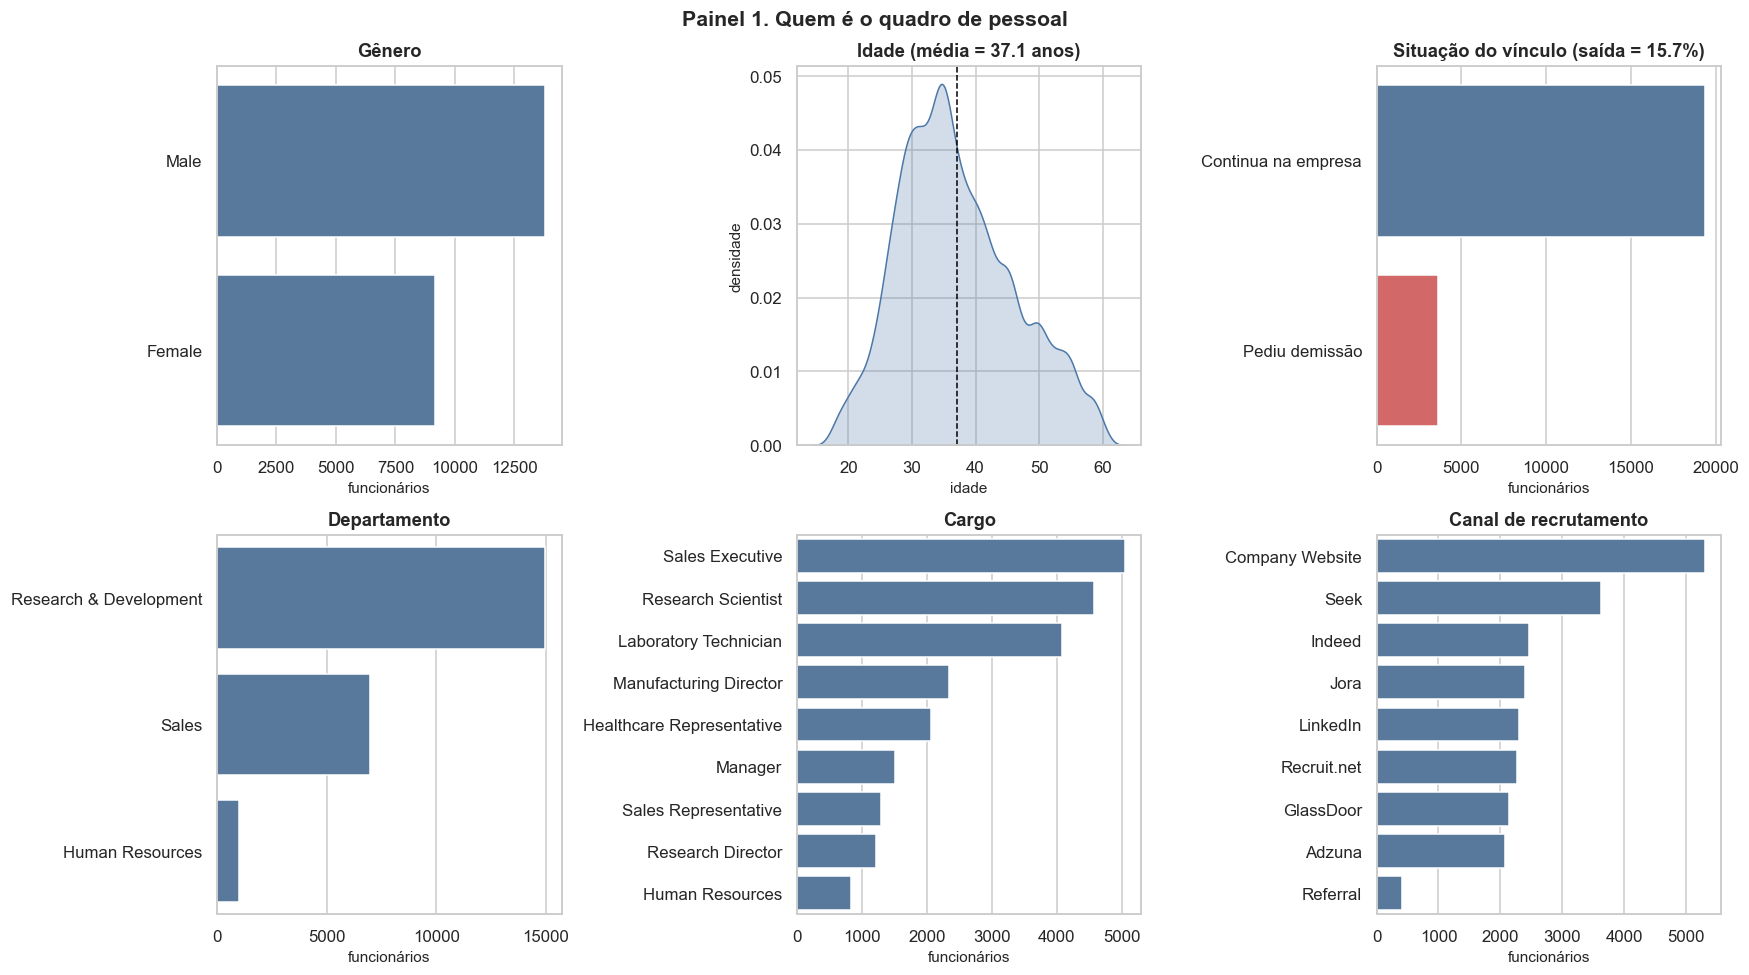

In [20]:
# plt.subplots(2, 3) cria uma grade 2x3 de eixos. 'eixos' é um array 2x2...2x3;
# .ravel() achata para uma lista simples, que é mais fácil de indexar em sequência.
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.ravel()

# --- (1) Gênero -----------------------------------------------------------
ordem_genero = base["Gender"].value_counts().index
sns.countplot(data=base, y="Gender", order=ordem_genero, ax=eixos[0], color=COR_FICOU)
eixos[0].set(title="Gênero", xlabel="funcionários", ylabel="")

# --- (2) Idade: densidade -------------------------------------------------
# kdeplot desenha a densidade (curva suavizada). 'fill=True' preenche a área.
sns.kdeplot(data=base, x="Age", fill=True, ax=eixos[1], color=COR_FICOU)
eixos[1].axvline(base["Age"].mean(), color="black", linestyle="--", linewidth=1)
eixos[1].set(title=f"Idade (média = {base['Age'].mean():.1f} anos)",
             xlabel="idade", ylabel="densidade")

# --- (3) Situação do vínculo (a variável dependente) ----------------------
sns.countplot(data=base, y="situacao", ax=eixos[2],
              order=["Continua na empresa", "Pediu demissão"],
              hue="situacao", palette=PALETA_ATRITO, legend=False)
eixos[2].set(title=f"Situação do vínculo (saída = {taxa_global:.1%})",
             xlabel="funcionários", ylabel="")

# --- (4) Departamento -----------------------------------------------------
sns.countplot(data=base, y="Department", color=COR_FICOU, ax=eixos[3],
              order=base["Department"].value_counts().index)
eixos[3].set(title="Departamento", xlabel="funcionários", ylabel="")

# --- (5) Cargo ------------------------------------------------------------
sns.countplot(data=base, y="JobRole", color=COR_FICOU, ax=eixos[4],
              order=base["JobRole"].value_counts().index)
eixos[4].set(title="Cargo", xlabel="funcionários", ylabel="")

# --- (6) Canal de recrutamento -------------------------------------------
sns.countplot(data=base, y="EmployeeSource", color=COR_FICOU, ax=eixos[5],
              order=base["EmployeeSource"].value_counts().index)
eixos[5].set(title="Canal de recrutamento", xlabel="funcionários", ylabel="")

fig.suptitle("Painel 1. Quem é o quadro de pessoal", fontsize=14, fontweight="bold")
fig.tight_layout()     # ajusta espaçamentos para os rótulos não se sobreporem
plt.show()

**Como ler o Painel 1.**

- **Gênero:** o quadro é predominantemente masculino, com cerca de 60% de homens. Isso não é um
  achado sobre atrito, é um dado de composição — e vai importar na Parte 8, porque qualquer
  comparação entre gêneros tem base desigual.
- **Idade:** distribuição aproximadamente simétrica em torno de 37 anos, com cauda à direita.
  **Não** é um quadro jovem: isso contraria a expectativa usual sobre empresas de tecnologia e
  afeta a interpretação do atrito (rotatividade de quadro maduro tem causas diferentes de
  rotatividade de quadro de entrada).
- **Situação do vínculo:** aqui se vê o desbalanceamento de 84/16 em forma gráfica. Guarde a imagem:
  ela é a razão de a acurácia ser uma métrica enganosa na Parte 9.
- **Departamento:** Research & Development concentra a maior parte do quadro; Human Resources é
  pequeno. Consequência prática: uma taxa de saída calculada para HR terá **intervalo de confiança
  largo**, porque o n é pequeno. Taxa de grupo pequeno é instável, e isso precisa ser dito sempre.
- **Cargo e canal de recrutamento:** mostram onde está o volume. Na Parte 8, as taxas serão sempre
  acompanhadas do n, justamente para que nenhuma taxa de grupo pequeno seja lida como achado.

## 7.2 O painel do tempo: seis variáveis de trajetória

Esta é a tradução direta do `grid.arrange()` do estudo original. As seis variáveis medem tempo, em
anos, mas cada uma mede um *tipo* de tempo diferente. Olhá-las juntas, na mesma escala vertical,
é o que permite ver a relação entre elas.

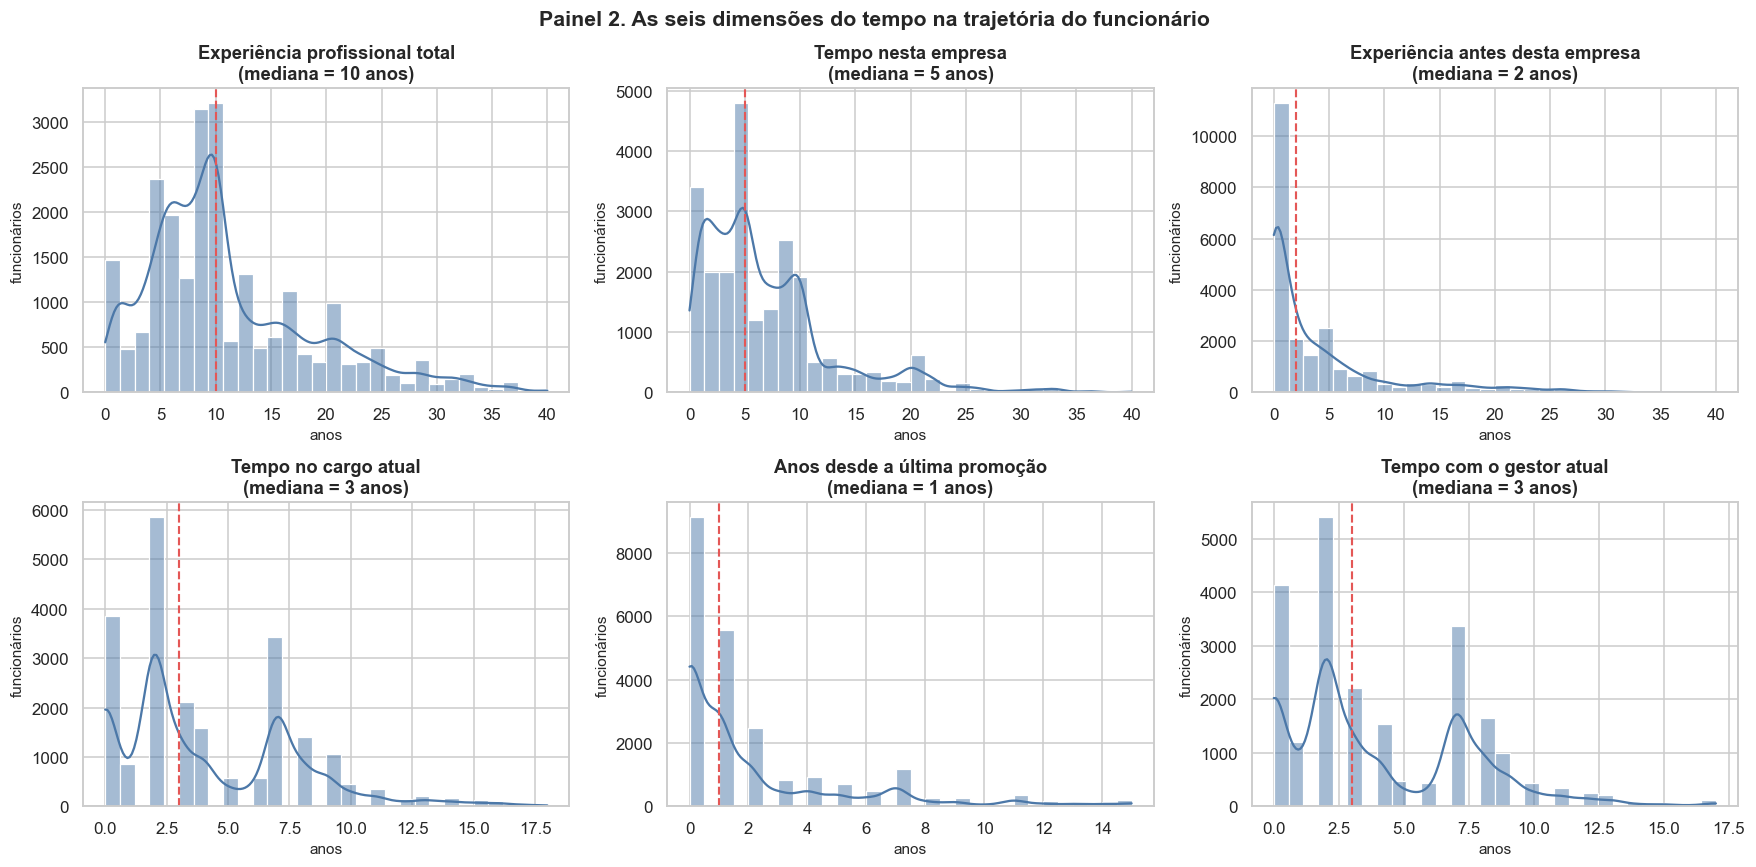

In [21]:
variaveis_tempo = [
    ("TotalWorkingYears",       "Experiência profissional total"),
    ("YearsAtCompany",          "Tempo nesta empresa"),
    ("PriorYearsOfExperience",  "Experiência antes desta empresa"),
    ("YearsInCurrentRole",      "Tempo no cargo atual"),
    ("YearsSinceLastPromotion", "Anos desde a última promoção"),
    ("YearsWithCurrManager",    "Tempo com o gestor atual"),
]

fig, eixos = plt.subplots(2, 3, figsize=(16, 8))

for eixo, (coluna, titulo) in zip(eixos.ravel(), variaveis_tempo):
    sns.histplot(data=base, x=coluna, bins=30, kde=True,    # histograma + densidade
                 color=COR_FICOU, ax=eixo, edgecolor="white")
    mediana = base[coluna].median()
    eixo.axvline(mediana, color=COR_SAIU, linestyle="--", linewidth=1.4)
    eixo.set(title=f"{titulo}\n(mediana = {mediana:.0f} anos)",
             xlabel="anos", ylabel="funcionários")

fig.suptitle("Painel 2. As seis dimensões do tempo na trajetória do funcionário",
             fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

**Como ler o Painel 2.** A linha vermelha tracejada é a mediana — usada aqui, e não a média, porque
todas essas distribuições são **assimétricas à direita** (muitos valores baixos, poucos valores
altos). Em distribuição assimétrica, a média é puxada pela cauda e descreve mal o caso típico.

Três padrões, com a leitura gerencial de cada um:

1. **Concentração em valores baixos** em `YearsAtCompany`, `YearsInCurrentRole` e
   `YearsWithCurrManager`. Muita gente com pouco tempo: quadro em expansão, ou quadro que se
   renova rápido — e as duas hipóteses se distinguem olhando a taxa de saída por faixa de tempo
   de casa (Parte 8).
2. **`YearsSinceLastPromotion` concentrada em 0 e 1**, com cauda até 15 anos. A cauda é o grupo a
   observar: quem está há muitos anos sem promoção é o perfil clássico de risco de saída, e é um
   grupo pequeno o suficiente para caber numa ação de RH.
3. **`TotalWorkingYears` com picos** em valores redondos — indício de que a informação foi
   arredondada na origem. Não impede a análise, mas é mais uma evidência de base tratada.

## 7.3 Escolaridade por área de formação

Reproduz o `facet_grid(~EducationField)` do estudo original: a mesma distribuição de escolaridade,
repetida para cada área de formação. É assim que se enxerga se o perfil educacional é homogêneo
entre as áreas ou se há áreas que concentram pós-graduação.

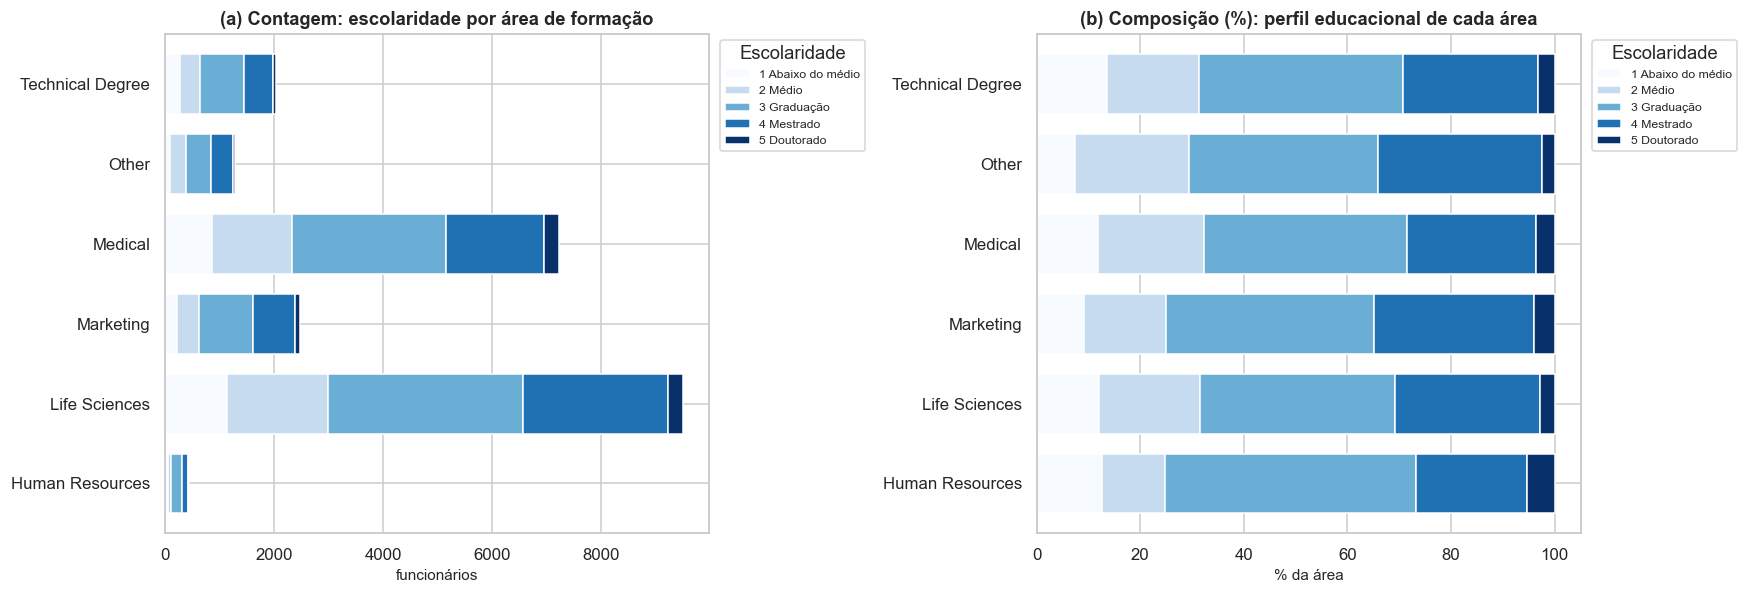

Contagem (linhas = escolaridade, colunas = área de formação):
EducationField     Human Resources  Life Sciences  Marketing  Medical  Other  Technical Degree
Education                                                                                     
1 Abaixo do médio               56           1146        226      857     96               278
2 Médio                         54           1854        393     1472    284               364
3 Graduação                    214           3571       1001     2828    471               805
4 Mestrado                      94           2656        764     1794    408               531
5 Doutorado                     24            267        100      264     32                67


In [22]:
# Tabela cruzada escolaridade x área de formação, em CONTAGEM.
# crosstab é o equivalente ao table() do R para duas variáveis.
cruzada = pd.crosstab(
    base["Education"].map(ROTULOS["Education"]),      # linhas: escolaridade rotulada
    base["EducationField"],                           # colunas: área de formação
)

fig, eixos = plt.subplots(1, 2, figsize=(16, 5.5))

# (a) Contagem absoluta: mostra onde está o VOLUME
cruzada.T.plot(kind="barh", stacked=True, ax=eixos[0], colormap="Blues", width=0.75)
eixos[0].set(title="(a) Contagem: escolaridade por área de formação",
             xlabel="funcionários", ylabel="")
eixos[0].legend(title="Escolaridade", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)

# (b) Composição percentual: mostra o PERFIL de cada área, independente do tamanho.
#     div(soma_da_linha, axis=0) divide cada célula pelo total da sua linha.
composicao = cruzada.T.div(cruzada.T.sum(axis=1), axis=0) * 100
composicao.plot(kind="barh", stacked=True, ax=eixos[1], colormap="Blues", width=0.75)
eixos[1].set(title="(b) Composição (%): perfil educacional de cada área",
             xlabel="% da área", ylabel="")
eixos[1].legend(title="Escolaridade", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)

fig.tight_layout()
plt.show()

print("Contagem (linhas = escolaridade, colunas = área de formação):")
print(cruzada.to_string())

**Por que dois gráficos para a mesma tabela.** Esta é uma lição de leitura de dados que vale para
todo o notebook: **contagem e proporção respondem perguntas diferentes, e confundi-las é o erro de
interpretação mais frequente em relatórios de RH.**

- O gráfico (a) responde: *onde está o volume de pessoas?* Serve para decidir onde uma ação de RH
  alcança mais gente.
- O gráfico (b) responde: *qual é o perfil de cada área?* Serve para comparar áreas de tamanhos
  diferentes em pé de igualdade.

Uma área pode ter o maior número absoluto de mestres (a) e, ao mesmo tempo, a menor proporção de
mestres (b), simplesmente por ser grande. Toda vez que alguém diz "a área X tem mais Y", a primeira
pergunta é: **mais em número ou mais em proporção?**

---

# Parte 8. Análise bivariada: quem sai mais?

Aqui começa o **diagnóstico**. A pergunta muda de "quem são?" para "**a taxa de saída é diferente
entre os grupos?**".

## 8.1 A ferramenta central: taxa de saída por grupo, com o n ao lado

O estudo original usa `geom_bar(position = "fill")`, que empilha as barras até 100% e deixa ler a
proporção de cada categoria. É um bom gráfico, com **um defeito grave**: ele esconde o tamanho do
grupo. Uma barra de 50% de saída construída sobre 4 pessoas aparece com o mesmo destaque visual de
uma barra de 50% construída sobre 4.000.

A função abaixo corrige isso. Para cada categoria ela devolve, sempre juntos:

- **n** — quantas pessoas há no grupo;
- **taxa de saída** — a proporção que pediu demissão;
- **diferença** em pontos percentuais em relação à taxa global da empresa;
- **intervalo de confiança de 95%** da taxa — a faixa dentro da qual a taxa verdadeira
  provavelmente está, dado o tamanho do grupo.

O intervalo de confiança é o que impede a leitura ingênua. Se o intervalo de um grupo cobre a taxa
global, **não há evidência** de que aquele grupo seja diferente da empresa como um todo, por mais
sugestivo que o número pareça.

In [23]:
def taxa_saida_por(coluna, dados_entrada=None, ordenar_por_taxa=True, min_n=0):
    """Taxa de saída voluntária por categoria, com n e intervalo de confiança de 95%.

    O intervalo usa a aproximação normal para proporção:
        p  +/-  1,96 * raiz( p * (1 - p) / n )
    que é a fórmula vista na disciplina para intervalo de confiança de proporção.
    Ela vale bem quando n*p e n*(1-p) são, ambos, maiores que ~10; por isso a
    coluna 'alerta' marca os grupos pequenos, em que o intervalo é pouco confiável.
    """
    df = base if dados_entrada is None else dados_entrada

    # groupby(...)['saiu'].agg([...]) calcula, por categoria: média (= taxa) e contagem
    agregado = (df.groupby(coluna, observed=True)["saiu"]
                  .agg(taxa="mean", n="size"))

    agregado = agregado[agregado["n"] >= min_n]

    # Erro-padrão da proporção e margem de erro de 95%
    erro_padrao = np.sqrt(agregado["taxa"] * (1 - agregado["taxa"]) / agregado["n"])
    margem = 1.96 * erro_padrao

    agregado["ic_inf"] = (agregado["taxa"] - margem).clip(lower=0)   # não existe taxa < 0
    agregado["ic_sup"] = (agregado["taxa"] + margem).clip(upper=1)   # nem taxa > 1
    agregado["dif_p.p."] = (agregado["taxa"] - df["saiu"].mean()) * 100

    # Um grupo é "diferente da empresa" quando seu IC NÃO cobre a taxa global
    taxa_ref = df["saiu"].mean()
    agregado["difere do global?"] = np.where(
        (agregado["ic_inf"] > taxa_ref) | (agregado["ic_sup"] < taxa_ref), "sim", "não")
    agregado["alerta"] = np.where(agregado["n"] < 100, "n pequeno", "")

    # Ordena pela taxa (facilita ver os extremos) ou mantém a ordem da categoria
    # (obrigatório para variáveis ORDINAIS, onde a sequência da escala é a informação)
    if ordenar_por_taxa:
        agregado = agregado.sort_values("taxa", ascending=False)

    return agregado


def grafico_taxa(coluna, titulo=None, dados_entrada=None, ordenar_por_taxa=True, eixo=None):
    """Barras horizontais da taxa de saída por categoria, com barra de erro (IC 95%)."""
    df = base if dados_entrada is None else dados_entrada
    tabela = taxa_saida_por(coluna, df, ordenar_por_taxa)
    taxa_ref = df["saiu"].mean()

    criou_figura = eixo is None
    if criou_figura:
        _, eixo = plt.subplots(figsize=(9, 0.5 * len(tabela) + 2.2))

    rotulos = [str(i) for i in tabela.index]
    posicoes = np.arange(len(tabela))

    # Barra de erro assimétrica: distância da taxa até cada limite do IC
    erros = [tabela["taxa"] - tabela["ic_inf"], tabela["ic_sup"] - tabela["taxa"]]

    eixo.barh(posicoes, tabela["taxa"] * 100, color=COR_SAIU, alpha=0.85,
              xerr=np.array(erros) * 100, error_kw=dict(ecolor="#444", lw=1, capsize=3))
    eixo.axvline(taxa_ref * 100, color="black", linestyle="--", linewidth=1.2,
                 label=f"taxa global ({taxa_ref:.1%})")
    eixo.set_yticks(posicoes, rotulos)
    eixo.invert_yaxis()                     # maior taxa no topo
    eixo.set(xlabel="taxa de saída voluntária (%)", ylabel="",
             title=titulo or f"Taxa de saída por {coluna}")
    eixo.legend(fontsize=8, loc="lower right")

    # Escreve n ao lado de cada barra: o tamanho do grupo nunca fica escondido
    for p, (_, linha) in zip(posicoes, tabela.iterrows()):
        eixo.text(linha["ic_sup"] * 100 + 0.6, p, f"n={int(linha['n']):,}".replace(",", "."),
                  va="center", fontsize=8, color="#333")

    eixo.set_xlim(0, min(100, tabela["ic_sup"].max() * 100 + 12))
    if criou_figura:
        plt.tight_layout()
        plt.show()
    return tabela


print(f"Taxa global de saída voluntária na base de modelagem: {taxa_global:.2%}")
print("Funções taxa_saida_por() e grafico_taxa() definidas.")

Taxa global de saída voluntária na base de modelagem: 15.68%
Funções taxa_saida_por() e grafico_taxa() definidas.


## 8.2 Hipótese 1 — hora extra: o fator mais forte da base

**Hipótese:** quem faz hora extra tem maior probabilidade de pedir demissão.
**Mecanismo esperado:** sobrecarga sustentada deteriora o equilíbrio trabalho-vida, que reduz a
satisfação, que aumenta a disposição a aceitar uma proposta externa.

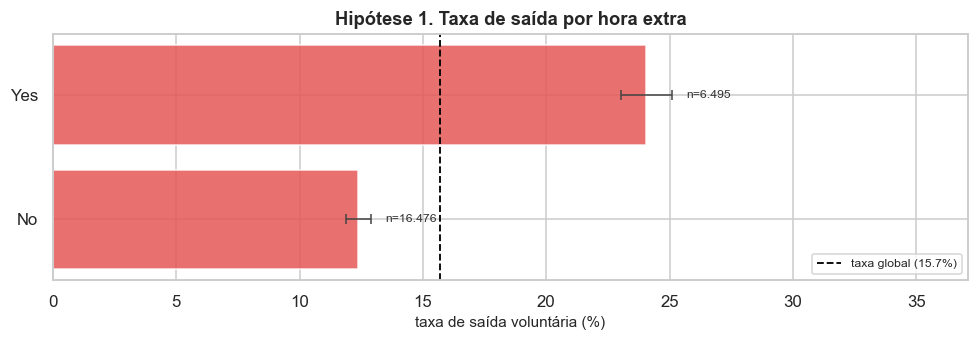

          taxa      n  ic_inf  ic_sup  dif_p.p. difere do global? alerta
OverTime                                                                
Yes      0.240   6495   0.230   0.251     8.373               sim       
No       0.124  16476   0.119   0.129    -3.301               sim       

Diferença absoluta ..... 11.7 pontos percentuais
Risco relativo ......... 1.94x (quantas vezes mais provável sair)
Razão de chances (OR) .. 2.24

As três medidas descrevem o MESMO fato e não são intercambiáveis:
  - pontos percentuais: a diferença que o RH enxerga na planilha;
  - risco relativo: quantas vezes mais provável - a linguagem da conversa;
  - razão de chances: o que a regressão logística estima (Parte 9).


In [24]:
tabela_overtime = grafico_taxa("OverTime", "Hipótese 1. Taxa de saída por hora extra")
print(tabela_overtime.round(4).to_string())

# Quantificação do efeito em duas linguagens diferentes, porque as duas serão
# usadas adiante e é importante não confundi-las:
taxa_sim = tabela_overtime.loc["Yes", "taxa"]
taxa_nao = tabela_overtime.loc["No",  "taxa"]

print(f"\nDiferença absoluta ..... {(taxa_sim - taxa_nao) * 100:.1f} pontos percentuais")
print(f"Risco relativo ......... {taxa_sim / taxa_nao:.2f}x "
      "(quantas vezes mais provável sair)")

# Razão de CHANCES (odds ratio): a medida que a regressão logística vai estimar.
# chance = p / (1 - p). A razão de chances é a chance de um grupo dividida pela do outro.
chance_sim = taxa_sim / (1 - taxa_sim)
chance_nao = taxa_nao / (1 - taxa_nao)
print(f"Razão de chances (OR) .. {chance_sim / chance_nao:.2f}")
print("\nAs três medidas descrevem o MESMO fato e não são intercambiáveis:")
print("  - pontos percentuais: a diferença que o RH enxerga na planilha;")
print("  - risco relativo: quantas vezes mais provável - a linguagem da conversa;")
print("  - razão de chances: o que a regressão logística estima (Parte 9).")

**Como ler.** A taxa de saída entre quem faz hora extra é cerca de **24%**, contra **12%** entre
quem não faz: **o dobro**. Os intervalos de confiança são estreitos (os dois grupos têm milhares de
casos) e **não se sobrepõem** — a diferença não é ruído amostral.

**Três ressalvas, que precisam andar junto com o número:**

1. **Associação, não causa.** É possível que a hora extra cause a saída. É igualmente possível que
   áreas com gestão deficiente exijam mais hora extra *e* gerem mais saídas, com a hora extra
   sendo apenas o sintoma visível. Os dados aqui não separam as duas histórias.
2. **A direção temporal não está medida.** Quem já decidiu sair pode reduzir a hora extra, ou
   aumentá-la para completar entregas antes de pedir as contas. A base não tem data, então não há
   como ordenar os eventos.
3. **`OverTime` é binária e grosseira.** "Faz hora extra" não distingue duas horas por mês de vinte
   por semana. A variável dicotômica subestima a variação real do fenômeno.

Ainda assim, **este é um dos achados mais acionáveis da base**: diferente de idade ou estado civil,
hora extra é uma variável que a empresa **controla diretamente**, via dimensionamento de equipe e
política de jornada. (Guarde este número: na Parte 9 ele vai ser recalculado *mantidas as demais
variáveis constantes*, e vai ficar **maior** — razão de chances ≈ 2,6 em vez de 2,2.)

## 8.3 Hipóteses 2 a 4 — o painel diagnóstico das variáveis categóricas

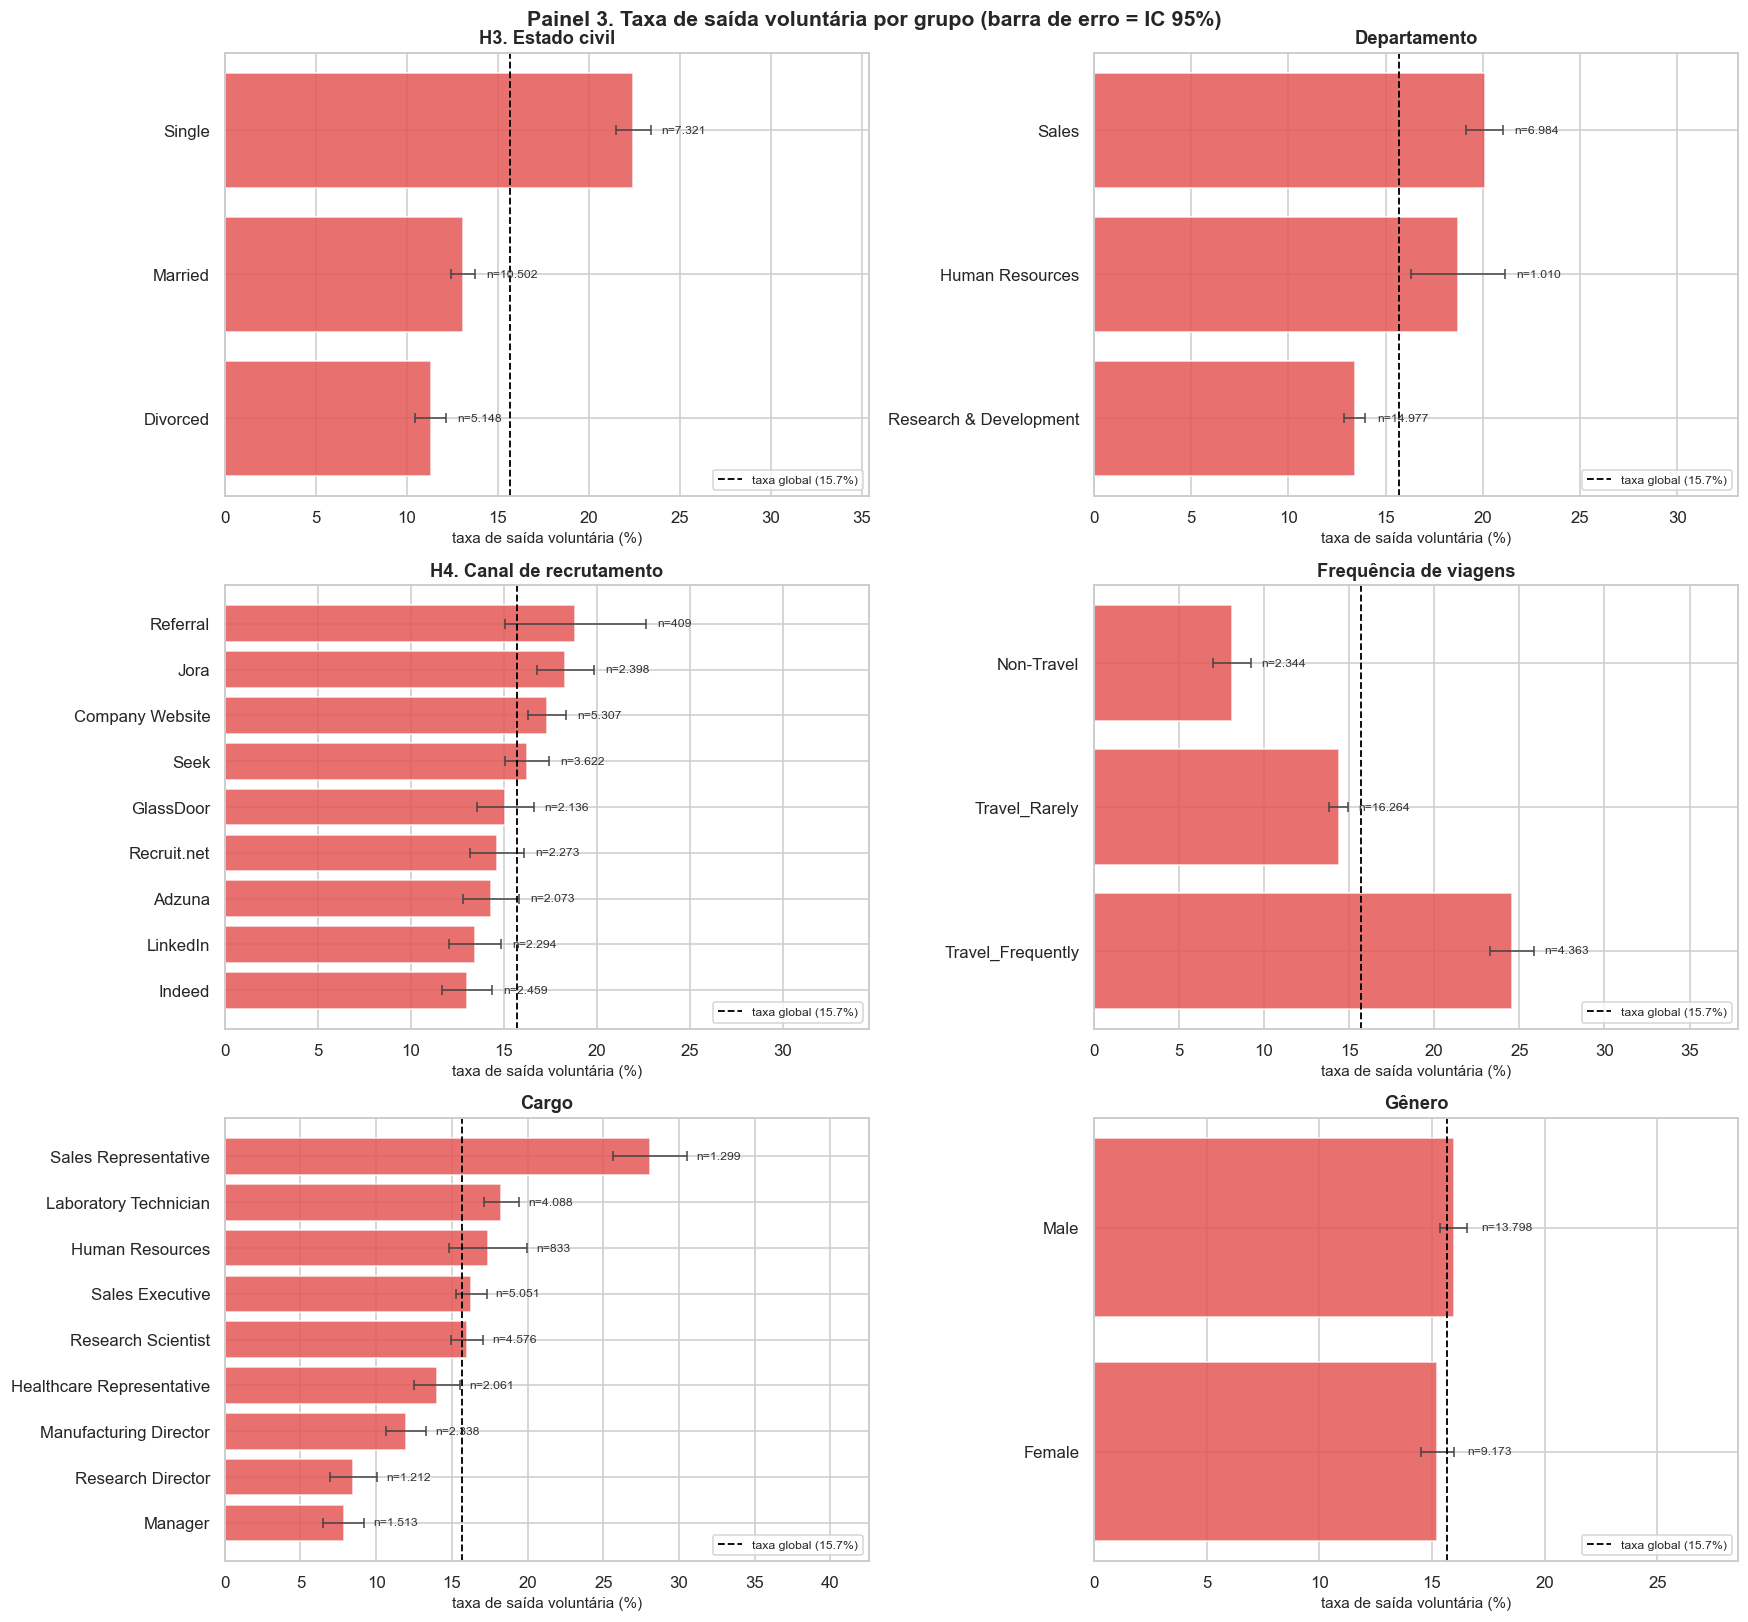

In [25]:
# Seis variáveis categóricas, cada uma em um painel, com a mesma régua visual.
painel = [
    ("MaritalStatus",  "H3. Estado civil"),
    ("Department",     "Departamento"),
    ("EmployeeSource", "H4. Canal de recrutamento"),
    ("BusinessTravel", "Frequência de viagens"),
    ("JobRole",        "Cargo"),
    ("Gender",         "Gênero"),
]

fig, eixos = plt.subplots(3, 2, figsize=(16, 15))

tabelas = {}
for eixo, (coluna, titulo) in zip(eixos.ravel(), painel):
    # BusinessTravel é ORDINAL: mantemos a ordem da escala, não a ordem da taxa
    ordenar = coluna != "BusinessTravel"
    tabelas[coluna] = grafico_taxa(coluna, titulo, ordenar_por_taxa=ordenar, eixo=eixo)

fig.suptitle("Painel 3. Taxa de saída voluntária por grupo (barra de erro = IC 95%)",
             fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

In [26]:
# As tabelas por trás do Painel 3, com os números exatos.
for coluna in ["MaritalStatus", "Department", "EmployeeSource", "BusinessTravel", "Gender"]:
    print(f"\n{'=' * 78}\n{coluna}\n{'=' * 78}")
    saida = tabelas[coluna].copy()
    saida["taxa"]   = (saida["taxa"] * 100).round(1)
    saida["ic_inf"] = (saida["ic_inf"] * 100).round(1)
    saida["ic_sup"] = (saida["ic_sup"] * 100).round(1)
    saida["dif_p.p."] = saida["dif_p.p."].round(1)
    print(saida.to_string())


MaritalStatus
                taxa      n  ic_inf  ic_sup  dif_p.p. difere do global? alerta
MaritalStatus                                                                 
Single        22.400   7321  21.500  23.400     6.800               sim       
Married       13.100  10502  12.500  13.700    -2.600               sim       
Divorced      11.300   5148  10.400  12.200    -4.400               sim       

Department
                         taxa      n  ic_inf  ic_sup  dif_p.p. difere do global? alerta
Department                                                                             
Sales                  20.100   6984  19.100  21.000     4.400               sim       
Human Resources        18.700   1010  16.300  21.100     3.000               sim       
Research & Development 13.400  14977  12.900  14.000    -2.300               sim       

EmployeeSource
                  taxa     n  ic_inf  ic_sup  dif_p.p. difere do global? alerta
EmployeeSource                            

**Como ler o Painel 3, hipótese por hipótese.**

**H3 — Estado civil (sustentada, com a interpretação invertida).** Solteiros saem a cerca de 22%,
casados a 13%, divorciados a 11%. A diferença é grande e os intervalos não se sobrepõem. Mas a
leitura correta **não** é "contratar menos solteiros" — isso seria discriminação por estado civil,
vedada, e um erro analítico, porque estado civil é aqui um **indicador indireto** de outras coisas:
idade, estágio de carreira, dependentes, custo de mudar de cidade. A conclusão útil é: *existe um
perfil de menor enraizamento, e a empresa precisa dar a ele razões para ficar* — plano de carreira
visível, por exemplo.

**Departamento.** Vendas (20%) e RH (19%) saem mais que P&D (13%). Note o n de RH: pouco mais de
mil pessoas, intervalo de confiança mais largo. A diferença de Vendas em relação a P&D é a mais
sólida, e é consistente com o que se conhece do mercado: função comercial tem mais oferta externa e
remuneração mais variável.

**H4 — Canal de recrutamento (parcialmente sustentada).** As taxas vão de ~13% (Indeed, LinkedIn)
a ~19% (indicação, Jora). Dois pontos exigem cuidado: (i) **indicação (`Referral`) tem n = 409**, o
menor grupo — o intervalo é largo e o resultado é frágil; (ii) o canal está **confundido** com o
cargo recrutado, porque canais diferentes são usados para vagas diferentes. Antes de realocar
orçamento de recrutamento, é obrigatório controlar por cargo — exatamente o que a regressão da
Parte 9 faz.

**Viagens.** O gradiente é monotônico: quem viaja com frequência sai mais. Como a variável é
ordinal e a ordem foi preservada no gráfico, esse padrão é lido de uma olhada — razão pela qual
ordinais nunca devem ser ordenadas por taxa.

**Cargo.** `Sales Representative` tem a maior taxa, com folga. É o perfil típico de entrada em
função comercial: salário de base menor, meta agressiva, alta demanda no mercado.

**Gênero.** As taxas são próximas e os intervalos se sobrepõem bastante: **não há evidência** de
diferença relevante de saída entre homens e mulheres nesta base. Este é um resultado importante
precisamente por ser nulo — e um resultado nulo deve ser reportado com o mesmo cuidado de um
positivo. Note também o que isso implica para a Parte 9: uma variável sem associação bivariada
tende a sair do modelo final, e foi por isso que o estudo original removeu `Gender` nas versões 4 e 5.

## 8.4 As escalas de satisfação e o equilíbrio trabalho-vida

Estas são variáveis do **Grupo B** (só conhecidas depois da contratação) e, por isso, as mais
diretamente ligadas a ação de gestão. São escalas ordinais: a ordem da escala é a informação, e os
gráficos preservam essa ordem.

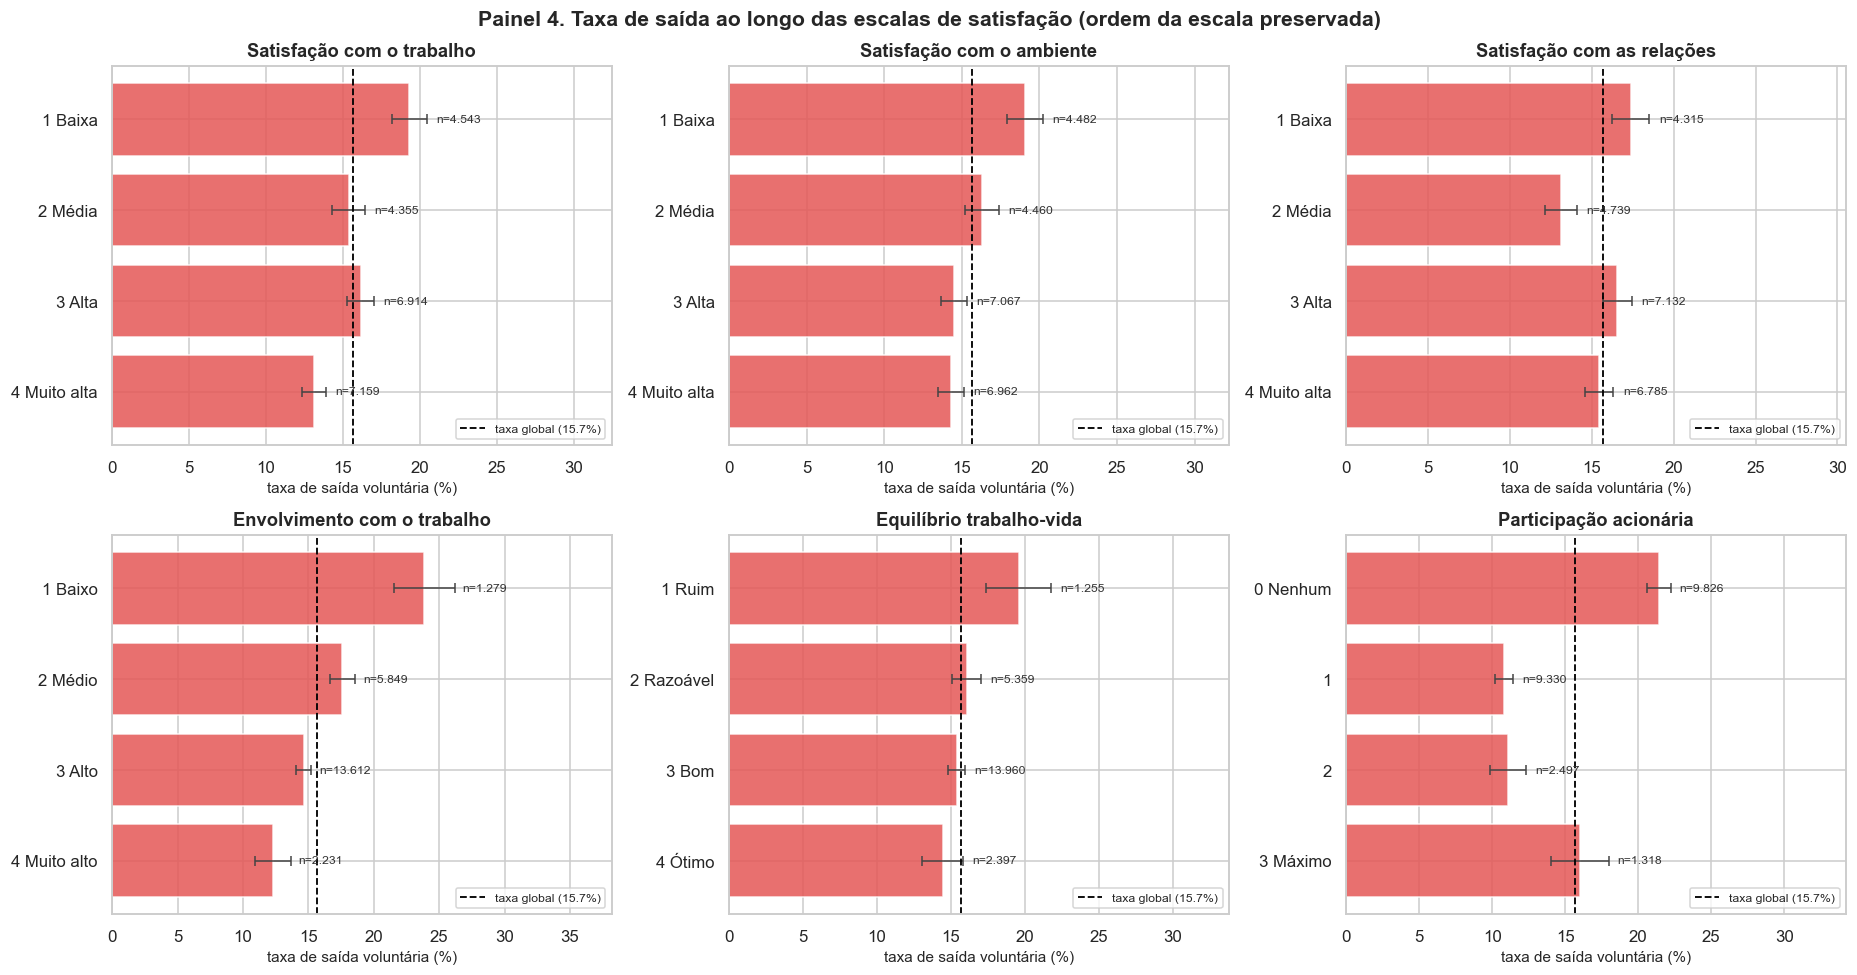

In [27]:
escalas = [
    ("JobSatisfaction",          "Satisfação com o trabalho"),
    ("EnvironmentSatisfaction",  "Satisfação com o ambiente"),
    ("RelationshipSatisfaction", "Satisfação com as relações"),
    ("JobInvolvement",           "Envolvimento com o trabalho"),
    ("WorkLifeBalance",          "Equilíbrio trabalho-vida"),
    ("StockOptionLevel",         "Participação acionária"),
]

fig, eixos = plt.subplots(2, 3, figsize=(17, 9))

for eixo, (coluna, titulo) in zip(eixos.ravel(), escalas):
    # Rotulamos a escala numa coluna temporária, para o eixo sair legível e ORDENADO
    temporaria = f"_{coluna}_rot"
    base[temporaria] = rotular(base[coluna])
    grafico_taxa(temporaria, titulo, ordenar_por_taxa=False, eixo=eixo)
    eixo.set_ylabel("")

fig.suptitle("Painel 4. Taxa de saída ao longo das escalas de satisfação (ordem da escala preservada)",
             fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

**Como ler o Painel 4.** O que se procura aqui é **monotonicidade**: a taxa cai de forma
consistente conforme a escala sobe? A resposta muda a modelagem.

- **Satisfação com o trabalho** e **satisfação com o ambiente**: gradiente claro e decrescente. Quem
  marca 1 sai bem mais que quem marca 4. Como o declínio é aproximadamente regular, tratar a escala
  como numérica no modelo é defensável — e economiza parâmetros.
- **Equilíbrio trabalho-vida**: o nível 1 se destaca com taxa muito acima dos demais, e os níveis 2,
  3 e 4 ficam próximos entre si. O padrão **não** é linear: é um *degrau*. Aqui, tratar a escala
  como numérica seria errado, porque um coeficiente único forçaria uma reta sobre um degrau. O
  tratamento correto é categórico — ou uma indicadora "equilíbrio ruim (= 1)".
- **Participação acionária**: quem tem nível 0 sai bem mais. É o efeito de retenção esperado de
  incentivo de longo prazo. Cuidado com a leitura: *stock option* é concedida a quem a empresa quer
  reter, então parte da associação é a empresa prevendo, não o incentivo causando.
- **Envolvimento** e **satisfação com as relações**: gradientes mais fracos. A associação existe, mas
  é menor — e é esperado que essas variáveis perdam significância na regressão, quando competirem
  com as mais fortes.

**A lição metodológica do painel:** a forma do gráfico decide a especificação do modelo. Satisfação
com o trabalho pede tratamento numérico; equilíbrio trabalho-vida pede tratamento categórico. Essa
decisão não se toma olhando a tabela de números — se toma olhando a forma.

## 8.5 Salário, tempo de casa e idade: as variáveis contínuas

Para variável contínua, a comparação adequada é a **distribuição** nos dois grupos, e o instrumento
é o boxplot. Lendo um boxplot: a linha do meio é a **mediana**; a caixa vai do 1º ao 3º quartil (os
50% centrais); as hastes alcançam até 1,5 vez a altura da caixa; os pontos fora são atípicos.

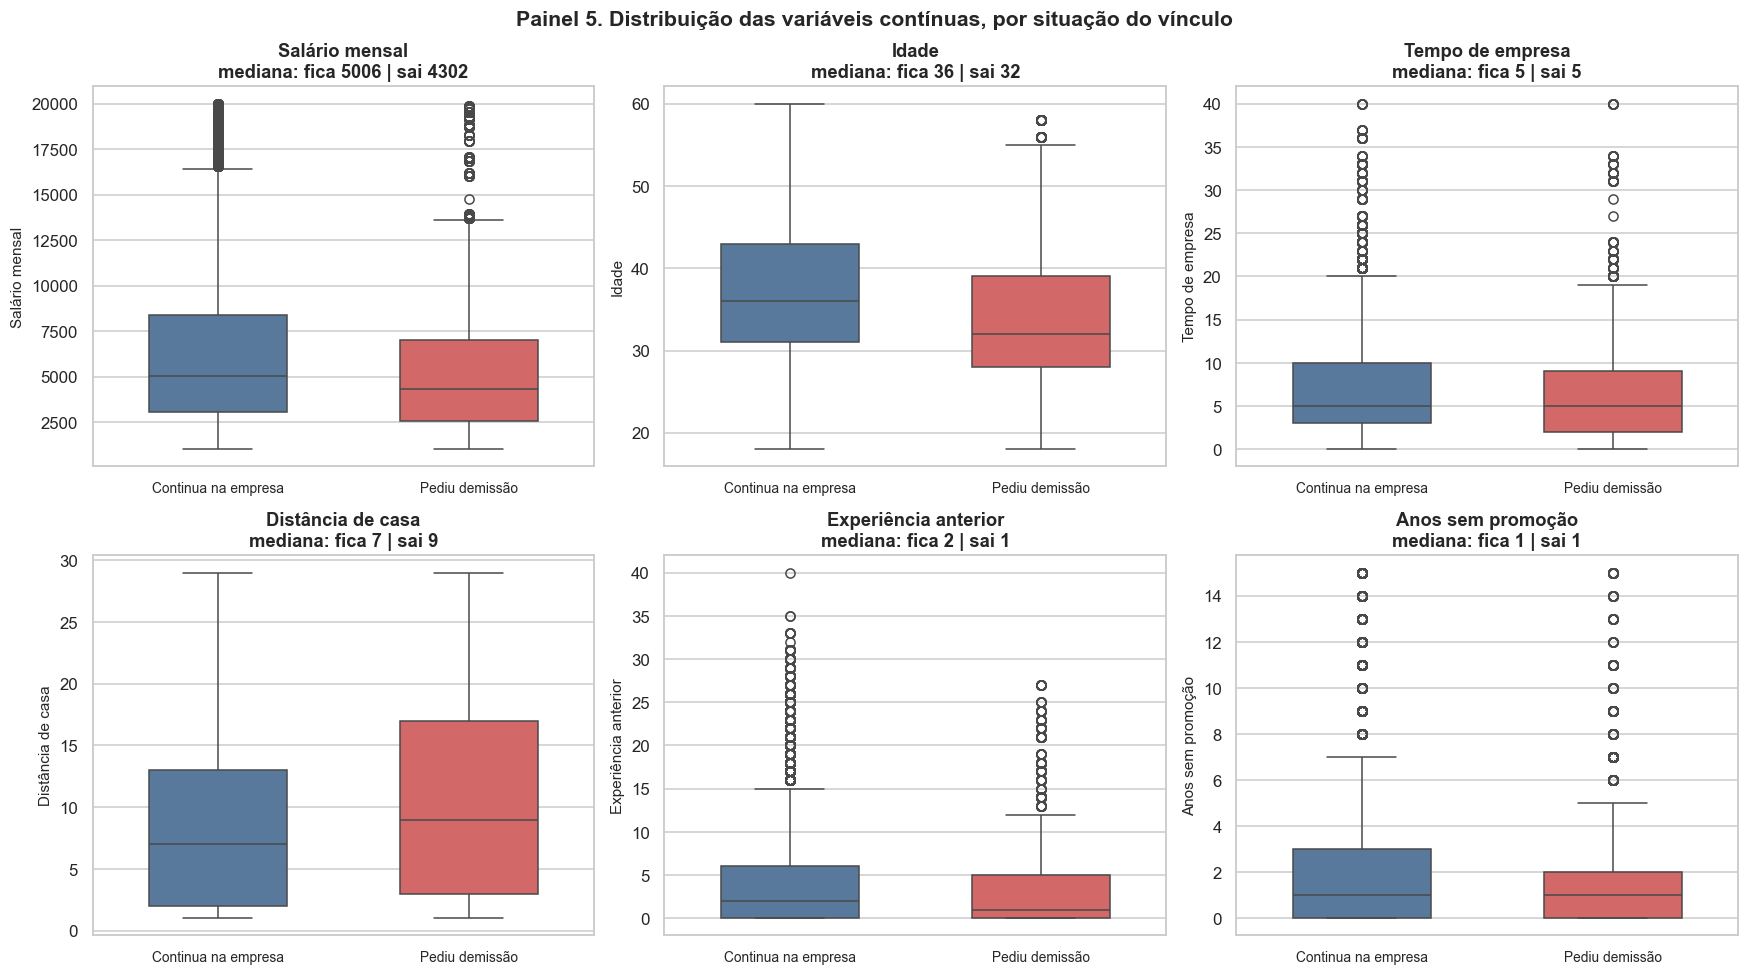

Medianas por situação do vínculo:

situacao                 Continua na empresa  Pediu demissão  dif. (%)
MonthlyIncome                      5,006.000       4,302.000   -14.100
Age                                   36.000          32.000   -11.100
YearsAtCompany                         5.000           5.000     0.000
DistanceFromHome                       7.000           9.000    28.600
PriorYearsOfExperience                 2.000           1.000   -50.000
YearsSinceLastPromotion                1.000           1.000     0.000


In [28]:
continuas = [
    ("MonthlyIncome",           "Salário mensal"),
    ("Age",                     "Idade"),
    ("YearsAtCompany",          "Tempo de empresa"),
    ("DistanceFromHome",        "Distância de casa"),
    ("PriorYearsOfExperience",  "Experiência anterior"),
    ("YearsSinceLastPromotion", "Anos sem promoção"),
]

fig, eixos = plt.subplots(2, 3, figsize=(16, 9))

for eixo, (coluna, titulo) in zip(eixos.ravel(), continuas):
    sns.boxplot(data=base, x="situacao", y=coluna, ax=eixo,
                order=["Continua na empresa", "Pediu demissão"],
                hue="situacao", palette=PALETA_ATRITO, legend=False, width=0.55)

    # Medianas dos dois grupos, no título: o número que resume a comparação
    medianas = base.groupby("situacao", observed=True)[coluna].median()
    eixo.set(title=f"{titulo}\nmediana: fica {medianas['Continua na empresa']:.0f} "
                   f"| sai {medianas['Pediu demissão']:.0f}",
             xlabel="", ylabel=titulo)
    eixo.tick_params(axis="x", labelsize=9)

fig.suptitle("Painel 5. Distribuição das variáveis contínuas, por situação do vínculo",
             fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

# A mesma comparação em números, com a diferença percentual entre as medianas
comparativo = (base.groupby("situacao", observed=True)[[c for c, _ in continuas]]
                   .median().T)
comparativo["dif. (%)"] = ((comparativo["Pediu demissão"]
                            / comparativo["Continua na empresa"] - 1) * 100).round(1)
print("Medianas por situação do vínculo:\n")
print(comparativo.to_string())

**Como ler o Painel 5.**

- **Salário:** quem pede demissão tem mediana salarial mais baixa. O efeito existe, mas é menor do
  que a intuição supõe — e há enorme sobreposição entre as caixas. Salário **não** é um
  discriminador forte isoladamente; ele age em interação com nível hierárquico e cargo.
- **Idade e tempo de empresa:** quem sai é mais jovem e tem menos tempo de casa. Consistente com o
  padrão geral de rotatividade: o risco de saída é mais alto nos primeiros anos e cai depois.
- **Distância de casa:** diferença pequena. Confirma o que o Painel 3 sugeria: esta variável tem
  pouca força nesta base.
- **Anos sem promoção:** aqui a mediana pode ser *igual* nos dois grupos, e isso mostra um limite do
  boxplot. O efeito dessa variável, se existir, está na **cauda** (quem está há muitos anos sem
  promoção), não no centro — e mediana nenhuma captura cauda. A regressão, que usa toda a
  distribuição, tem mais chance de detectá-lo.

## 8.6 Correlação entre as variáveis numéricas

A matriz de correlação cumpre aqui **duas** funções distintas, e a segunda é a que importa mais:

1. descrever quais variáveis caminham juntas;
2. **antecipar problemas de multicolinearidade na regressão**. Duas variáveis muito correlacionadas
   carregam quase a mesma informação; postas juntas num modelo, seus coeficientes ficam instáveis e
   seus erros-padrão inflam — e aí a conclusão sobre significância se torna arbitrária. É exatamente
   o que o `vif()` do estudo original testa, e que a Parte 9 vai medir.

**Atenção à medida usada:** a correlação de Pearson supõe relação linear entre variáveis
quantitativas. Para as escalas ordinais, o coeficiente abaixo é uma aproximação — a medida
apropriada seria Spearman. Rodamos Pearson para manter a comparabilidade com o estudo original, com
a ressalva declarada.

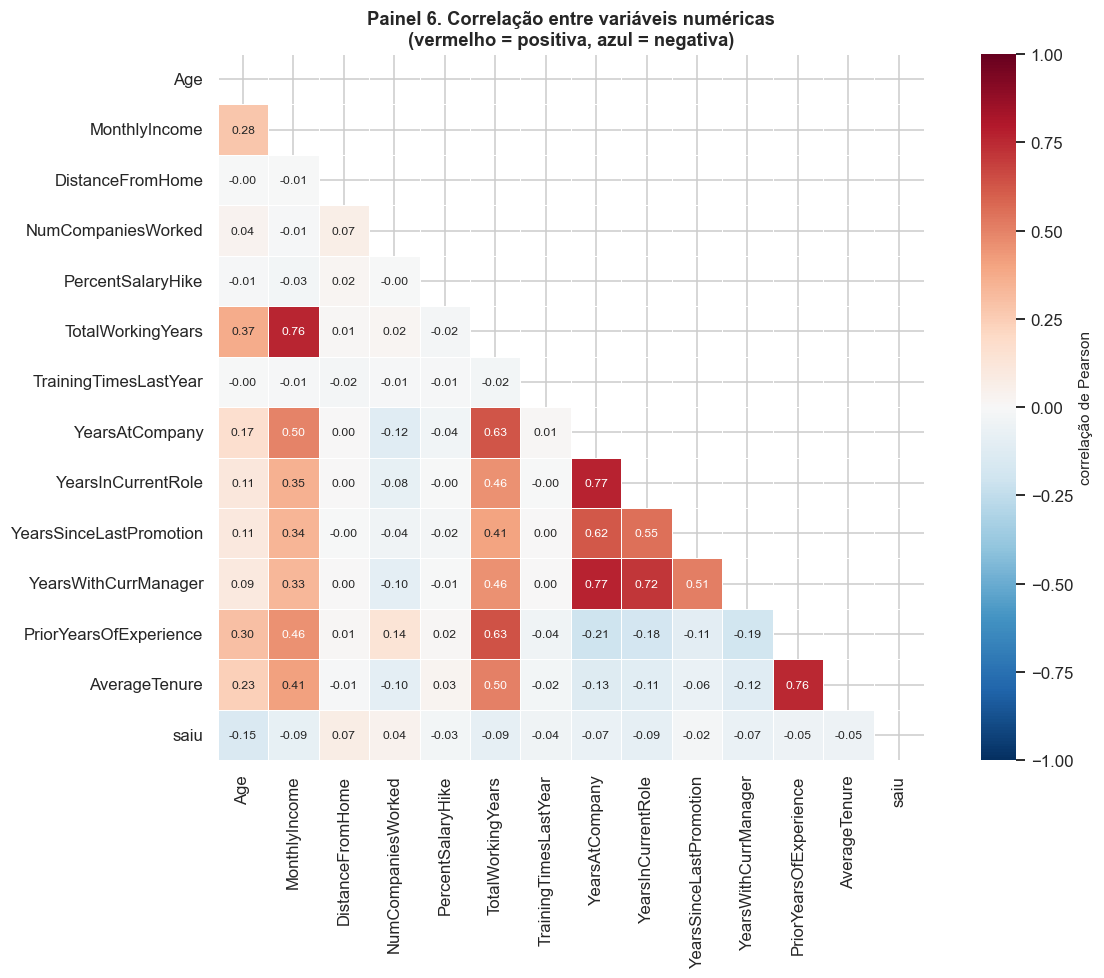

Pares com correlação alta (|r| >= 0,60) - candidatos a problema na regressão:

             variável A             variável B     r
   YearsWithCurrManager         YearsAtCompany 0.773
     YearsInCurrentRole         YearsAtCompany 0.767
      TotalWorkingYears          MonthlyIncome 0.758
          AverageTenure PriorYearsOfExperience 0.756
   YearsWithCurrManager     YearsInCurrentRole 0.717
 PriorYearsOfExperience      TotalWorkingYears 0.635
         YearsAtCompany      TotalWorkingYears 0.625
YearsSinceLastPromotion         YearsAtCompany 0.623


Correlação de cada variável com a saída (saiu = 1):

                         r com 'saiu'
Age                            -0.149
YearsInCurrentRole             -0.091
TotalWorkingYears              -0.091
MonthlyIncome                  -0.085
DistanceFromHome                0.072
YearsWithCurrManager           -0.070
YearsAtCompany                 -0.066
AverageTenure                  -0.052
PriorYearsOfExperience         -0.048
TrainingT

In [29]:
# Variáveis de contagem/intervalares (sem as escalas Likert) + a dependente binária
colunas_corr = ["Age", "MonthlyIncome", "DistanceFromHome", "NumCompaniesWorked",
                "PercentSalaryHike", "TotalWorkingYears", "TrainingTimesLastYear",
                "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion",
                "YearsWithCurrManager", "PriorYearsOfExperience", "AverageTenure", "saiu"]

matriz = base[colunas_corr].corr(method="pearson")

# np.triu() devolve a parte triangular SUPERIOR. Usada como máscara, esconde
# a metade de cima - que é espelho da de baixo e só polui a leitura.
mascara = np.triu(np.ones_like(matriz, dtype=bool))

fig, eixo = plt.subplots(figsize=(12, 9))
sns.heatmap(matriz, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"label": "correlação de Pearson"}, annot_kws={"size": 8}, ax=eixo)
eixo.set_title("Painel 6. Correlação entre variáveis numéricas\n"
               "(vermelho = positiva, azul = negativa)", fontweight="bold")
plt.tight_layout()
plt.show()

# Pares problemáticos: |r| >= 0,60 sinaliza risco de multicolinearidade
print("Pares com correlação alta (|r| >= 0,60) - candidatos a problema na regressão:\n")
pares = (matriz.where(~mascara).stack()
               .rename("r").reset_index()
               .rename(columns={"level_0": "variável A", "level_1": "variável B"}))
altos = pares[pares["r"].abs() >= 0.60].sort_values("r", key=abs, ascending=False)
print(altos.to_string(index=False) if len(altos) else "Nenhum par acima do limiar.")

print("\n\nCorrelação de cada variável com a saída (saiu = 1):\n")
print((matriz["saiu"].drop("saiu").sort_values(key=abs, ascending=False)
       .rename("r com 'saiu'").to_frame().round(3).to_string()))

**Como ler o Painel 6.**

**O bloco vermelho das variáveis de tempo** é o achado estrutural: `TotalWorkingYears`,
`YearsAtCompany`, `YearsInCurrentRole`, `YearsWithCurrManager` e `PriorYearsOfExperience` são
fortemente correlacionadas entre si. É aritmeticamente inevitável — elas medem o mesmo tempo
recortado de formas diferentes, e duas delas são *definidas* a partir das outras
(`PriorYearsOfExperience = TotalWorkingYears − YearsAtCompany`). Colocar todas no mesmo modelo é o
caminho mais curto para coeficientes sem sentido. A Parte 9 escolhe um subconjunto e justifica a
escolha.

**`TotalWorkingYears` × `MonthlyIncome`** mostra correlação positiva substantiva: experiência é
remunerada, o que é esperado e tranquilizador quanto à coerência da base.

**A última coluna — correlação com `saiu` — é modesta para todas as variáveis.** Nenhuma passa de
|r| ≈ 0,2. Isso **não** significa que não há sinal: significa que (i) a relação de uma binária com
uma contínua é mal medida por Pearson, e (ii) o atrito é **multifatorial** — nenhuma variável
isolada o explica, é a combinação que explica. É precisamente para isso que existe a regressão
multivariada da próxima parte.

---

# Parte 9. Regressão logística

## 9.1 Por que logística, e não linear

A variável dependente é **binária**: a pessoa pediu demissão (1) ou não (0). A regressão linear
comum é inadequada aqui por três razões, e não é questão de preferência:

1. Ela pode prever probabilidade **negativa** ou **maior que 1**, o que não existe.
2. Os resíduos não são normais nem têm variância constante (os pressupostos do mínimos quadrados
   falham), de modo que os erros-padrão e os valores-p saem errados.
3. A relação entre as variáveis explicativas e a probabilidade **não é linear** nos extremos:
   quando a probabilidade já está em 95%, nenhum aumento de variável a eleva muito mais.

A solução é modelar não a probabilidade, mas o **logito** — o logaritmo natural da chance:

$$\ln\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_k x_k$$

onde $p$ é a probabilidade de pedir demissão e $\frac{p}{1-p}$ é a **chance** (*odds*).

### Chance, probabilidade e razão de chances — os três termos que todo mundo confunde

| Termo | Fórmula | Exemplo com $p = 0{,}20$ | Como se fala |
|---|---|---|---|
| **Probabilidade** $p$ | — | 0,20 | "20% de chance de sair" |
| **Chance** (*odds*) | $p/(1-p)$ | $0{,}20/0{,}80 = 0{,}25$ | "1 saída para cada 4 permanências" |
| **Razão de chances** (*odds ratio*) | $\text{chance}_A/\text{chance}_B$ | — | "a chance é 2,3 vezes maior no grupo A" |

A regressão estima os $\beta$. Como o $\beta$ está na escala do logaritmo da chance, ele não é
interpretável direto: **exponencia-se** para obter a razão de chances, que é interpretável.

$$\text{razão de chances} = e^{\beta}$$

Regra de leitura, que será usada em todas as tabelas adiante:

- $e^{\beta} = 1{,}00$ → a variável não altera a chance;
- $e^{\beta} = 1{,}80$ → **aumenta a chance em 80%** em relação à categoria de referência;
- $e^{\beta} = 0{,}60$ → **reduz a chance em 40%** ($1 - 0{,}60$);
- para variável contínua, a leitura é "por cada **uma unidade** a mais" — um ano de idade, um real
  de salário. Se a unidade natural for grande (salário), convém reescalar para que o número seja
  legível.

## 9.2 Modelo 1 — foco em recrutamento (apenas variáveis do Grupo A)

Este é o modelo do estudo original, com uma correção essencial: o script em R ajusta
`glm(Attrition ~ ..., family = binomial)` sobre a base **com três categorias** de `Attrition`. Um
modelo binomial exige dependente **binária**; com três níveis, o R trata silenciosamente o primeiro
nível como 0 e todo o resto como 1, misturando demissão voluntária com desligamento — justamente o
que a Parte 1.4 mostrou não se poder misturar. Aqui o modelo é ajustado sobre `saiu`, que é binária
e cujo significado está declarado.

**Variáveis incluídas** (todas conhecidas antes da contratação): idade, departamento, distância de
casa, canal de recrutamento, cargo, estado civil, estabilidade média anterior, indicadora de
primeiro emprego, experiência anterior, gênero, escolaridade e área de formação.

**Variáveis deliberadamente excluídas, com o motivo:**

| Excluída | Motivo |
|---|---|
| `AgeStartedWorking` | É `Age − TotalWorkingYears`: colinearidade perfeita (Parte 4.7) |
| `TotalWorkingYears`, `YearsAtCompany` | `PriorYearsOfExperience` é a diferença entre as duas; as três juntas são linearmente dependentes |
| Todas as do Grupo B | Este modelo responde "o que dá para saber antes de contratar?" |

In [30]:
# ---------------------------------------------------------------------------
# A FÓRMULA. A sintaxe é a mesma do R:
#   "dependente ~ independente1 + independente2 + ..."
#   C(x) declara x como CATEGÓRICA: o patsy cria as variáveis indicadoras
#        (dummies) automaticamente e deixa a primeira categoria como REFERÊNCIA.
#   Variáveis sem C() entram como numéricas (efeito linear no logito).
# ---------------------------------------------------------------------------
formula_recrutamento = (
    "saiu ~ Age"
    " + C(Department)"
    " + DistanceFromHome"
    " + C(EmployeeSource)"
    " + C(JobRole)"
    " + C(MaritalStatus)"
    " + AverageTenure"
    " + PrimeiroEmprego"
    " + PriorYearsOfExperience"
    " + C(Gender)"
    " + C(Education)"
    " + C(EducationField)"
)

# smf.logit(formula, data).fit() ajusta por máxima verossimilhança.
# disp=0 apenas silencia o log de iterações do otimizador.
modelo_1 = smf.logit(formula_recrutamento, data=base).fit(disp=0)

print(modelo_1.summary())

                           Logit Regression Results                           
Dep. Variable:                   saiu   No. Observations:                22971
Model:                          Logit   Df Residuals:                    22935
Method:                           MLE   Df Model:                           35
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                 0.06694
Time:                        19:35:42   Log-Likelihood:                -9307.7
converged:                       True   LL-Null:                       -9975.5
Covariance Type:            nonrobust   LLR p-value:                4.845e-258
                                              coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
Intercept                                  -0.3821      0.203     -1.884      0.060      -0.780       0.015
C(Department)[T.Research & Development]    -

**Como ler a saída do `summary()`, bloco por bloco.** Esta é a tabela que o estudo em R produz, e
ela tem muita informação; vale saber onde olhar.

**Cabeçalho (ajuste global do modelo):**

| Campo | O que é | Como julgar |
|---|---|---|
| `No. Observations` | Casos usados | Deve bater com o n da base de modelagem |
| `Df Model` | Nº de parâmetros estimados (fora o intercepto) | Quanto maior, mais flexível e mais arriscado |
| `Pseudo R-squ.` | R² de McFadden | **Não** é o R² da regressão linear. Valores de 0,02 a 0,10 são comuns e aceitáveis em modelos de comportamento humano. Não compare com R² linear |
| `LLR p-value` | Teste do modelo **inteiro** contra um modelo só com intercepto | Se < 0,05, o conjunto de variáveis explica mais que o nada |
| `Log-Likelihood` | Log-verossimilhança | Serve para comparar modelos aninhados, não isoladamente |

**Tabela de coeficientes, coluna por coluna:**

| Coluna | Significado |
|---|---|
| `coef` | O $\beta$, na escala do **logito**. Sinal positivo = aumenta a chance de sair |
| `std err` | Erro-padrão do $\beta$: a incerteza da estimativa |
| `z` | $\beta$ dividido pelo erro-padrão |
| `P>|z|` | **Valor-p.** Abaixo de 0,05, rejeita-se a hipótese de que $\beta = 0$ |
| `[0.025  0.975]` | Intervalo de confiança de 95% para o $\beta$. Se contém zero, não há efeito detectado |

**Dois avisos sobre valor-p com n grande, que mudam a leitura:**

1. **Com quase 23 mil casos, quase tudo fica "significativo".** Significância estatística responde
   "o efeito é distinguível de zero?" — não responde "o efeito é grande o bastante para agir?".
   Essa segunda pergunta se responde pela **magnitude** da razão de chances, na tabela a seguir.
2. **Os nomes das linhas trazem a categoria de referência implícita.** `C(MaritalStatus)[T.Married]`
   significa "casado **comparado a** divorciado", porque `Divorced` é a primeira categoria em ordem
   alfabética e, por isso, virou a referência. Toda razão de chances categórica é lida *contra a
   referência*; sem saber qual é, o número não significa nada.

## 9.3 Razões de chances: a tabela que vai para o relatório

O `summary()` é uma saída técnica. Quem vai ler o relatório precisa da tabela abaixo: razão de
chances, intervalo de confiança da razão de chances, e a frase de interpretação já escrita.

In [31]:
def tabela_razao_chances(resultado, somente_significativos=False, alfa=0.05):
    """Converte os coeficientes do logito em razões de chances interpretáveis.

    Como o coeficiente está na escala log(chance), a razão de chances é exp(beta).
    O intervalo de confiança também é exponenciado - e o resultado é assimétrico
    em torno de 1, o que é correto e esperado.
    """
    tabela = pd.DataFrame({
        "coef (logito)": resultado.params,
        "erro padrão":   resultado.bse,
        "valor-p":       resultado.pvalues,
        "razão de chances": np.exp(resultado.params),
        "RC inf 95%":    np.exp(resultado.conf_int()[0]),
        "RC sup 95%":    np.exp(resultado.conf_int()[1]),
    })

    # Efeito em % sobre a chance: RC 1,8 -> +80% ; RC 0,6 -> -40%
    tabela["efeito na chance"] = (tabela["razão de chances"] - 1) * 100

    # Marcação visual de significância, no padrão usado em artigos
    tabela["sig"] = pd.cut(tabela["valor-p"],
                           bins=[-0.001, 0.001, 0.01, 0.05, 1],
                           labels=["***", "**", "*", ""])

    tabela = tabela.drop(index="Intercept", errors="ignore")   # intercepto não se interpreta assim

    if somente_significativos:
        tabela = tabela[tabela["valor-p"] < alfa]

    return tabela.sort_values("razão de chances", ascending=False)


rc_modelo_1 = tabela_razao_chances(modelo_1)

print("MODELO 1 - RAZÕES DE CHANCES (ordenadas da maior para a menor)")
print("Legenda: *** p<0,001   ** p<0,01   * p<0,05   (sem marca) = não significativo\n")
print(rc_modelo_1[["razão de chances", "RC inf 95%", "RC sup 95%",
                   "efeito na chance", "valor-p", "sig"]].round(3).to_string())

MODELO 1 - RAZÕES DE CHANCES (ordenadas da maior para a menor)
Legenda: *** p<0,001   ** p<0,01   * p<0,05   (sem marca) = não significativo

                                         razão de chances  RC inf 95%  RC sup 95%  efeito na chance  valor-p  sig
C(MaritalStatus)[T.Single]                          2.119       1.906       2.355           111.898    0.000  ***
C(JobRole)[T.Sales Representative]                  1.458       1.196       1.777            45.767    0.000  ***
C(EmployeeSource)[T.Referral]                       1.273       0.954       1.699            27.323    0.101     
C(JobRole)[T.Laboratory Technician]                 1.246       1.053       1.474            24.557    0.010    *
C(EducationField)[T.Technical Degree]               1.214       0.896       1.645            21.417    0.210     
C(EmployeeSource)[T.Jora]                           1.199       1.015       1.416            19.905    0.033    *
C(MaritalStatus)[T.Married]                         1.197   

In [32]:
# As dez associações mais fortes, com a frase de interpretação escrita por extenso.
# Filtramos por significância e ordenamos pela DISTÂNCIA de 1 (que é o "sem efeito"),
# porque uma RC de 0,5 é tão forte quanto uma de 2,0 - só aponta para o outro lado.
significativos = rc_modelo_1[rc_modelo_1["valor-p"] < 0.05].copy()
significativos["forca"] = (significativos["razão de chances"]
                           .apply(lambda rc: max(rc, 1 / rc)))

print("AS DEZ ASSOCIAÇÕES MAIS FORTES DO MODELO 1, EM PORTUGUÊS\n")
print("=" * 100)
for nome, linha in significativos.nlargest(10, "forca").iterrows():
    rc = linha["razão de chances"]
    direcao = "AUMENTA" if rc > 1 else "REDUZ"
    magnitude = abs(rc - 1) * 100
    print(f"\n{nome}")
    print(f"  razão de chances = {rc:.3f}  (IC 95%: {linha['RC inf 95%']:.3f} a "
          f"{linha['RC sup 95%']:.3f})   p = {linha['valor-p']:.4f}")
    print(f"  -> {direcao} a chance de pedir demissão em {magnitude:.0f}%, "
          "mantidas as demais variáveis constantes.")
print("\n" + "=" * 100)
print("\nA expressão 'mantidas as demais variáveis constantes' é o que distingue este")
print("resultado da Parte 8. Lá, a taxa por canal de recrutamento misturava o efeito do")
print("canal com o do cargo recrutado. Aqui, o efeito do canal é estimado COMPARANDO")
print("pessoas de mesmo cargo, mesmo departamento, mesma idade e mesma escolaridade.")

AS DEZ ASSOCIAÇÕES MAIS FORTES DO MODELO 1, EM PORTUGUÊS


C(MaritalStatus)[T.Single]
  razão de chances = 2.119  (IC 95%: 1.906 a 2.355)   p = 0.0000
  -> AUMENTA a chance de pedir demissão em 112%, mantidas as demais variáveis constantes.

C(JobRole)[T.Manager]
  razão de chances = 0.610  (IC 95%: 0.476 a 0.782)   p = 0.0001
  -> REDUZ a chance de pedir demissão em 39%, mantidas as demais variáveis constantes.

C(Department)[T.Research & Development]
  razão de chances = 0.648  (IC 95%: 0.530 a 0.794)   p = 0.0000
  -> REDUZ a chance de pedir demissão em 35%, mantidas as demais variáveis constantes.

C(JobRole)[T.Research Director]
  razão de chances = 0.679  (IC 95%: 0.526 a 0.875)   p = 0.0027
  -> REDUZ a chance de pedir demissão em 32%, mantidas as demais variáveis constantes.

C(JobRole)[T.Sales Representative]
  razão de chances = 1.458  (IC 95%: 1.196 a 1.777)   p = 0.0002
  -> AUMENTA a chance de pedir demissão em 46%, mantidas as demais variáveis constantes.

C(JobRole)[T.La

## 9.4 Multicolinearidade: o VIF

O estudo original chama `car::vif(modelo)` depois de cada ajuste, sem explicar o que fazer com o
número. O **VIF** (fator de inflação da variância) mede quanto o erro-padrão de um coeficiente foi
inflado pela correlação daquela variável com as outras do modelo:

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

onde $R_j^2$ é o R² da regressão da variável $j$ contra **todas as outras** explicativas.

| VIF | Leitura | Conduta |
|---|---|---|
| ≈ 1 | A variável é praticamente independente das outras | Nada a fazer |
| 1 a 5 | Correlação moderada, tolerável | Nada a fazer |
| 5 a 10 | Zona de atenção | Verificar se duas variáveis medem a mesma coisa |
| > 10 | Multicolinearidade séria | Remover uma, combinar as duas, ou mudar a especificação |

**Uma ressalva importante, que raramente se diz.** O `vif()` do R, aplicado a modelo com fatores,
devolve o **GVIF** (VIF generalizado), um valor por *variável*. Em Python, o
`variance_inflation_factor` do statsmodels opera sobre as **colunas** da matriz de desenho — ou
seja, uma linha por *dummy*. Dummies do mesmo fator são, por construção, negativamente
correlacionadas entre si, então VIFs individuais altos num mesmo fator não indicam problema. Por
isso a saída abaixo é **agrupada por variável de origem**, e o que se olha é o padrão por variável,
não a célula isolada.

In [33]:
from patsy import dmatrix       # constrói a matriz de desenho a partir da fórmula

def calcular_vif(formula, dados_entrada):
    """VIF por coluna da matriz de desenho, agregado por variável de origem."""
    # Só o lado direito da fórmula (depois do ~) entra na matriz de desenho
    lado_direito = formula.split("~")[1]
    matriz_desenho = dmatrix(lado_direito, data=dados_entrada, return_type="dataframe")

    linhas = []
    for i, coluna in enumerate(matriz_desenho.columns):
        if coluna == "Intercept":
            continue
        # variance_inflation_factor(matriz, i) devolve o VIF da coluna i
        vif = variance_inflation_factor(matriz_desenho.values, i)

        # Nome da variável de origem: "C(JobRole)[T.Manager]" -> "JobRole"
        origem = coluna.split("[")[0].replace("C(", "").replace(")", "")
        linhas.append({"coluna da matriz": coluna, "variável": origem, "VIF": vif})

    return pd.DataFrame(linhas)


vif_modelo_1 = calcular_vif(formula_recrutamento, base)

# Resumo por variável de origem: o VIF máximo entre as dummies daquela variável
resumo_vif = (vif_modelo_1.groupby("variável")
              .agg(**{"nº de colunas": ("VIF", "size"),
                      "VIF máximo":   ("VIF", "max"),
                      "VIF médio":    ("VIF", "mean")})
              .sort_values("VIF máximo", ascending=False))

resumo_vif["diagnóstico"] = pd.cut(
    resumo_vif["VIF máximo"], bins=[0, 5, 10, np.inf],
    labels=["ok", "atenção", "PROBLEMA"])

print("VIF por variável do Modelo 1\n")
print(resumo_vif.round(2).to_string())
print("\n(Para fatores com muitas categorias, VIF individual alto é esperado e não")
print(" indica problema por si: ver a ressalva sobre GVIF no texto acima.)")

VIF por variável do Modelo 1

                        nº de colunas  VIF máximo  VIF médio diagnóstico
variável                                                                
EducationField                      5      14.650      8.940    PROBLEMA
Department                          2       7.570      7.500     atenção
JobRole                             8       3.470      2.390          ok
EmployeeSource                      8       2.770      1.990          ok
Education                           4       2.740      2.210          ok
AverageTenure                       1       2.690      2.690          ok
PriorYearsOfExperience              1       2.630      2.630          ok
MaritalStatus                       2       1.700      1.680          ok
PrimeiroEmprego                     1       1.360      1.360          ok
DistanceFromHome                    1       1.300      1.300          ok
Age                                 1       1.190      1.190          ok
Gender               

**Como ler o resultado.** As variáveis contínuas e binárias ficam todas abaixo de 3 — nenhum
problema. `EducationField` aparece com VIF máximo em torno de **14,7** ("PROBLEMA") e `Department`
em torno de **7,6** ("atenção"), e as duas são exatamente os casos que a ressalva acima prevê:

- `EducationField` tem **6 categorias**, com distribuição muito concentrada (`Life Sciences` e
  `Medical` reúnem a maior parte do quadro). As indicadoras de um fator assim são fortemente
  correlacionadas entre si **por construção** — se a pessoa não é de nenhuma das outras áreas, é
  daquela. VIF de *dummy* alto, aqui, é artefato da codificação, não colinearidade substantiva.
- `Department` tem apenas 3 categorias, e `JobRole` (9 categorias) está no mesmo modelo. Cargo e
  departamento são **logicamente encaixados**: quem é `Research Scientist` está necessariamente em
  P&D. Essa é colinearidade real, e explica por que os coeficientes de departamento e de cargo
  precisam ser lidos em conjunto, nunca isoladamente.

**A conduta adotada:** manter as duas variáveis. O VIF alto infla os erros-padrão, o que torna o
teste **mais conservador** — se o coeficiente continua significativo apesar da inflação, a
conclusão é mais segura, não menos. O que *não* se pode fazer é interpretar o efeito de
departamento "mantido o cargo constante" como se fossem independentes.

## 9.5 Treino e teste: a correção do erro central do script original

**Este é o ponto mais importante da Parte 9.** O script em R faz:

```r
set.seed(2004)
index_treino <- sample.split(Y = dados_rh_1$Attrition, SplitRatio = 0.7)
dados_rh_1_treino <- subset(dados_rh_1, train = T)    # <-- o erro
dados_rh_1_teste  <- subset(dados_rh_1, train = F)    # <-- o erro
```

`sample.split()` cria corretamente o vetor `index_treino` com TRUE/FALSE. Mas as duas linhas
seguintes **não o usam**. Em `subset(dados, train = T)`, `train` não é um argumento de `subset()`
nem uma coluna da base: é ignorado silenciosamente, e `subset()` devolve a base **inteira**.
Resultado: `dados_rh_1_treino` e `dados_rh_1_teste` são **idênticos e iguais à base completa**.

A consequência: todo o desempenho reportado no estudo original é medido **nos mesmos dados em que
o modelo foi treinado**. Isso não é avaliação, é verificação de memorização — e sempre dá resultado
melhor do que a realidade. O código correto em R seria `subset(dados_rh_1, index_treino == TRUE)`.

Abaixo, a divisão feita de forma correta, com as três propriedades que uma divisão precisa ter:

1. **Aleatória**, para que os dois conjuntos sejam comparáveis;
2. **Estratificada** pela dependente (`stratify=y`), para que a proporção de 16% de saída seja a
   mesma no treino e no teste — sem isso, com classe minoritária, o sorteio pode desequilibrar;
3. **Reprodutível** (`random_state`), para que o resultado não mude a cada execução.

In [34]:
def ajustar_e_avaliar(formula, dados_entrada, rotulo, proporcao_teste=0.3, mostrar=True):
    """Divide em treino/teste, ajusta a logística e avalia FORA da amostra.

    Devolve um dicionário com o modelo ajustado, os conjuntos e as métricas.
    """
    # ---- 1. Divisão estratificada ----------------------------------------
    treino, teste = train_test_split(
        dados_entrada,
        test_size=proporcao_teste,
        random_state=SEMENTE,            # reprodutível
        stratify=dados_entrada["saiu"],  # mesma proporção de saída nos dois lados
    )

    # ---- 2. Ajuste APENAS no treino ---------------------------------------
    modelo = smf.logit(formula, data=treino).fit(disp=0)

    # ---- 3. Probabilidades previstas nos dois conjuntos -------------------
    # predict() de um logit devolve PROBABILIDADE (entre 0 e 1), não a classe.
    prob_treino = modelo.predict(treino)
    prob_teste  = modelo.predict(teste)

    # ---- 4. AUC: a métrica central para classe desbalanceada --------------
    auc_treino = roc_auc_score(treino["saiu"], prob_treino)
    auc_teste  = roc_auc_score(teste["saiu"],  prob_teste)

    if mostrar:
        print(f"=== {rotulo} ===")
        print(f"treino: {len(treino):,} casos ({treino['saiu'].mean():.2%} de saída)"
              .replace(",", "."))
        print(f"teste : {len(teste):,} casos ({teste['saiu'].mean():.2%} de saída)"
              .replace(",", "."))
        print(f"AUC no treino ........ {auc_treino:.4f}")
        print(f"AUC no teste ......... {auc_teste:.4f}")
        print(f"diferença (otimismo) . {auc_treino - auc_teste:+.4f}")

    return {"rotulo": rotulo, "modelo": modelo, "treino": treino, "teste": teste,
            "prob_treino": prob_treino, "prob_teste": prob_teste,
            "auc_treino": auc_treino, "auc_teste": auc_teste}


resultado_1 = ajustar_e_avaliar(formula_recrutamento, base,
                                "MODELO 1 - recrutamento (base completa)")

=== MODELO 1 - recrutamento (base completa) ===
treino: 16.079 casos (15.68% de saída)
teste : 6.892 casos (15.67% de saída)
AUC no treino ........ 0.6790
AUC no teste ......... 0.6913
diferença (otimismo) . -0.0123


**O que é AUC, e por que ela é a métrica desta análise.**

**AUC** é a área sob a curva ROC. Tem uma interpretação direta e muito útil:

> **AUC é a probabilidade de que, sorteando ao acaso uma pessoa que saiu e uma que ficou, o modelo
> atribua probabilidade maior à que efetivamente saiu.**

| AUC | Leitura |
|---|---|
| 0,50 | O modelo não distingue nada — equivale a sortear |
| 0,60 – 0,70 | Capacidade fraca, mas real |
| 0,70 – 0,80 | Capacidade razoável; é a faixa usual em modelos de atrito |
| 0,80 – 0,90 | Boa. Em People Analytics, desconfie e procure vazamento |
| > 0,90 | Em atrito, quase sempre indica vazamento ou duplicata |

A AUC é preferível à acurácia aqui por uma razão concreta: ela **não depende do ponto de corte** e
**não é enganada pelo desbalanceamento**. Lembre do Painel 1: prever "ninguém sai" dá 84% de
acurácia e AUC de 0,50 — a acurácia premia o modelo inútil, a AUC o reprova.

## 9.6 Medindo o vazamento das duplicatas

Agora a Parte 4.4 se paga. O mesmo modelo, a mesma fórmula, a mesma semente — mudando apenas a
base: com as 14.882 linhas repetidas, e sem elas. A diferença entre as duas AUCs de teste **é** o
tamanho do vazamento.

In [35]:
resultado_1u = ajustar_e_avaliar(formula_recrutamento, base_unica,
                                 "MODELO 1 - recrutamento (base SEM duplicatas)")

print("\n" + "=" * 78)
print("COMPARAÇÃO: o preço de não ter checado duplicatas")
print("=" * 78)

comparacao_vazamento = pd.DataFrame({
    "base completa (com repetições)": [len(base), resultado_1["auc_treino"],
                                       resultado_1["auc_teste"]],
    "base sem repetições":            [len(base_unica), resultado_1u["auc_treino"],
                                       resultado_1u["auc_teste"]],
}, index=["n de casos", "AUC treino", "AUC teste"])
print(comparacao_vazamento.round(4).to_string())

diferenca = resultado_1["auc_teste"] - resultado_1u["auc_teste"]
print(f"\nDiferença da AUC de teste (completa - sem duplicatas): {diferenca:+.4f}")
print("\nA leitura deste número vem no texto abaixo: ele NÃO saiu no sentido que a")
print("intuição sobre vazamento faria esperar, e entender por que é parte da lição.")
print("A partir daqui, o notebook usa a base SEM duplicatas.")

=== MODELO 1 - recrutamento (base SEM duplicatas) ===
treino: 5.699 casos (16.11% de saída)
teste : 2.443 casos (16.09% de saída)
AUC no treino ........ 0.6925
AUC no teste ......... 0.6962
diferença (otimismo) . -0.0037

COMPARAÇÃO: o preço de não ter checado duplicatas
            base completa (com repetições)  base sem repetições
n de casos                      22,971.000            8,142.000
AUC treino                           0.679                0.693
AUC teste                            0.691                0.696

Diferença da AUC de teste (completa - sem duplicatas): -0.0049

A leitura deste número vem no texto abaixo: ele NÃO saiu no sentido que a
intuição sobre vazamento faria esperar, e entender por que é parte da lição.
A partir daqui, o notebook usa a base SEM duplicatas.


**Como ler este resultado, que saiu ao contrário do esperado.**

A AUC de teste com a base completa (≈ 0,691) ficou **ligeiramente abaixo** da AUC com a base sem
duplicatas (≈ 0,696). A diferença é de cerca de −0,005: **não há superestimação detectável** aqui.
Reportar isso é obrigatório — um notebook que só mostra o resultado quando ele confirma a tese não
está ensinando método, está ensinando a selecionar evidência.

Por que o vazamento não apareceu nesta medida? Três razões, e as três são instrutivas:

1. **A replicação foi aproximadamente proporcional**, como a tabela da Parte 4.4 mostrou. As cópias
   não se concentraram num perfil específico, então o modelo não ganhou nada em "reconhecer" linhas
   repetidas que seguiam o mesmo padrão geral.
2. **A regressão logística é um modelo rígido.** Ela tem um coeficiente por variável e não consegue
   memorizar casos individuais, por mais vezes que eles apareçam. Repetir uma linha mil vezes muda
   o *peso* dela na estimação, não dá ao modelo a capacidade de decorá-la.
3. **A base sem duplicatas é menor** (8.142 contra 22.971 casos), então sua AUC tem mais variação
   amostral. Diferenças dessa ordem estão dentro do ruído de uma única divisão treino/teste.

**O que isso não autoriza a concluir.** Não conclua que duplicatas são inofensivas. A conclusão
correta é mais específica: *duplicatas proporcionais não enganam um modelo rígido*. Com um modelo
**flexível**, capaz de memorizar casos individuais, o resultado é radicalmente diferente — e a
Parte 10.3 mostra exatamente isso acontecendo, com a mesma base: uma árvore sem poda chega a
acerto **perfeito** nas linhas que tinham cópia no treino.

## 9.7 Modelo 2 — foco em gestão (Grupos A + B)

O Modelo 1 responde "o que dá para saber antes de contratar?". Esta é a pergunta do estudo
original, e é legítima. Mas a Parte 8 mostrou que as variáveis mais fortemente associadas ao atrito
são do **Grupo B**: hora extra, satisfação, equilíbrio trabalho-vida, participação acionária. São
elas que respondem à pergunta que o RH realmente faz — **"o que eu faço a respeito?"**.

O Modelo 2 acrescenta o Grupo B. Duas decisões de especificação, com a justificativa:

- **`np.log(MonthlyIncome)`** em vez do salário bruto. Razão: o efeito de R$ 500 a mais é enorme
  para quem ganha 2.000 e irrelevante para quem ganha 18.000. O logaritmo torna o coeficiente
  interpretável em termos **relativos** (efeito de um aumento percentual), que é como política
  salarial funciona.
- **`C(WorkLifeBalance)`** (categórica) e `JobSatisfaction` (numérica). Razão: o Painel 4 mostrou
  que o equilíbrio trabalho-vida tem padrão de **degrau** (só o nível 1 se destaca) e a satisfação
  com o trabalho tem padrão **gradiente** (declínio regular). A forma do dado decide a forma do
  modelo — não o contrário.

In [36]:
formula_gestao = (
    "saiu ~ Age"
    # --- Grupo A: conhecidas antes de contratar -------------------------
    " + C(Department) + DistanceFromHome + C(EmployeeSource) + C(JobRole)"
    " + C(MaritalStatus) + AverageTenure + PrimeiroEmprego + PriorYearsOfExperience"
    " + C(Gender) + C(Education) + C(EducationField)"
    # --- Grupo B: só conhecidas depois de contratar ----------------------
    " + C(OverTime)"                     # a variável mais forte da Parte 8
    " + C(BusinessTravel)"
    " + np.log(MonthlyIncome)"           # efeito relativo, não absoluto
    " + C(JobLevel)"
    " + C(StockOptionLevel)"
    " + JobSatisfaction"                 # gradiente: entra como numérica
    " + EnvironmentSatisfaction"
    " + RelationshipSatisfaction"
    " + JobInvolvement"
    " + C(WorkLifeBalance)"              # degrau: entra como categórica
    " + TrainingTimesLastYear"
    " + YearsAtCompany"
    " + YearsSinceLastPromotion"
    " + YearsWithCurrManager"
    " + PercentSalaryHike"
)

resultado_2 = ajustar_e_avaliar(formula_gestao, base_unica,
                                "MODELO 2 - gestão (Grupos A + B, base sem duplicatas)")

print("\n" + "=" * 78)
print("O QUE AS VARIÁVEIS DO GRUPO B ACRESCENTAM")
print("=" * 78)
print(f"AUC teste - Modelo 1 (só Grupo A) ..... {resultado_1u['auc_teste']:.4f}")
print(f"AUC teste - Modelo 2 (Grupos A + B) ... {resultado_2['auc_teste']:.4f}")
print(f"ganho ................................. "
      f"{resultado_2['auc_teste'] - resultado_1u['auc_teste']:+.4f}")

=== MODELO 2 - gestão (Grupos A + B, base sem duplicatas) ===
treino: 5.699 casos (16.11% de saída)
teste : 2.443 casos (16.09% de saída)
AUC no treino ........ 0.7681
AUC no teste ......... 0.7451
diferença (otimismo) . +0.0230

O QUE AS VARIÁVEIS DO GRUPO B ACRESCENTAM
AUC teste - Modelo 1 (só Grupo A) ..... 0.6962
AUC teste - Modelo 2 (Grupos A + B) ... 0.7451
ganho ................................. +0.0490


In [37]:
# As razões de chances do Modelo 2, só as significativas, ordenadas por força.
rc_modelo_2 = tabela_razao_chances(resultado_2["modelo"], somente_significativos=True)
rc_modelo_2["forca"] = rc_modelo_2["razão de chances"].apply(lambda rc: max(rc, 1 / rc))

print("MODELO 2 - FATORES SIGNIFICATIVOS (p < 0,05), ordenados por força da associação\n")
colunas_mostrar = ["razão de chances", "RC inf 95%", "RC sup 95%",
                   "efeito na chance", "valor-p", "sig"]
print(rc_modelo_2.sort_values("forca", ascending=False)[colunas_mostrar]
      .round(3).to_string())

MODELO 2 - FATORES SIGNIFICATIVOS (p < 0,05), ordenados por força da associação

                                        razão de chances  RC inf 95%  RC sup 95%  efeito na chance  valor-p  sig
C(BusinessTravel)[T.Travel_Frequently]             3.874       2.768       5.421           287.366    0.000  ***
C(OverTime)[T.Yes]                                 2.572       2.186       3.025           157.197    0.000  ***
C(JobRole)[T.Research Director]                    0.484       0.265       0.884           -51.551    0.018    *
C(JobRole)[T.Research Scientist]                   0.488       0.312       0.762           -51.212    0.002   **
C(StockOptionLevel)[T.1]                           0.566       0.445       0.720           -43.418    0.000  ***
C(BusinessTravel)[T.Travel_Rarely]                 1.752       1.282       2.393            75.186    0.000  ***
C(StockOptionLevel)[T.2]                           0.615       0.444       0.850           -38.532    0.003   **
C(JobLevel)[T.2

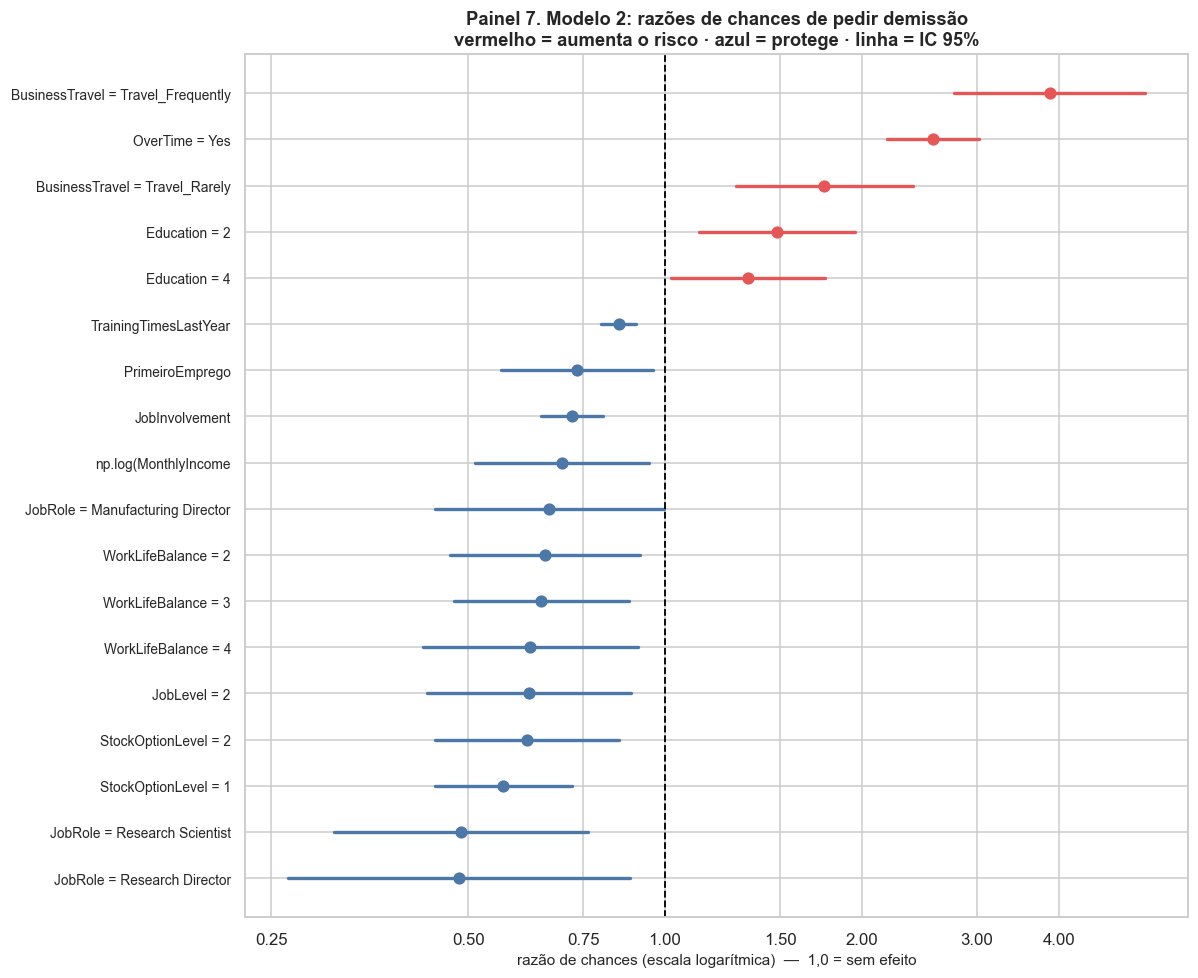

In [38]:
# Gráfico de floresta (forest plot): a forma padrão de apresentar razões de chances.
# Escala logarítmica no eixo x, porque RC é uma razão: 0,5 e 2,0 devem ficar
# à mesma distância de 1,0 - e só o log faz isso.
top = rc_modelo_2.sort_values("forca", ascending=False).head(18).sort_values("razão de chances")

fig, eixo = plt.subplots(figsize=(11, 9))

for i, (nome, linha) in enumerate(top.iterrows()):
    cor = COR_SAIU if linha["razão de chances"] > 1 else COR_FICOU
    eixo.plot([linha["RC inf 95%"], linha["RC sup 95%"]], [i, i], color=cor, lw=2.2)
    eixo.plot(linha["razão de chances"], i, "o", color=cor, markersize=7)

eixo.axvline(1, color="black", linestyle="--", lw=1.2)
eixo.set_xscale("log")
eixo.set_xticks([0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4])
eixo.get_xaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
eixo.set_yticks(range(len(top)),
                [n.replace("C(", "").replace(")", "").replace("[T.", " = ").replace("]", "")
                 for n in top.index], fontsize=9)
eixo.set(xlabel="razão de chances (escala logarítmica)  —  1,0 = sem efeito",
         ylabel="",
         title="Painel 7. Modelo 2: razões de chances de pedir demissão\n"
               "vermelho = aumenta o risco · azul = protege · linha = IC 95%")
plt.tight_layout()
plt.show()

**Como ler o Painel 7 (gráfico de floresta).** Cada linha é uma variável (ou uma categoria de
variável). O ponto é a razão de chances estimada; a linha é o intervalo de confiança de 95%. A
linha tracejada vertical em 1,0 é o "sem efeito". **Se o intervalo cruza a linha de 1,0, não há
efeito detectado** — e é por isso que o gráfico só traz os significativos.

Os achados centrais, com a leitura gerencial:

- **Viajar com frequência é o fator mais forte do modelo** (razão de chances ≈ 3,9 contra quem não
  viaja; viajar raramente, ≈ 1,8). Esse achado **não** aparecia com essa força na Parte 8, onde a
  tabela de `BusinessTravel` mostrava um gradiente modesto. A diferença é o efeito do controle:
  quem viaja muito também tende a ter cargo, nível e salário mais altos — e esses atributos
  *protegem*. Quando o modelo os mantém constantes, o efeito da viagem em si aparece inteiro. É a
  demonstração mais clara, em todo o notebook, de por que a análise bivariada não basta.
- **Hora extra** vem em segundo (≈ 2,6), e é o achado mais acionável. Mesmo **controlando** por
  salário, cargo, nível, satisfação e tempo de casa, quem faz hora extra tem chance muito maior de
  pedir demissão. O controle é o que dá força ao achado: não é "quem faz hora extra ganha menos e
  por isso sai" — o efeito persiste a salário igual.
- **Salário (em log)** tem razão de chances abaixo de 1 (≈ 0,70): salário maior **protege**. Lido
  na escala relativa: é o efeito de um aumento proporcional, não de R$ 1.
- **Participação acionária** acima de zero protege (níveis 1 e 2 com RC ≈ 0,57 e 0,62).
- **Equilíbrio trabalho-vida**: os níveis 2, 3 e 4 têm razão de chances em torno de 0,62–0,66 em
  relação ao nível 1 (a referência), e muito próximas entre si. Confirma o *degrau* visto no
  Painel 4 — o problema está concentrado em quem avalia o equilíbrio como ruim, e subir de 2 para
  4 agrega pouco.
- **Satisfação com o trabalho, com o ambiente e envolvimento** protegem, com gradiente regular
  (RC entre 0,72 e 0,86 por ponto da escala). **Treinamentos no último ano** também protegem
  (≈ 0,85 por treinamento) — um dos poucos instrumentos de retenção de custo baixo.
- **Idade** protege de forma consistente (≈ 0,95 por ano), e **distância de casa** tem efeito
  pequeno mas detectável (≈ 1,02 por milha): com n grande, efeitos pequenos ficam significativos,
  o que reforça o aviso da Parte 9.2 sobre não confundir significância com relevância.
- **Estado civil perde a significância neste modelo.** No Modelo 1, "solteiro" tinha razão de
  chances de 2,1; aqui, com as variáveis do Grupo B no modelo, o efeito desaparece. A leitura é
  substantiva: aquilo que o estado civil *indicava* — perfil de menor enraizamento — está agora
  medido diretamente por idade, nível, salário, satisfação e hora extra. O indicador indireto
  perde função quando se mede a coisa em si. E isso reforça a conclusão da Parte 8.3: estado civil
  nunca deveria orientar decisão sobre pessoas.
- **Gênero continua sem efeito detectável** — resultado nulo, consistente com a Parte 8.3.
  **Escolaridade**, ao contrário do esperado, mantém dois níveis significativos (ensino médio e
  mestrado, com RC ≈ 1,48 e 1,34 contra a referência), mas sem padrão monotônico. Efeito sem forma
  interpretável, em variável com seis níveis e muitos testes: o tratamento honesto é registrar
  como achado frágil, a confirmar, e não construir recomendação sobre ele.

## 9.8 Avaliando a classificação: matriz de confusão e o ponto de corte

Até aqui o modelo produziu **probabilidades**. Para transformar probabilidade em decisão
("colocar esta pessoa na lista de conversa?") é preciso um **ponto de corte** (*threshold*).

O estudo original usa `threshold <- 0.5`. Com 84% de permanências, 0,5 é uma escolha péssima:
quase ninguém alcança probabilidade acima de 0,5, então o modelo classifica quase todo mundo como
"fica" e o *recall* da classe que interessa fica perto de zero. A célula abaixo demonstra o
problema e mostra como escolher o corte com critério.

**As quatro casas da matriz de confusão, nomeadas em termos de RH:**

|  | Previu "fica" | Previu "sai" |
|---|---|---|
| **Ficou** | Acerto | **Falso alarme** — o RH conversa com quem não ia sair (custo: tempo) |
| **Saiu** | **Perda silenciosa** — ninguém foi avisado (custo: a pessoa vai embora) | Acerto |

Os dois erros **não** custam o mesmo. Uma conversa desnecessária custa uma hora de gestor; perder
um analista sênior custa meses de recrutamento e treinamento. Logo, o corte ótimo **não** é 0,5 —
é aquele que equilibra os dois custos conforme a realidade da empresa.

In [39]:
teste_2  = resultado_2["teste"]
prob_2   = resultado_2["prob_teste"]
y_real   = teste_2["saiu"].values

def avaliar_corte(y_verdadeiro, probabilidades, corte):
    """Matriz de confusão e métricas para um ponto de corte específico."""
    previsto = (probabilidades >= corte).astype(int)
    # confusion_matrix devolve [[VN, FP], [FN, VP]] na ordem dos rótulos [0, 1]
    vn, fp, fn, vp = confusion_matrix(y_verdadeiro, previsto, labels=[0, 1]).ravel()
    return {
        "corte": corte,
        "previu que sai (n)": vp + fp,
        "acertou quem saiu (VP)": vp,
        "falso alarme (FP)": fp,
        "perda silenciosa (FN)": fn,
        "recall": vp / (vp + fn) if (vp + fn) else 0,       # % dos que saíram que foram pegos
        "precisão": vp / (vp + fp) if (vp + fp) else 0,     # % dos avisos que estavam certos
        "acurácia": (vp + vn) / len(y_verdadeiro),
    }

# --- O corte 0,5 do estudo original ---------------------------------------
print("=== PONTO DE CORTE 0,50 (o do script em R) ===\n")
m = avaliar_corte(y_real, prob_2, 0.50)
previsto_050 = (prob_2 >= 0.50).astype(int)
matriz = pd.DataFrame(
    confusion_matrix(y_real, previsto_050, labels=[0, 1]),
    index=["REAL: ficou", "REAL: saiu"],
    columns=["PREVISTO: fica", "PREVISTO: sai"])
print(matriz.to_string())
print(f"\nacurácia  {m['acurácia']:.1%}   <- parece ótimo...")
print(f"recall    {m['recall']:.1%}   <- ...mas pegou esta fração de quem saiu")
print(f"precisão  {m['precisão']:.1%}")
print(f"\nTaxa de saída no teste: {y_real.mean():.1%}. Um modelo que dissesse 'ninguém sai'")
print(f"teria acurácia de {1 - y_real.mean():.1%} - compare com a acurácia acima.")
print("É por isso que acurácia não serve como métrica principal aqui.")

# --- Varredura de cortes ---------------------------------------------------
print("\n\n=== O QUE ACONTECE AO VARIAR O PONTO DE CORTE ===\n")
varredura = pd.DataFrame([avaliar_corte(y_real, prob_2, c)
                          for c in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]])
print(varredura.round(3).to_string(index=False))

=== PONTO DE CORTE 0,50 (o do script em R) ===

             PREVISTO: fica  PREVISTO: sai
REAL: ficou            2011             39
REAL: saiu              334             59

acurácia  84.7%   <- parece ótimo...
recall    15.0%   <- ...mas pegou esta fração de quem saiu
precisão  60.2%

Taxa de saída no teste: 16.1%. Um modelo que dissesse 'ninguém sai'
teria acurácia de 83.9% - compare com a acurácia acima.
É por isso que acurácia não serve como métrica principal aqui.


=== O QUE ACONTECE AO VARIAR O PONTO DE CORTE ===

 corte  previu que sai (n)  acertou quem saiu (VP)  falso alarme (FP)  perda silenciosa (FN)  recall  precisão  acurácia
 0.100                1364                     318               1046                     75   0.809     0.233     0.541
 0.150                 966                     278                688                    115   0.707     0.288     0.671
 0.200                 701                     247                454                    146   0.628     0

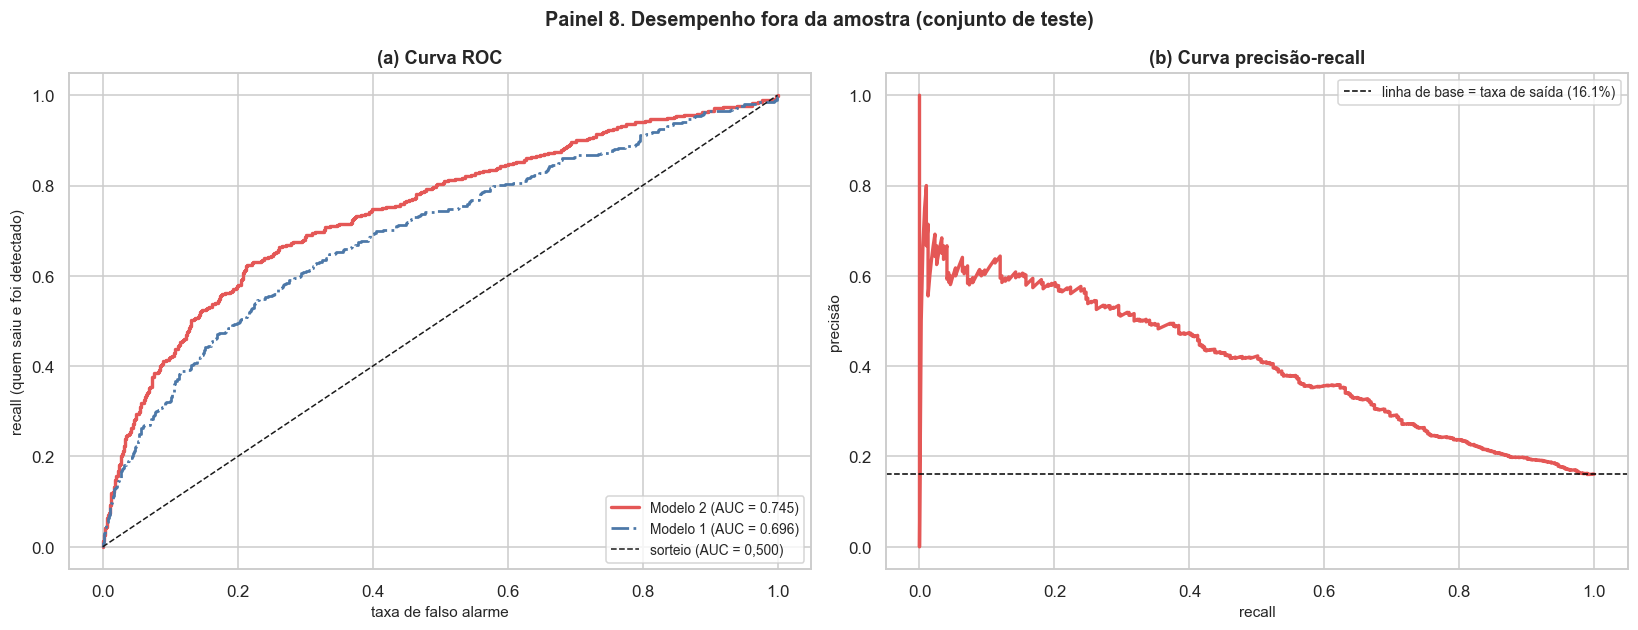

In [40]:
# Curvas de diagnóstico: ROC e precisão-recall, lado a lado.
fig, eixos = plt.subplots(1, 2, figsize=(15, 5.8))

# --- (a) Curva ROC --------------------------------------------------------
# roc_curve devolve, para TODOS os cortes possíveis:
#   fpr = taxa de falso positivo (falsos alarmes / quem ficou)
#   tpr = taxa de verdadeiro positivo (= recall)
fpr, tpr, _ = roc_curve(y_real, prob_2)
auc = resultado_2["auc_teste"]

eixos[0].plot(fpr, tpr, color=COR_SAIU, lw=2.2, label=f"Modelo 2 (AUC = {auc:.3f})")

# A mesma curva para o Modelo 1, para comparar
fpr1, tpr1, _ = roc_curve(resultado_1u["teste"]["saiu"], resultado_1u["prob_teste"])
eixos[0].plot(fpr1, tpr1, color=COR_FICOU, lw=1.8, linestyle="-.",
              label=f"Modelo 1 (AUC = {resultado_1u['auc_teste']:.3f})")

eixos[0].plot([0, 1], [0, 1], "k--", lw=1, label="sorteio (AUC = 0,500)")
eixos[0].set(xlabel="taxa de falso alarme", ylabel="recall (quem saiu e foi detectado)",
             title="(a) Curva ROC")
eixos[0].legend(loc="lower right", fontsize=9)

# --- (b) Curva precisão-recall -------------------------------------------
# Para classe desbalanceada, esta curva é mais informativa que a ROC:
# ela ignora os verdadeiros negativos, que são a maioria esmagadora.
precisao, recall, cortes = precision_recall_curve(y_real, prob_2)
eixos[1].plot(recall, precisao, color=COR_SAIU, lw=2.2)
eixos[1].axhline(y_real.mean(), color="black", linestyle="--", lw=1,
                 label=f"linha de base = taxa de saída ({y_real.mean():.1%})")
eixos[1].set(xlabel="recall", ylabel="precisão", title="(b) Curva precisão-recall")
eixos[1].legend(fontsize=9)

fig.suptitle("Painel 8. Desempenho fora da amostra (conjunto de teste)",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

**Como ler o Painel 8.**

- **(a) ROC.** Quanto mais a curva se afasta da diagonal em direção ao canto superior esquerdo,
  melhor. A comparação entre as duas curvas mostra, visualmente, o que as variáveis do Grupo B
  acrescentam ao Modelo 1.
- **(b) Precisão-recall.** Esta é a curva que importa para o uso prático. A linha horizontal
  tracejada é a precisão que se obteria **sorteando** pessoas para conversar: igual à taxa de saída.
  Qualquer ponto da curva acima dessa linha significa que o modelo é melhor que o sorteio. Leia-a
  assim: *"se eu quiser alcançar 40% de quem vai sair (recall = 0,4), que fração das minhas
  conversas será com gente que realmente ia sair?"* — a resposta é a precisão naquele ponto.

## 9.9 O uso que de fato cabe numa rotina de RH: a lista de prioridade

Classificar "sai / não sai" é a forma menos útil de usar o modelo. O que se usa na prática é o
**ordenamento**: ranquear o quadro pela probabilidade estimada e levar ao gestor **os N primeiros**,
onde N é o número de conversas que a equipe de RH consegue fazer no mês.

A medida de qualidade desse uso é o **lift**: quantas vezes mais saídas há no grupo de maior
risco, em comparação com um grupo do mesmo tamanho sorteado ao acaso.

In [41]:
# Ordena o conjunto de teste pela probabilidade prevista e divide em 10 décimos.
avaliacao = pd.DataFrame({"prob": prob_2, "saiu": y_real})

# qcut com 10 faixas = decis. labels=False devolve 0..9; invertemos para que
# o decil 1 seja o de MAIOR risco (é assim que se lê uma lista de prioridade).
avaliacao["decil"] = 10 - pd.qcut(avaliacao["prob"], 10, labels=False, duplicates="drop")

tabela_decis = (avaliacao.groupby("decil")
                .agg(**{"n": ("saiu", "size"),
                        "saídas observadas": ("saiu", "sum"),
                        "taxa de saída": ("saiu", "mean"),
                        "prob. média prevista": ("prob", "mean")})
                .sort_index())

taxa_media = avaliacao["saiu"].mean()
tabela_decis["lift"] = tabela_decis["taxa de saída"] / taxa_media
# Captura acumulada: que % de TODAS as saídas está nos decis até aqui
tabela_decis["% das saídas (acum.)"] = (tabela_decis["saídas observadas"].cumsum()
                                        / tabela_decis["saídas observadas"].sum() * 100)

print("LISTA DE PRIORIDADE: conjunto de teste ordenado pelo risco previsto")
print(f"(decil 1 = 10% de maior risco · taxa média de saída = {taxa_media:.1%})\n")
print(tabela_decis.round({"taxa de saída": 3, "prob. média prevista": 3,
                          "lift": 2, "% das saídas (acum.)": 1}).to_string())

decil_1 = tabela_decis.loc[1]
print(f"\nLEITURA GERENCIAL:")
print(f"  Conversando com os 10% de maior risco ({int(decil_1['n'])} pessoas),")
print(f"  o RH alcança {decil_1['% das saídas (acum.)']:.0f}% de todas as saídas do período.")
print(f"  A taxa de saída nesse grupo é {decil_1['taxa de saída']:.1%}, contra "
      f"{taxa_media:.1%} na média:")
print(f"  um lift de {decil_1['lift']:.2f}x.")
print(f"\n  Com 20% do quadro: {tabela_decis.loc[2, '% das saídas (acum.)']:.0f}% das saídas.")
print("\n  É assim que o modelo entra numa rotina: não como veredito individual, mas")
print("  como fila de prioridade para um recurso escasso (o tempo do gestor).")

LISTA DE PRIORIDADE: conjunto de teste ordenado pelo risco previsto
(decil 1 = 10% de maior risco · taxa média de saída = 16.1%)

         n  saídas observadas  taxa de saída  prob. média prevista  lift  % das saídas (acum.)
decil                                                                                         
1      245                125          0.510                 0.512 3.170                31.800
2      244                 75          0.307                 0.304 1.910                50.900
3      244                 50          0.205                 0.224 1.270                63.600
4      244                 29          0.119                 0.171 0.740                71.000
5      244                 21          0.086                 0.134 0.540                76.300
6      245                 25          0.102                 0.103 0.630                82.700
7      243                 18          0.074                 0.077 0.460                87.300
8      245     

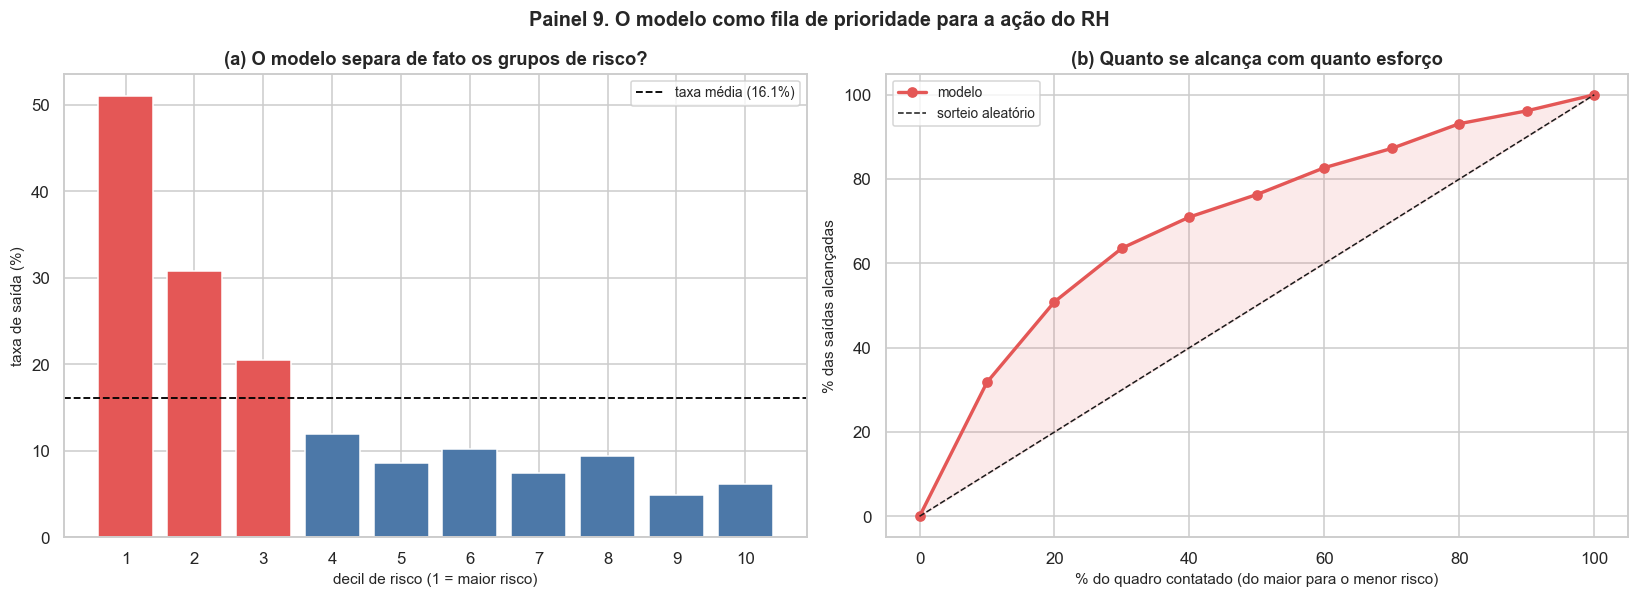

In [42]:
# Gráfico da lista de prioridade: as duas leituras que o RH precisa ver.
fig, eixos = plt.subplots(1, 2, figsize=(15, 5.5))

# --- (a) Taxa de saída por decil de risco --------------------------------
cores = [COR_SAIU if d <= 3 else COR_FICOU for d in tabela_decis.index]
eixos[0].bar(tabela_decis.index, tabela_decis["taxa de saída"] * 100, color=cores)
eixos[0].axhline(taxa_media * 100, color="black", linestyle="--", lw=1.2,
                 label=f"taxa média ({taxa_media:.1%})")
eixos[0].set(xlabel="decil de risco (1 = maior risco)", ylabel="taxa de saída (%)",
             title="(a) O modelo separa de fato os grupos de risco?",
             xticks=tabela_decis.index)
eixos[0].legend(fontsize=9)

# --- (b) Curva de captura acumulada --------------------------------------
eixo_x = [0] + [d * 10 for d in tabela_decis.index]
eixo_y = [0] + list(tabela_decis["% das saídas (acum.)"])
eixos[1].plot(eixo_x, eixo_y, "o-", color=COR_SAIU, lw=2.2, label="modelo")
eixos[1].plot([0, 100], [0, 100], "k--", lw=1, label="sorteio aleatório")
eixos[1].fill_between(eixo_x, eixo_y, eixo_x, alpha=0.12, color=COR_SAIU)
eixos[1].set(xlabel="% do quadro contatado (do maior para o menor risco)",
             ylabel="% das saídas alcançadas",
             title="(b) Quanto se alcança com quanto esforço")
eixos[1].legend(fontsize=9)

fig.suptitle("Painel 9. O modelo como fila de prioridade para a ação do RH",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

---

# Parte 10. Árvore de decisão

## 10.1 Por que uma segunda técnica, se a logística já funciona

A árvore de decisão é o `rpart()` do estudo original. Ela existe aqui por uma razão específica, e
não por redundância:

| | Regressão logística | Árvore de decisão |
|---|---|---|
| **Entrega** | Um coeficiente por variável | Um conjunto de regras do tipo "se… então…" |
| **Forma do efeito** | Supõe efeito linear no logito | Captura **patamares** e **interações** sem precisar declará-las |
| **Leitura** | Exige entender razão de chances | Um gestor lê o fluxograma sem treinamento |
| **Inferência** | Dá valor-p e intervalo de confiança | Não dá |
| **Estabilidade** | Estável | Instável: muda bastante com pequenas mudanças nos dados |

A árvore serve para **comunicar** e para **descobrir interação**. A logística serve para **estimar
e testar**. Usar as duas e comparar é melhor prática do que escolher uma — e é por isso que o
estudo original acrescenta `rpart` ao final.

**A diferença técnica entre R e Python aqui:** o `rpart()` do R aceita fatores diretamente. O
`DecisionTreeClassifier` do scikit-learn **só aceita números**, então é preciso codificar as
categóricas em indicadoras (*one-hot*) antes. A célula abaixo faz isso de forma explícita, com
`pd.get_dummies()`.

In [43]:
# ---------------------------------------------------------------------------
# 1) Seleção de variáveis. Usamos o mesmo conteúdo do Modelo 2, porque o
#    objetivo é COMPARAR as duas técnicas - e comparar modelos com conjuntos
#    de variáveis diferentes não diria nada sobre as técnicas.
# ---------------------------------------------------------------------------
variaveis_numericas = ["Age", "DistanceFromHome", "MonthlyIncome", "PriorYearsOfExperience",
                       "AverageTenure", "PrimeiroEmprego", "YearsAtCompany",
                       "YearsSinceLastPromotion", "YearsWithCurrManager",
                       "TrainingTimesLastYear", "PercentSalaryHike",
                       "JobSatisfaction", "EnvironmentSatisfaction",
                       "RelationshipSatisfaction", "JobInvolvement",
                       "WorkLifeBalance", "JobLevel", "StockOptionLevel", "Education"]

variaveis_categoricas = ["Department", "EmployeeSource", "JobRole", "MaritalStatus",
                         "Gender", "EducationField", "OverTime", "BusinessTravel"]

# ---------------------------------------------------------------------------
# 2) Codificação one-hot: cada categoria vira uma coluna 0/1.
#    drop_first=True descarta a primeira categoria de cada variável, como a
#    regressão faz - evita colunas redundantes. Para árvore isso é opcional,
#    mas mantém a comparação com a logística mais justa.
# ---------------------------------------------------------------------------
X = pd.get_dummies(
    base_unica[variaveis_numericas + variaveis_categoricas],
    columns=variaveis_categoricas,
    drop_first=True,
).astype(float)

y = base_unica["saiu"]

print(f"Matriz de atributos: {X.shape[0]:,} linhas x {X.shape[1]} colunas".replace(",", "."))
print(f"  {len(variaveis_numericas)} variáveis numéricas")
print(f"  {len(variaveis_categoricas)} categóricas -> "
      f"{X.shape[1] - len(variaveis_numericas)} colunas indicadoras")

# ---------------------------------------------------------------------------
# 3) A MESMA divisão treino/teste da Parte 9 (mesma semente, mesma
#    estratificação), para que a comparação de AUC seja legítima.
# ---------------------------------------------------------------------------
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.3, random_state=SEMENTE, stratify=y)

print(f"\ntreino: {len(X_treino):,} | teste: {len(X_teste):,}".replace(",", "."))

Matriz de atributos: 8.142 linhas x 48 colunas
  19 variáveis numéricas
  8 categóricas -> 29 colunas indicadoras

treino: 5.699 | teste: 2.443


## 10.2 Os hiperparâmetros, e o que cada um controla

A árvore cresce dividindo os dados em dois a cada nó, escolhendo sempre a pergunta que melhor
separa quem sai de quem fica. Sem limite, ela cresce até isolar cada caso — e aí **memoriza** o
treino em vez de aprender o padrão (*overfitting*). Os limites são:

| Parâmetro (sklearn) | Equivalente no `rpart` | O que faz |
|---|---|---|
| `min_samples_split` | `minsplit` | Mínimo de casos num nó para que valha dividi-lo |
| `min_samples_leaf` | `minbucket` | Mínimo de casos numa folha |
| `max_depth` | — | Profundidade máxima: controla a legibilidade |
| `ccp_alpha` | `cp` | Penalidade por complexidade: poda a árvore |
| `class_weight` | — | Peso das classes: `"balanced"` compensa o desbalanceamento |

O estudo original usa `minsplit = 500` e `cp = 0`. A primeira escolha é sensata nesta base; a
segunda (`cp = 0`, sem poda) é arriscada — permite crescer sem penalidade. Aqui serão ajustadas
**duas** árvores, para que a diferença seja visível:

- **Árvore A, rasa** (`max_depth=4`): feita para ser *lida* por um gestor;
- **Árvore B, profunda** (parâmetros do estudo original): feita para mostrar o custo da falta de poda.

In [44]:
def ajustar_arvore(rotulo, **parametros):
    """Ajusta uma árvore, avalia nos dois conjuntos e devolve as métricas."""
    arvore = DecisionTreeClassifier(random_state=SEMENTE, **parametros)
    arvore.fit(X_treino, y_treino)

    # predict_proba devolve DUAS colunas: [prob de 0, prob de 1].
    # Queremos a probabilidade da classe 1 (saiu), logo a coluna de índice 1.
    prob_treino = arvore.predict_proba(X_treino)[:, 1]
    prob_teste  = arvore.predict_proba(X_teste)[:, 1]

    metricas = {
        "modelo": rotulo,
        "folhas": arvore.get_n_leaves(),
        "profundidade": arvore.get_depth(),
        "AUC treino": roc_auc_score(y_treino, prob_treino),
        "AUC teste": roc_auc_score(y_teste, prob_teste),
    }
    metricas["otimismo"] = metricas["AUC treino"] - metricas["AUC teste"]
    return arvore, prob_teste, metricas


# Árvore A: rasa, para leitura humana. class_weight='balanced' faz a árvore
# dar mais peso à classe minoritária - sem isso ela tende a ignorar quem sai.
arvore_a, prob_arvore_a, metricas_a = ajustar_arvore(
    "Árvore A (rasa, para leitura)",
    max_depth=4, min_samples_leaf=200, class_weight="balanced")

# Árvore B: parâmetros do estudo original (minsplit=500, cp=0, sem poda)
arvore_b, prob_arvore_b, metricas_b = ajustar_arvore(
    "Árvore B (parâmetros do estudo em R: minsplit=500, sem poda)",
    min_samples_split=500, ccp_alpha=0.0)

# Árvore C: sem nenhum limite, para ver o overfitting em estado puro
arvore_c, prob_arvore_c, metricas_c = ajustar_arvore(
    "Árvore C (sem limite nenhum - demonstração de overfitting)")

print(pd.DataFrame([metricas_a, metricas_b, metricas_c])
      .set_index("modelo").round(4).to_string())

print("\nLEITURA: a coluna 'otimismo' é a diferença entre treino e teste.")
print("A Árvore C tem AUC de treino = 1,000: ela acerta TODOS os casos de treino,")
print("o que é a definição de memorização. Mas repare na AUC de TESTE dela, que")
print("ficou acima de todos os outros modelos - inclusive da logística.")
print("\nIsso não deveria acontecer. Uma árvore que memoriza o treino deveria ir MAL")
print("no teste. O fato de ir bem é um sinal de alarme, não de sucesso - e a célula")
print("seguinte investiga a causa.")

                                                              folhas  profundidade  AUC treino  AUC teste  otimismo
modelo                                                                                                             
Árvore A (rasa, para leitura)                                     13             4       0.728      0.718     0.010
Árvore B (parâmetros do estudo em R: minsplit=500, sem poda)      26            12       0.765      0.744     0.020
Árvore C (sem limite nenhum - demonstração de overfitting)       492            19       1.000      0.895     0.105

LEITURA: a coluna 'otimismo' é a diferença entre treino e teste.
A Árvore C tem AUC de treino = 1,000: ela acerta TODOS os casos de treino,
o que é a definição de memorização. Mas repare na AUC de TESTE dela, que
ficou acima de todos os outros modelos - inclusive da logística.

Isso não deveria acontecer. Uma árvore que memoriza o treino deveria ir MAL
no teste. O fato de ir bem é um sinal de alarme, não de sucesso 

## 10.3 O alarme: por que a árvore sem poda "venceu"

A Árvore C tem AUC de treino **1,000** (acerto perfeito, isto é, memorização completa) e AUC de
teste em torno de **0,895** — acima da logística (0,745) e das duas árvores podadas. Em modelagem
de atrito, **AUC acima de 0,85 é motivo de desconfiança, não de comemoração**: comportamento humano
não é tão previsível. Quando um modelo supera esse patamar, a primeira hipótese a testar é
vazamento.

A hipótese concreta: a Parte 4.4 removeu linhas duplicadas considerando **todas as 30 colunas**.
Mas a matriz de atributos usada aqui tem um **subconjunto** dessas colunas (`TotalWorkingYears`,
`NumCompaniesWorked`, `AgeStartedWorking`, `YearsInCurrentRole` e `PerformanceRating` ficaram fora).
Duas linhas que diferiam apenas nessas colunas excluídas são, **no espaço de atributos do modelo**,
idênticas. Se uma cai no treino e a outra no teste, a árvore que memorizou a primeira "prevê" a
segunda com certeza — sem ter aprendido nada.

A célula abaixo mede isso diretamente.

In [45]:
# Quantas linhas de TESTE têm um vetor de atributos IDÊNTICO a alguma linha de TREINO?
# Transformamos cada linha numa tupla (que é "hasheável") e usamos um conjunto,
# que faz a busca em tempo constante - comparar linha a linha seria lento.
vetores_treino = set(map(tuple, X_treino.values))
tem_gemeo = np.array([tuple(linha) in vetores_treino for linha in X_teste.values])

print("DUPLICATAS NO ESPAÇO DE ATRIBUTOS DO MODELO\n")
print(f"linhas repetidas dentro de X (todas as {X.shape[1]} colunas do modelo): "
      f"{X.duplicated().sum():,}".replace(",", "."))
print(f"linhas de TESTE com vetor idêntico no TREINO ..... {tem_gemeo.sum():,} "
      f"de {len(X_teste):,}  ({tem_gemeo.mean():.1%})".replace(",", "."))

# O teste decisivo: a árvore sem poda vai bem nas linhas COM gêmeo no treino,
# e mal nas linhas SEM gêmeo? Se sim, o desempenho era vazamento.
print("\nAUC da Árvore C, separando os dois grupos do conjunto de teste:\n")
for rotulo, mascara in [("linhas COM gêmeo idêntico no treino", tem_gemeo),
                        ("linhas SEM gêmeo (previsão genuína)", ~tem_gemeo)]:
    y_grupo    = y_teste.values[mascara]
    prob_grupo = prob_arvore_c[mascara]
    if len(np.unique(y_grupo)) > 1:          # AUC exige as duas classes presentes
        auc_grupo = roc_auc_score(y_grupo, prob_grupo)
        print(f"  {rotulo:<40} n = {len(y_grupo):>5}   AUC = {auc_grupo:.4f}")

print(f"\nPara comparação, a Logística 2 no conjunto de teste inteiro: "
      f"AUC = {resultado_2['auc_teste']:.4f}")

DUPLICATAS NO ESPAÇO DE ATRIBUTOS DO MODELO

linhas repetidas dentro de X (todas as 48 colunas do modelo): 1.480
linhas de TESTE com vetor idêntico no TREINO ..... 657 de 2.443  (26.9%)

AUC da Árvore C, separando os dois grupos do conjunto de teste:

  linhas COM gêmeo idêntico no treino      n =   657   AUC = 1.0000
  linhas SEM gêmeo (previsão genuína)      n =  1786   AUC = 0.8614

Para comparação, a Logística 2 no conjunto de teste inteiro: AUC = 0.7451


**O que a medição mostrou — e por que ela não fecha a questão.**

Nas 657 linhas de teste com gêmeo idêntico no treino, a AUC da Árvore C é **1,0000**: acerto
perfeito. Isso é memorização pura, e confirma o vazamento. Mas nas 1.786 linhas **sem** gêmeo a AUC
ainda fica em torno de **0,861** — bem acima da logística. Ou seja: as duplicatas exatas explicam
**parte** da vantagem, não toda.

A hipótese seguinte é que sobraram *quase*-gêmeos: linhas que diferem em uma ou duas variáveis, mas
que descrevem o mesmo perfil e têm o mesmo desfecho. O teste direto é remover as duplicatas **no
espaço de atributos** (incluindo o desfecho) e reajustar tudo.

In [46]:
# Deduplicação no espaço de atributos DO MODELO, desfecho incluído, e reajuste das três árvores.
XY = X.copy()
XY["_desfecho"] = y.values
XY_unico = XY.drop_duplicates()

X_dedup = XY_unico.drop(columns="_desfecho")
y_dedup = XY_unico["_desfecho"]

print(f"X original ............... {len(X):,} linhas".replace(",", "."))
print(f"X sem duplicata de perfil  {len(X_dedup):,} linhas".replace(",", "."))

configuracoes = [
    ("Árvore A (rasa)",      dict(max_depth=4, min_samples_leaf=200, class_weight="balanced")),
    ("Árvore B (minsplit=500)", dict(min_samples_split=500)),
    ("Árvore C (sem poda)",  dict()),
]

linhas = []
for rotulo, parametros in configuracoes:
    for nome_base, (Xa, ya) in [("com duplicatas", (X, y)), ("sem duplicatas", (X_dedup, y_dedup))]:
        Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(
            Xa, ya, test_size=0.3, random_state=SEMENTE, stratify=ya)
        arvore = DecisionTreeClassifier(random_state=SEMENTE, **parametros).fit(Xa_tr, ya_tr)
        linhas.append({
            "árvore": rotulo,
            "base": nome_base,
            "folhas": arvore.get_n_leaves(),
            "AUC treino": roc_auc_score(ya_tr, arvore.predict_proba(Xa_tr)[:, 1]),
            "AUC teste":  roc_auc_score(ya_te, arvore.predict_proba(Xa_te)[:, 1]),
        })

tabela_dedup = pd.DataFrame(linhas).set_index(["árvore", "base"])
print("\nEFEITO DA DEDUPLICAÇÃO NO ESPAÇO DE ATRIBUTOS\n")
print(tabela_dedup.round(3).to_string())
print(f"\nLogística 2, para referência: AUC teste = {resultado_2['auc_teste']:.3f}")

X original ............... 8.142 linhas
X sem duplicata de perfil  6.662 linhas



EFEITO DA DEDUPLICAÇÃO NO ESPAÇO DE ATRIBUTOS

                                        folhas  AUC treino  AUC teste
árvore                  base                                         
Árvore A (rasa)         com duplicatas      13       0.728      0.718
                        sem duplicatas      12       0.724      0.692
Árvore B (minsplit=500) com duplicatas      26       0.765      0.744
                        sem duplicatas      19       0.744      0.723
Árvore C (sem poda)     com duplicatas     492       1.000      0.895
                        sem duplicatas     445       1.000      0.836

Logística 2, para referência: AUC teste = 0.745


**O veredito, com o que ficou provado e o que ficou em aberto.**

Removendo as duplicatas de perfil, a AUC de teste da Árvore C cai de ≈ 0,895 para ≈ 0,836 — e as
árvores podadas também perdem (a B vai de ≈ 0,744 para ≈ 0,723; a A, de ≈ 0,718 para ≈ 0,692). Três
conclusões, em ordem de solidez:

1. **Parte da vantagem era vazamento, e isso está demonstrado.** A AUC de 1,0000 nas linhas com
   gêmeo exato não admite outra leitura, e todas as árvores perdem desempenho quando as duplicatas
   de perfil saem.
2. **A vantagem não é só vazamento.** Mesmo na base deduplicada, a árvore sem poda fica bem acima da
   logística. Isso é compatível com duas explicações que esta base **não** permite separar: (i) há
   interações e patamares reais que a logística, do jeito como foi especificada, não captura; (ii)
   sobrou estrutura artificial da replicação sintética — perfis quase idênticos, com o mesmo
   desfecho, espalhados entre treino e teste. Como a base não traz identificador de funcionário,
   não há como dividir treino e teste *por pessoa*, que é o único corte que eliminaria a segunda
   explicação.
3. **Por isso o número da Árvore C não entra em nenhuma decisão.** O princípio é geral e vale para
   qualquer projeto: **quando um modelo salta de desempenho sem que se saiba dizer por qual
   mecanismo, o ônus é do analista** — ou se explica o salto, ou não se usa o número. Nesta base,
   com a replicação sintética documentada na Parte 4.4, o salto não tem explicação limpa.

O que se leva adiante são os modelos cujo desempenho é explicável: a Logística 2 (0,745) e a
Árvore B (0,744), praticamente empatadas — o que também é informativo. Duas técnicas muito
diferentes chegando ao mesmo patamar sugere que esse patamar é, aproximadamente, o quanto esta
base permite prever.

## 10.4 A árvore que o RH pode ler

Descartada a Árvore C, volta-se à **Árvore A** — rasa de propósito, para que o resultado caiba numa
reunião. Profundidade 4 e no mínimo 200 casos por folha garantem que cada regra se sustente em um
grupo grande o bastante para não ser ruído.

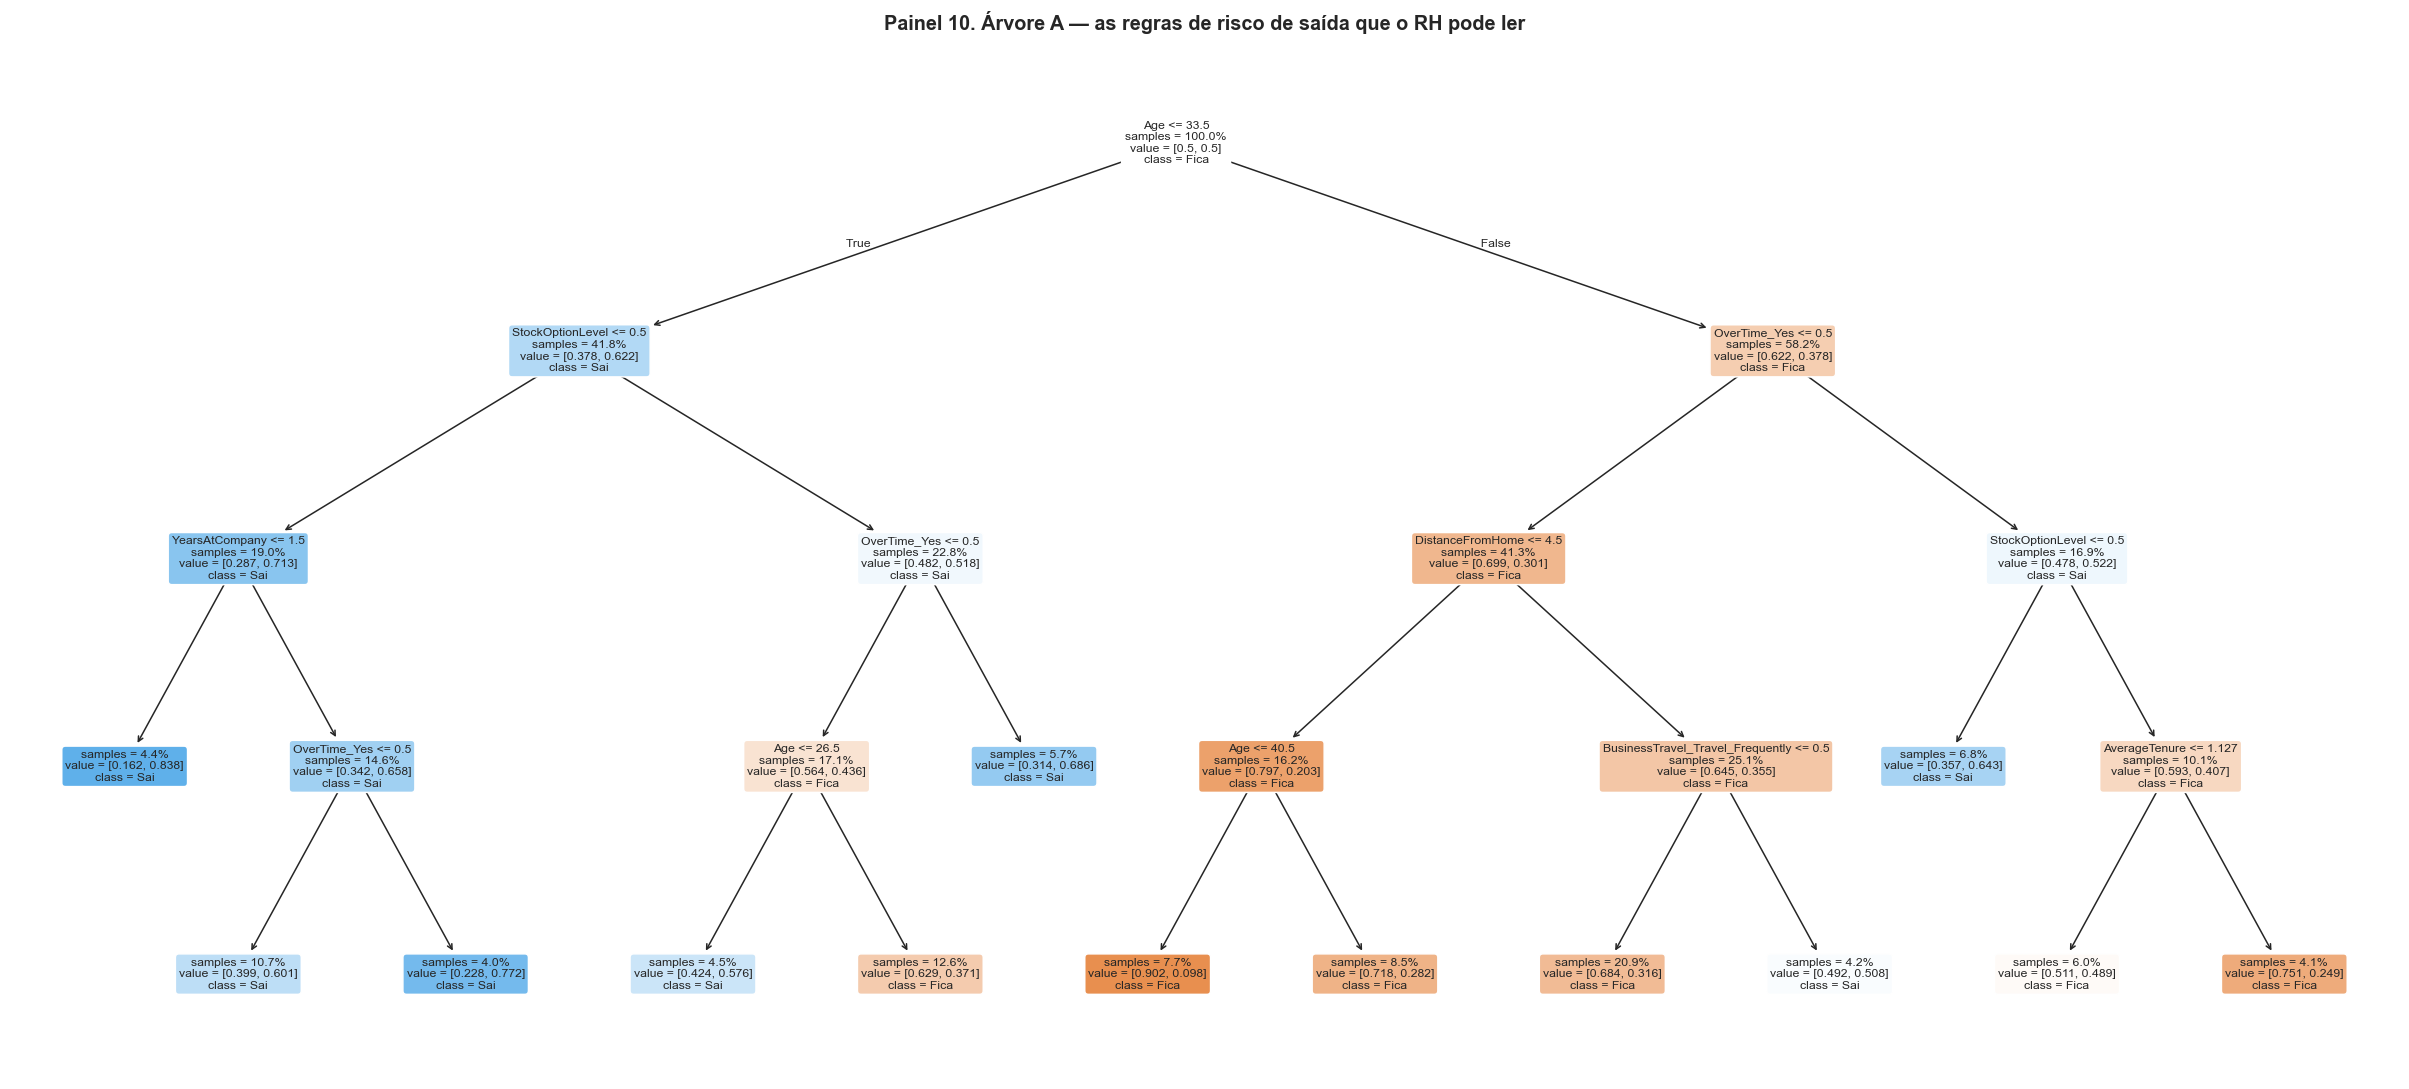

In [47]:
# Visualização da Árvore A. plot_tree desenha a árvore ajustada.
fig, eixo = plt.subplots(figsize=(22, 10))

plot_tree(
    arvore_a,
    feature_names=X.columns,          # nomes das variáveis nos nós
    class_names=["Fica", "Sai"],      # rótulos das classes
    filled=True,                      # cor proporcional à classe dominante
    rounded=True,
    proportion=True,                  # mostra proporções, não contagens brutas
    fontsize=8,
    impurity=False,                   # esconde o Gini: polui a leitura didática
    ax=eixo,
)
eixo.set_title("Painel 10. Árvore A — as regras de risco de saída que o RH pode ler",
               fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Como ler a árvore.** Cada caixa é um nó e traz:

- a **pergunta** que divide os dados (ex.: `OverTime_Yes <= 0.5`, isto é, "não faz hora extra?");
- `samples`: a proporção do conjunto de treino que chegou àquele nó;
- `value`: a composição entre as duas classes naquele nó (com `class_weight="balanced"`, esses
  valores estão ponderados);
- `class`: a classe majoritária naquele nó.

**Percorra do topo para baixo e leia o caminho como uma frase.** Cada caminho da raiz até uma folha
é uma regra de negócio. A primeira divisão é a variável mais informativa de todas — e ela deve ser
coerente com o que a Parte 8 e o Painel 7 mostraram. Quando a árvore e a logística apontam a mesma
variável no topo, isso é evidência convergente: duas técnicas com pressupostos diferentes
chegaram ao mesmo lugar.

In [48]:
# As regras em texto. Para muitos gestores, este formato é mais útil que o desenho:
# dá para colar no slide, no e-mail, no procedimento.
print("REGRAS DA ÁRVORE A, EM TEXTO\n")
print(export_text(arvore_a, feature_names=list(X.columns),
                  max_depth=3, decimals=2, show_weights=False))

REGRAS DA ÁRVORE A, EM TEXTO

|--- Age <= 33.50
|   |--- StockOptionLevel <= 0.50
|   |   |--- YearsAtCompany <= 1.50
|   |   |   |--- class: 1
|   |   |--- YearsAtCompany >  1.50
|   |   |   |--- OverTime_Yes <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- OverTime_Yes >  0.50
|   |   |   |   |--- class: 1
|   |--- StockOptionLevel >  0.50
|   |   |--- OverTime_Yes <= 0.50
|   |   |   |--- Age <= 26.50
|   |   |   |   |--- class: 1
|   |   |   |--- Age >  26.50
|   |   |   |   |--- class: 0
|   |   |--- OverTime_Yes >  0.50
|   |   |   |--- class: 1
|--- Age >  33.50
|   |--- OverTime_Yes <= 0.50
|   |   |--- DistanceFromHome <= 4.50
|   |   |   |--- Age <= 40.50
|   |   |   |   |--- class: 0
|   |   |   |--- Age >  40.50
|   |   |   |   |--- class: 0
|   |   |--- DistanceFromHome >  4.50
|   |   |   |--- BusinessTravel_Travel_Frequently <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- BusinessTravel_Travel_Frequently >  0.50
|   |   |   |   |--- class: 1
|   |--- OverTim

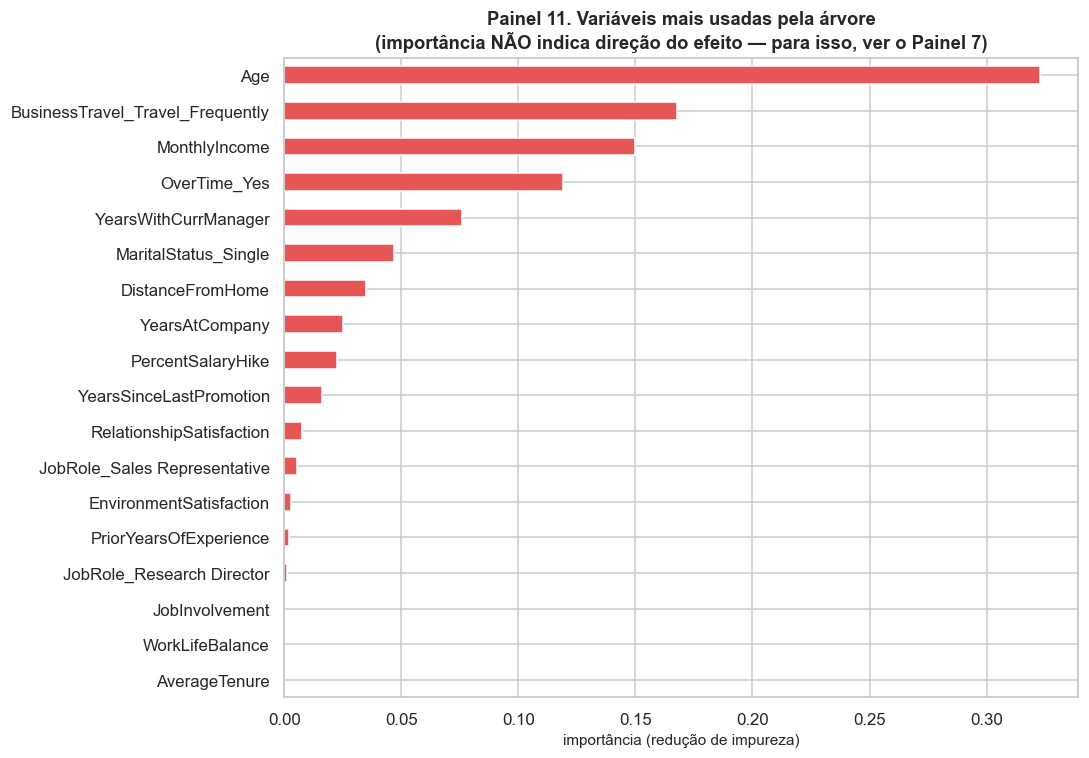

Importância das 10 primeiras:

Age                                32.300
BusinessTravel_Travel_Frequently   16.800
MonthlyIncome                      15.000
OverTime_Yes                       11.900
YearsWithCurrManager                7.600
MaritalStatus_Single                4.700
DistanceFromHome                    3.500
YearsAtCompany                      2.500
PercentSalaryHike                   2.300
YearsSinceLastPromotion             1.600


In [49]:
# Importância das variáveis na Árvore B (a mais profunda, que usa mais variáveis).
# ATENÇÃO: 'importância' numa árvore = quanto aquela variável reduziu a impureza
# total. NÃO é efeito causal, NÃO tem sinal (não diz se aumenta ou reduz o risco)
# e favorece variáveis com muitos valores distintos. É um guia, não uma conclusão.
importancias = (pd.Series(arvore_b.feature_importances_, index=X.columns)
                .sort_values(ascending=False).head(18))

fig, eixo = plt.subplots(figsize=(10, 7))
importancias.sort_values().plot(kind="barh", color=COR_SAIU, ax=eixo)
eixo.set(xlabel="importância (redução de impureza)", ylabel="",
         title="Painel 11. Variáveis mais usadas pela árvore\n"
               "(importância NÃO indica direção do efeito — para isso, ver o Painel 7)")
plt.tight_layout()
plt.show()

print("Importância das 10 primeiras:\n")
print((importancias.head(10) * 100).round(1).rename("% da importância total").to_string())

## 10.5 Comparação final dos modelos

Todos os modelos foram ajustados na **mesma base**, com a **mesma semente** e avaliados no **mesmo
conjunto de teste** — sem isso, a comparação não valeria nada. A Árvore C entra na tabela como
**contraexemplo**, com o alerta da Parte 10.3: a AUC dela não mede capacidade de previsão.

COMPARAÇÃO FINAL — mesmo conjunto de teste, mesma semente

                                                              AUC teste                  interpretável?
modelo                                                                                                 
Árvore C (sem limite nenhum - demonstração de overfitting)        0.895  não — e AUC inflada (ver 10.3)
Logística 2 — Grupos A + B (gestão)                               0.745              sim (RC + valor-p)
Árvore B (parâmetros do estudo em R: minsplit=500, sem poda)      0.744                         parcial
Árvore A (rasa, para leitura)                                     0.718           sim (regras legíveis)
Logística 1 — só Grupo A (recrutamento)                           0.696              sim (RC + valor-p)

O MODELO ESCOLHIDO é a Logística 2: melhor AUC entre os modelos sem vazamento,
com coeficientes interpretáveis, valores-p e intervalos de confiança. A Árvore A
acompanha como instrumento de COMUNICAÇÃO - as regra

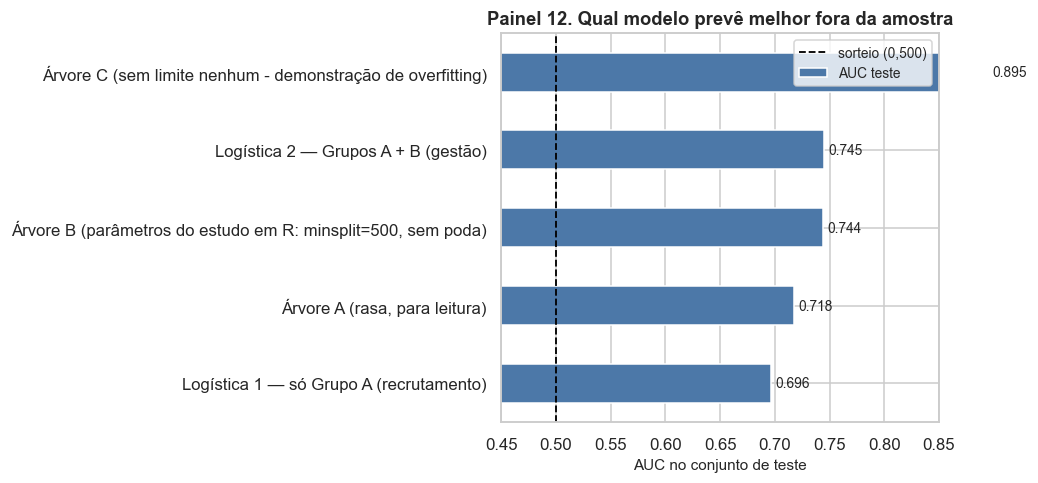

In [50]:
# Comparação final das quatro abordagens, na MESMA base e no MESMO conjunto de teste.
comparacao_final = pd.DataFrame([
    {"modelo": "Logística 1 — só Grupo A (recrutamento)",
     "AUC teste": resultado_1u["auc_teste"], "interpretável?": "sim (RC + valor-p)"},
    {"modelo": "Logística 2 — Grupos A + B (gestão)",
     "AUC teste": resultado_2["auc_teste"], "interpretável?": "sim (RC + valor-p)"},
    {"modelo": metricas_a["modelo"],
     "AUC teste": metricas_a["AUC teste"], "interpretável?": "sim (regras legíveis)"},
    {"modelo": metricas_b["modelo"],
     "AUC teste": metricas_b["AUC teste"], "interpretável?": "parcial"},
    {"modelo": metricas_c["modelo"],
     "AUC teste": metricas_c["AUC teste"],
     "interpretável?": "não — e AUC inflada (ver 10.3)"},
]).set_index("modelo").sort_values("AUC teste", ascending=False)

print("COMPARAÇÃO FINAL — mesmo conjunto de teste, mesma semente\n")
print(comparacao_final.round(4).to_string())
print("\nO MODELO ESCOLHIDO é a Logística 2: melhor AUC entre os modelos sem vazamento,")
print("com coeficientes interpretáveis, valores-p e intervalos de confiança. A Árvore A")
print("acompanha como instrumento de COMUNICAÇÃO - as regras dela vão para o slide,")
print("as razões de chances da logística vão para o relatório.")

fig, eixo = plt.subplots(figsize=(10, 4.5))
comparacao_final["AUC teste"].sort_values().plot(kind="barh", ax=eixo, color=COR_FICOU)
eixo.axvline(0.5, color="black", linestyle="--", lw=1.2, label="sorteio (0,500)")
eixo.set(xlabel="AUC no conjunto de teste", ylabel="",
         title="Painel 12. Qual modelo prevê melhor fora da amostra", xlim=(0.45, 0.85))
eixo.legend(fontsize=9)
for i, valor in enumerate(comparacao_final["AUC teste"].sort_values()):
    eixo.text(valor + 0.004, i, f"{valor:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

---

# Parte 11. Do modelo à decisão de RH

Um projeto de People Analytics que termina na AUC não terminou. Esta parte faz a travessia que
justifica todo o resto: **transformar resultado estatístico em decisão de gestão, com custo
estimado e com limites declarados.**

## 11.1 Os achados, organizados pelo que a empresa pode fazer com eles

A regra de organização não é a força estatística: é a **acionabilidade**. Um fator com associação
forte e nenhuma alavanca de gestão vale menos, na prática, que um fator moderado sobre o qual a
empresa decide diretamente.

| Fator | Associação | A empresa controla? | Ação possível | Prazo |
|---|---|---|---|---|
| **Viagens frequentes** | Muito forte (≈ 3,9× a chance) | **Sim, diretamente** | Rever a política de viagens: rotação entre a equipe, substituição por reunião remota, compensação específica para quem viaja muito | Curto |
| **Hora extra** | Forte (≈ 2,6× a chance) | **Sim, diretamente** | Dimensionamento de equipe; teto de horas; revisão de carga nas áreas com mais incidência | Curto |
| **Nenhum treinamento no ano** | Moderada (≈ 0,85 por treinamento) | **Sim, baixo custo** | Garantir piso mínimo de treinamentos por pessoa/ano | Curto |
| **Equilíbrio trabalho-vida = 1** | Forte (degrau) | **Sim** | Lista nominal do grupo que avaliou 1; diagnóstico por área; ação sobre a causa local | Curto |
| **Participação acionária = 0** | Moderada a forte | **Sim** | Estender elegibilidade a cargos de risco alto e substituição custosa | Médio |
| **Salário relativo baixo** | Moderada | Sim, com custo | Revisão de faixas nos cargos com maior taxa de saída | Médio |
| **Satisfação com trabalho/ambiente baixa** | Moderada, gradiente | Parcialmente | Pesquisa de clima com desdobramento por gestor; ação sobre causas locais | Médio |
| **Anos sem promoção** | Moderada (na cauda) | **Sim** | Revisar os casos extremos: ou promove, ou explica o porquê | Curto |
| **Cargo (ex.: Sales Representative)** | Forte | Parcialmente | Trilha de carreira e remuneração variável específicas da função | Médio |
| **Canal de recrutamento** | Fraca a moderada | **Sim** | Realocar investimento entre canais — **após** controlar por cargo | Médio |
| **Estado civil (solteiro)** | Forte sem os controles de gestão; **desaparece** com eles | **Não** (e não deve) | **Nenhuma ação sobre a pessoa.** Usar como controle estatístico apenas | — |
| **Idade** | Moderada | **Não** (e não deve) | **Nenhuma ação sobre a pessoa.** Controle estatístico | — |
| **Gênero** | Não detectada | — | Monitorar; resultado nulo é informação relevante | — |

## 11.2 Quanto vale evitar uma saída: a conta que converte estatística em orçamento

Nenhuma proposta de retenção é aprovada sem número. A conta abaixo é propositalmente **simples e
com premissas explícitas** — o valor de um cálculo assim não está na precisão, está em tornar as
premissas discutíveis. Troque os valores pelos da sua organização.

In [51]:
# ======================= PREMISSAS (ajuste para o seu caso) ================
SALARIO_MEDIO_MENSAL   = float(base_unica["MonthlyIncome"].mean())
MESES_PARA_SUBSTITUIR  = 3.0    # tempo médio entre a saída e o substituto produtivo
CUSTO_RECRUTAMENTO     = 1.0    # em salários mensais: anúncio, seleção, horas de entrevista
CUSTO_TREINAMENTO      = 1.5    # em salários mensais: integração, treinamento, mentoria
PERDA_PRODUTIVIDADE    = 1.5    # em salários mensais: vaga aberta + rampa do substituto
EFICACIA_DA_CONVERSA   = 0.25   # fração das saídas evitada quando há intervenção a tempo
CUSTO_DA_CONVERSA      = 0.02   # custo de cada conversa, em salários mensais (~4 horas)
# ==========================================================================

custo_por_saida = (SALARIO_MEDIO_MENSAL
                   * (CUSTO_RECRUTAMENTO + CUSTO_TREINAMENTO + PERDA_PRODUTIVIDADE))

print("PREMISSAS")
print(f"  salário médio mensal na base ......... R$ {SALARIO_MEDIO_MENSAL:,.0f}"
      .replace(",", "."))
print(f"  custo de uma saída (em salários) ..... "
      f"{CUSTO_RECRUTAMENTO + CUSTO_TREINAMENTO + PERDA_PRODUTIVIDADE:.1f}x")
print(f"  CUSTO ESTIMADO POR SAÍDA ............. R$ {custo_por_saida:,.0f}"
      .replace(",", "."))

# --- Cenário: atuar sobre o decil de maior risco do conjunto de teste -----
n_abordados   = int(decil_1["n"])
saidas_no_grupo = int(decil_1["saídas observadas"])
saidas_evitadas = saidas_no_grupo * EFICACIA_DA_CONVERSA

beneficio = saidas_evitadas * custo_por_saida
custo     = n_abordados * CUSTO_DA_CONVERSA * SALARIO_MEDIO_MENSAL
retorno   = beneficio - custo

print(f"\nCENÁRIO: conversa estruturada com os 10% de maior risco previsto")
print(f"  pessoas abordadas .................... {n_abordados}")
print(f"  saídas que de fato ocorreram no grupo  {saidas_no_grupo}")
print(f"  saídas evitadas (eficácia {EFICACIA_DA_CONVERSA:.0%}) ...... {saidas_evitadas:.1f}")
print(f"\n  benefício estimado .................. R$ {beneficio:,.0f}".replace(",", "."))
print(f"  custo das conversas ................. R$ {custo:,.0f}".replace(",", "."))
print(f"  RETORNO LÍQUIDO ESTIMADO ............ R$ {retorno:,.0f}".replace(",", "."))
if custo > 0:
    print(f"  retorno por real investido .......... R$ {beneficio / custo:,.2f}")

# --- Sensibilidade: o resultado depende de quê? ---------------------------
print("\n\nANÁLISE DE SENSIBILIDADE À EFICÁCIA DA INTERVENÇÃO")
print("(a premissa mais incerta de todas - e é honesto mostrar o intervalo)\n")
cenarios = []
for eficacia in [0.05, 0.10, 0.15, 0.25, 0.40]:
    b = saidas_no_grupo * eficacia * custo_por_saida
    cenarios.append({"eficácia": f"{eficacia:.0%}",
                     "saídas evitadas": round(saidas_no_grupo * eficacia, 1),
                     "benefício (R$)": round(b),
                     "retorno líquido (R$)": round(b - custo)})
print(pd.DataFrame(cenarios).to_string(index=False))

print("\nO ponto desta tabela: mesmo com eficácia baixa, a conta fecha positiva, porque")
print("o custo de uma conversa é muito menor que o custo de uma substituição. É esse")
print("desequilíbrio de custos - e não a AUC do modelo - que justifica o programa.")

PREMISSAS
  salário médio mensal na base ......... R$ 6.305
  custo de uma saída (em salários) ..... 4.0x
  CUSTO ESTIMADO POR SAÍDA ............. R$ 25.220

CENÁRIO: conversa estruturada com os 10% de maior risco previsto
  pessoas abordadas .................... 245
  saídas que de fato ocorreram no grupo  125
  saídas evitadas (eficácia 25%) ...... 31.2

  benefício estimado .................. R$ 788.119
  custo das conversas ................. R$ 30.894
  RETORNO LÍQUIDO ESTIMADO ............ R$ 757.225
  retorno por real investido .......... R$ 25.51


ANÁLISE DE SENSIBILIDADE À EFICÁCIA DA INTERVENÇÃO
(a premissa mais incerta de todas - e é honesto mostrar o intervalo)

eficácia  saídas evitadas  benefício (R$)  retorno líquido (R$)
      5%            6.200          157624                126730
     10%           12.500          315248                284353
     15%           18.800          472871                441977
     25%           31.200          788119                7572

## 11.3 O que este estudo **não** autoriza a concluir

Retomando a Parte 0.5, agora com os resultados em mãos. Todo relatório de People Analytics deve
ter uma seção como esta, e ela deve ser escrita **antes** da apresentação, não depois da pergunta
difícil na reunião.

**1. Nenhum resultado aqui é causal.** O modelo mede associação condicional. Para afirmar que
reduzir hora extra *causa* redução de saídas, seria preciso um desenho que isolasse o efeito: um
piloto com áreas comparáveis, em que uma recebe a política de teto de horas e outra não, com
acompanhamento por alguns trimestres. Esse desenho é factível e custa pouco — e é a recomendação
metodológica mais importante deste relatório.

**2. O modelo não está validado no tempo.** A divisão treino/teste foi **aleatória**, não
**temporal**. A validação correta para uso em produção é: treinar com os dados até um ano T e testar
nas saídas do ano T+1. Essa validação não é possível nesta base, que não tem data. Enquanto ela não
for feita, o número de AUC vale como demonstração de método, não como promessa de desempenho.

**3. A base tem limitações documentadas.** 64,5% de linhas duplicadas (Parte 4.4); origem
sintetizada a partir da base IBM clássica; `Attrition` sem data; ausência de informação sobre
gestor direto, área de atuação específica e remuneração variável. Tudo isso está registrado no
notebook e deve constar do relatório.

**4. Variáveis protegidas têm uso restrito e declarado.** Gênero, idade e estado civil entraram no
modelo **como controles**, para que o efeito das demais variáveis não fosse contaminado por
composição do quadro. Elas **não** devem entrar em nenhuma regra de decisão sobre pessoas — nem em
seleção, nem em promoção, nem na priorização de conversas. Sob a LGPD, isso não é só boa prática:
tratar dado pessoal de funcionário exige base legal, finalidade declarada e minimização.

**5. O modelo produz prioridade, não veredito.** A saída operacional é uma fila de conversas
(Parte 9.9). Usar a probabilidade prevista para decidir promoção, desligamento ou alocação é uso
indevido: o modelo não foi construído para isso e os erros teriam consequências sobre pessoas
específicas. Há ainda um efeito perverso a evitar: se os gestores souberem a nota de risco de cada
pessoa, a nota passa a influenciar o tratamento, que influencia a saída — a previsão se torna
profecia autorrealizável.

**6. Transparência com quem é medido.** Os funcionários devem saber que existe um programa de
retenção baseado em dados, que finalidade ele tem e que dados usa. Um programa de People Analytics
que precisa ser secreto para funcionar tem um problema que nenhum modelo resolve.

---

# Parte 12. O que foi corrigido em relação ao script original em R

Esta parte existe porque **ler código alheio com olhar crítico é uma competência da disciplina**.
O script do estudo original é um bom material didático e cobre o fluxo completo de um projeto de
People Analytics. Também tem erros — e identificá-los vale mais, como aprendizado, do que executá-lo
sem questionar.

| # | No script em R | Problema | O que este notebook faz |
|---|---|---|---|
| 1 | `dados_rh_1_treino <- subset(dados_rh_1, train = T)` | **Erro grave.** `train` não é argumento de `subset()` nem coluna da base: é ignorado, e a função devolve a base inteira. Treino e teste ficam idênticos, e todo desempenho reportado é medido nos dados de ajuste | Divisão correta com `train_test_split(..., stratify=y)`, e a diferença treino/teste é medida e mostrada (Parte 9.5) |
| 2 | Duplicatas | Não verificadas. 64,5% da base são repetições exatas, e 26,9% das linhas de teste têm vetor idêntico no treino, o que vaza entre os dois conjuntos | Detectadas, quantificadas, e o efeito sobre a AUC é medido nos dois tipos de modelo — nulo na logística, e com acerto perfeito nas linhas copiadas no caso da árvore sem poda (Partes 4.4, 9.6 e 10.3) |
| 3 | `glm(Attrition ~ ..., family = binomial)` com `Attrition` de 3 níveis | A família binomial exige dependente binária. Com 3 níveis, o R agrupa silenciosamente, misturando demissão voluntária com desligamento — eventos de causas opostas | `saiu` binária e explícita, com o recorte dos desligamentos documentado (Parte 6) |
| 4 | `dados <- droplevels(dados_rh)` | O resultado é atribuído a `dados`, mas as linhas seguintes continuam usando `dados_rh`. A operação não tem efeito | `cat.remove_unused_categories()` aplicada na base efetivamente usada |
| 5 | `AverageTenure[!is.finite(...)] <- 0` | Quem está no primeiro emprego recebe o mesmo valor (0) de quem teve permanências brevíssimas: dois perfis opostos com o mesmo código | Mantém o 0 **e** cria a indicadora `PrimeiroEmprego`, que separa os dois casos (Parte 5.2) |
| 6 | `threshold <- 0.5` | Com 16% de eventos, 0,5 classifica quase todo mundo como "fica": recall perto de zero e acurácia enganosamente alta | Varredura de cortes, curva precisão-recall e uso por ordenamento em vez de classificação (Partes 9.8 e 9.9) |
| 7 | `AgeStartedWorking` nos gráficos | Não se registra que a variável é exatamente `Age − TotalWorkingYears` | Identidade verificada e a variável excluída dos modelos, com justificativa (Parte 4.7) |
| 8 | Acurácia via `table(obs, pred)` | Única métrica reportada, e a pior escolha para classe desbalanceada | AUC, recall, precisão, lift e captura acumulada (Partes 9.8 e 9.9) |
| 9 | `vif()` chamado sem leitura | O número é impresso e não se diz o que fazer com ele | VIF calculado, agrupado por variável, com limiares e conduta (Parte 9.4) |
| 10 | Grupo A e Grupo B misturados | Variáveis conhecidas antes e depois da contratação entram no mesmo modelo, sem distinção de uso | Dois modelos separados, com comparação explícita do que cada grupo acrescenta (Partes 1.3, 9.2 e 9.7) |
| 11 | `subset(dados, !is.na(x))` nos gráficos | Precaução que, nesta base, não remove nenhuma linha — porque não há ausentes | Ausência de valores ausentes verificada e declarada (Parte 4.3) |
| 12 | Insights em comentário | Afirmações numéricas ("58% têm menos de 3 anos") não são recalculadas | Todos os números são recalculados e confrontados com a afirmação original (Parte 5.4) |

**O que o script original acerta, e que foi mantido aqui:** a sequência de trabalho (carga →
limpeza → engenharia de atributos → exploração → modelagem), a distinção entre demissão voluntária
e desligamento, a criação de `PriorYearsOfExperience` e `AverageTenure`, o uso de duas técnicas
(logística e árvore) e o hábito de comentar cada bloco. A estrutura é boa; a execução precisa dos
reparos acima.

---

# Parte 13. Síntese, exercícios e referências

## 13.1 Síntese do estudo

**A pergunta.** Quais fatores mais se associam ao atrito (demissão voluntária) no quadro de
pessoal, e o que se pode fazer a respeito?

**O caminho.** 23.058 registros, 30 variáveis. Diagnóstico de qualidade (64,5% de duplicatas,
nenhum ausente, uma variável redundante por construção). Recorte para 22.971 casos de interesse,
com taxa global de saída voluntária de **15,7%**. Duas variáveis criadas (experiência anterior,
estabilidade média) e uma correção de codificação (primeiro emprego). Exploração univariada e
bivariada com taxa, n e intervalo de confiança. Dois modelos logísticos (recrutamento e gestão) e
três árvores, todos avaliados **fora da amostra**.

**Os achados principais.**

1. **Viagens frequentes** é o fator de maior magnitude no modelo final (chance ≈ 3,9 vezes maior
   que entre quem não viaja) — e só aparece com essa força **depois** do controle por cargo, nível
   e salário. A análise bivariada o subestimava.
2. **Hora extra** vem em seguida (chance ≈ 2,6 vezes maior) e é o fator mais acionável: o efeito
   persiste controlando por salário, cargo, nível e satisfação.
3. **Equilíbrio trabalho-vida ruim (nível 1)** forma um grupo de risco destacado — padrão de
   degrau, não de gradiente, o que concentra a ação num grupo pequeno e identificável.
4. **Salário relativo**, **participação acionária** e **treinamentos no último ano** protegem —
   os três são instrumentos que a empresa aciona diretamente, com custos muito diferentes.
5. **Satisfação com o trabalho, com o ambiente e envolvimento** têm gradiente claro e consistente.
6. **Idade protege; estado civil não resiste aos controles.** "Solteiro" tinha chance 2,1 vezes
   maior no modelo de recrutamento e perde a significância quando entram as variáveis de gestão:
   era indicador indireto daquilo que estas medem diretamente. Nenhum dos dois deve orientar
   decisão sobre pessoas.
7. **Gênero não apresenta diferença detectável.** Resultado nulo, reportado como tal.
8. **Nenhuma variável isolada explica o atrito.** A maior correlação simples com a saída é de
   |r| ≈ 0,2: o fenômeno é multifatorial, e é isso que justifica o modelo multivariado.
9. **A qualidade da base limita tudo.** Os 64,5% de linhas repetidas não enganaram a regressão
   (Parte 9.6), mas levaram uma árvore sem poda a acerto perfeito nas linhas que tinham cópia no
   treino (Parte 10.3). A lição não é "duplicata engana" nem "duplicata é inofensiva": é que **o
   efeito depende da flexibilidade do modelo**, e por isso se checa sempre. O desempenho confiável
   desta base está em torno de **AUC 0,74** — patamar ao qual a logística e a árvore podada chegam
   por caminhos independentes.

**O uso recomendado.** Fila mensal de prioridade com os 10% de maior risco previsto, que concentra
parcela desproporcional das saídas (Parte 9.9), somada a ação estrutural sobre hora extra e
equilíbrio trabalho-vida. Para afirmar causalidade, um piloto controlado — não mais análise da
mesma base.

## 13.2 Exercícios

**Nível 1 — leitura e replicação**

1. Recalcule a taxa de saída por `JobRole` **dentro de cada departamento**. Algum cargo tem
   comportamento oposto ao do seu departamento? Use `taxa_saida_por()` sobre um subconjunto.
2. No Painel 4, o `WorkLifeBalance` mostra padrão de degrau. Construa uma variável
   `EquilibrioRuim = (WorkLifeBalance == 1)` e compare, no Modelo 2, a especificação com a
   indicadora contra a especificação com `C(WorkLifeBalance)`. O que muda na AUC? E na legibilidade?
3. Refaça o Painel 5 usando a base **sem duplicatas**. Alguma mediana muda de forma relevante?

**Nível 2 — modelagem**

4. Acrescente ao Modelo 2 a **interação** entre hora extra e equilíbrio trabalho-vida
   (`C(OverTime):C(WorkLifeBalance)` na fórmula). A hipótese é que hora extra pesa mais para quem
   já tem equilíbrio ruim. A interação é significativa? Quanto a AUC muda?
5. Ajuste o Modelo 2 **separadamente por departamento**. Os fatores de risco são os mesmos em
   Vendas e em P&D? Se não forem, o que isso implica para uma política única de retenção?
6. Troque a árvore por uma **floresta aleatória** (`RandomForestClassifier`). Quanto a AUC melhora?
   O que se perde em interpretabilidade? Vale a troca, dado o uso pretendido na Parte 9.9?
7. O Modelo 1 usa só o Grupo A. Construa um Modelo 3 **só com o Grupo B** e compare as três AUCs.
   Qual grupo de variáveis carrega mais informação sobre o atrito?

**Nível 3 — desenho de pesquisa e decisão**

8. Refaça a conta da Parte 11.2 com premissas da sua organização (ou de uma que você conheça).
   Em que valor de eficácia da intervenção o retorno líquido se torna negativo?
9. Escreva, em uma página, o **desenho de um piloto** para testar causalmente o efeito da hora
   extra sobre a saída: unidade de alocação, critério de comparabilidade entre grupos, duração,
   variável de resultado, e o que poderia invalidar a conclusão.
10. Redija a **seção de limitações** do relatório que você entregaria à diretoria, em no máximo
    300 palavras, usando a Parte 11.3 como insumo mas com suas próprias palavras.
11. A diretoria pede a lista nominal dos 50 funcionários de maior risco, para "conversar". Escreva
    a resposta: o que você entrega, o que você não entrega, e por quê.

## 13.3 Referências

**A base**
- IBM HR Analytics Employee Attrition & Performance — base sintética de 1.470 registros, criada
  para fins de ensino, da qual esta é uma versão ampliada.

**People Analytics**
- *People analytics at Google: using data to make Google a great place to work.* Harvard Business
  School Digital Initiative. https://digital.hbs.edu/platform-digit/submission/people-analytics-at-google-using-data-to-make-google-a-great-place-to-work/
- *Case study: how Google uses People Analytics.* Sage People. https://www.sagepeople.com/about-us/news-hub/case-study-how-google-uses-people-analytics/
- BOCK, L. *Um novo jeito de trabalhar.* Sextante, 2015. (relato interno do People Operations do Google)
- EDMONDSON, A. C. *A organização sem medo.* Alta Books, 2020. (segurança psicológica; base do Project Aristotle)

**Método**
- HOSMER, D. W.; LEMESHOW, S.; STURDIVANT, R. X. *Applied Logistic Regression.* 3. ed. Wiley, 2013.
  (a referência padrão sobre regressão logística e interpretação de razões de chances)
- FIELD, A. *Descobrindo a estatística usando o SPSS.* 2. ed. Artmed, 2009. (cap. sobre logística)
- JAMES, G. et al. *An Introduction to Statistical Learning.* 2. ed. Springer, 2021.
  (treino/teste, árvores, avaliação; disponível gratuitamente)
- FAVERO, L. P.; BELFIORE, P. *Manual de análise de dados.* Elsevier, 2017.

**Documentação das ferramentas**
- pandas: https://pandas.pydata.org/docs/
- statsmodels (logística): https://www.statsmodels.org/stable/discretemod.html
- scikit-learn (árvores e métricas): https://scikit-learn.org/stable/
- seaborn: https://seaborn.pydata.org/

**Marco legal**
- BRASIL. Lei nº 13.709/2018 — Lei Geral de Proteção de Dados Pessoais (LGPD).

---

*Notebook preparado para a disciplina Métodos e Técnicas de Pesquisa Quantitativa, curso de
Administração da UFMA. O estudo retoma, em Python, um estudo de caso cuja versão de referência é
escrita em R, e a reexamina de ponta a ponta. Os erros identificados na Parte 12 são apontados com
finalidade didática: ler código alheio com olhar crítico é parte do método.*